BASELINE XGBOOST

Perhitungan

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import xgboost as xgb
from scipy.stats import gmean

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

# =========================================================
# LOAD SHP BANYUMAS
# =========================================================
print("1. Memproses Data Geospasial (SHP)...")

gdf_all = gpd.read_file(
    "ADMINISTRASIDESA_AR_25K.shp"
)

gdf_banyumas = (
    gdf_all[
        gdf_all['WADMKK']
        .str.contains('BANYUMAS', case=False)
    ]
    .dissolve(by='WADMKC')
    .reset_index()
)

gdf_banyumas_utm = gdf_banyumas.to_crs(epsg=32749)

# =========================================================
# LOAD DATASET MASTER
# =========================================================
print("2. Memproses Dataset Master...")

df_dataset = pd.read_csv(
    "Dataset_Master_TA_Padi_Spatial.csv"
)

# =========================================================
# DATA CLEANING
# =========================================================
print("3. Membersihkan Data...")

# Rapikan nama kolom
df_dataset.columns = [
    col.strip()
    for col in df_dataset.columns
]

# Rename kolom
df_dataset.rename(
    columns={'YEAR_fitur': 'YEAR'},
    inplace=True
)

# Rapikan nama kecamatan
df_dataset['WADMKC'] = (
    df_dataset['WADMKC']
    .str.title()
    .str.strip()
)

# Samakan nama kecamatan
df_dataset['WADMKC'] = (
    df_dataset['WADMKC']
    .replace({
        'Baturraden': 'Baturaden',
        'Tambak'    : 'Tampak'
    })
)

# Filter kecamatan valid
kecamatan_valid = gdf_banyumas['WADMKC'].unique()

df_dataset = df_dataset[
    df_dataset['WADMKC'].isin(kecamatan_valid)
]

# Sort data
df_dataset = df_dataset.sort_values(
    ['WADMKC', 'YEAR']
).reset_index(drop=True)

# =========================================================
# MISSING VALUE HANDLING
# =========================================================
print("4. Handling Missing Value...")

numeric_cols = [
    'TOTAL_HUJAN',
    'BULAN_BASAH',
    'AVG_RADIASI',
    'AVG_KELEMBABAN',
    'MAX_SUHU_THN',
    'MIN_SUHU_THN',
    'AVG_SUHU',
    'LUAS_PANEN',
    'PRODUKSI_PADI',
    'PRODUKTIVITAS'
]

print("\nJumlah Missing Value Sebelum:")
print(df_dataset[numeric_cols].isnull().sum().to_string())

for col in numeric_cols:
    if df_dataset[col].isnull().sum() > 0:
        df_dataset[col] = df_dataset.groupby(
            'WADMKC'
        )[col].transform(
            lambda x: x.fillna(x.median())
        )
        df_dataset[col] = df_dataset[col].fillna(
            df_dataset[col].median()
        )

print("\nJumlah Missing Value Sesudah:")
print(df_dataset[numeric_cols].isnull().sum().to_string())

# =========================================================
# STEP 4.5 : ANALISIS DATA EKSPLORATIF (EDA)
# =========================================================
print("\n4.5. Analisis Data Eksploratif (EDA)...")

# 1. Menampilkan Statistik Deskriptif (Max, Min, Mean)
print("\nStatistik Deskriptif Dataset:")
print(df_dataset[numeric_cols].describe().round(2).to_string())

# =========================================================
# DETEKSI OUTLIER
# =========================================================
print("5. Deteksi Outlier (IQR Method)...")

for col in numeric_cols:
    Q1 = df_dataset[col].quantile(0.25)
    Q3 = df_dataset[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - (1.5 * IQR)
    upper = Q3 + (1.5 * IQR)
    outlier_count = len(
        df_dataset[
            (df_dataset[col] < lower) |
            (df_dataset[col] > upper)
        ]
    )
    print(
        f"{col:<25}: {outlier_count} outlier "
        f"[LB={lower:.2f}, UB={upper:.2f}]"
    )

print("Outlier dipertahankan")

# =========================================================
# PERSIAPAN FITUR
# =========================================================
print("6. Menyiapkan Fitur Agroklimat...")

X_COLS = [
    'TOTAL_HUJAN',
    'BULAN_BASAH',
    'AVG_RADIASI',
    'AVG_KELEMBABAN',
    'MAX_SUHU_THN',
    'MIN_SUHU_THN',
    'AVG_SUHU'
]

df_agroklimat = df_dataset[
    ['WADMKC', 'YEAR'] + X_COLS
].copy()

# =========================================================
# LAGGING & PERHITUNGAN RASIO LUAS PANEN (GEOMETRIC MEAN)
# =========================================================
print("7. Menerapkan Teknik Lagging & Rasio Luas Panen (Geometric Mean)...")

df_dataset['LUAS_PANEN_PREV'] = df_dataset.groupby(
    'WADMKC'
)['LUAS_PANEN'].shift(1)

df_dataset['RASIO_LUAS'] = (
    df_dataset['LUAS_PANEN']
    / df_dataset['LUAS_PANEN_PREV']
)

df_rasio_recent = df_dataset[
    df_dataset['YEAR'].isin([2022, 2023, 2024])
].dropna(subset=['RASIO_LUAS'])

# Menghitung Geometric Mean untuk rasio perubahan luas panen (menghilangkan upward bias aritmatika)
FAKTOR_PER_KEC = (
    df_rasio_recent
    .groupby('WADMKC')['RASIO_LUAS']
    .apply(gmean)
)

# Standar deviasi fluktuasi rasio per kecamatan untuk propagasi ketidakpastian
STD_RATIO_PER_KEC = (
    df_rasio_recent
    .groupby('WADMKC')['RASIO_LUAS']
    .std()
    .fillna(0.05)
)

FAKTOR_GLOBAL = gmean(FAKTOR_PER_KEC)

print(f"Faktor Pertumbuhan Luas (Geometric Mean Global): {FAKTOR_GLOBAL:.4f}")

# =========================================================
# DATA PREDIKSI 2025
# =========================================================
df_input_2025 = df_dataset[
    df_dataset['YEAR'] == 2024
].copy()

df_input_2025['FAKTOR_KOREKSI'] = (
    df_input_2025['WADMKC']
    .map(FAKTOR_PER_KEC)
    .fillna(FAKTOR_GLOBAL)
)

df_input_2025['STD_RASIO'] = (
    df_input_2025['WADMKC']
    .map(STD_RATIO_PER_KEC)
    .fillna(0.05)
)

df_input_2025['LUAS_PANEN_2025_EST'] = (
    df_input_2025['LUAS_PANEN']
    * df_input_2025['FAKTOR_KOREKSI']
)

# =========================================================
# BUILD DATASET LAGGING
# =========================================================
df_fitur_latih = df_agroklimat.copy()

df_fitur_latih['YEAR_TARGET'] = (
    df_fitur_latih['YEAR'] + 1
)

df_target = df_dataset[
    [
        'WADMKC',
        'YEAR',
        'PRODUKSI_PADI',
        'LUAS_PANEN',
        'PRODUKTIVITAS'
    ]
].copy()

df_master = pd.merge(
    df_fitur_latih,
    df_target,
    left_on=['WADMKC', 'YEAR_TARGET'],
    right_on=['WADMKC', 'YEAR'],
    how='inner',
    suffixes=('_fitur', '_target')
)

print(f"Jumlah data training: {len(df_master)}")

# Produktivitas tahun fitur (t): dipakai untuk baseline persistence & model anomali
prod_t = df_dataset.set_index(['WADMKC', 'YEAR'])['PRODUKTIVITAS']
df_master['PRODUKTIVITAS_T'] = [
    prod_t[(kec, yr)] for kec, yr in zip(df_master['WADMKC'], df_master['YEAR_fitur'])
]
df_master['DELTA_PRODUKTIVITAS'] = df_master['PRODUKTIVITAS'] - df_master['PRODUKTIVITAS_T']

# =========================================================
# PEMODELAN XGBOOST (TRUE SLIDING WINDOW & EXPANDING COMP.)
# =========================================================
print("8. Pemodelan XGBoost dengan Komparasi Lengkap (True Sliding Window)...")

X_raw = df_master[X_COLS + ['WADMKC', 'YEAR_fitur']]
X_processed = pd.get_dummies(X_raw, columns=['WADMKC'], dtype=int)
X_processed.rename(columns={'YEAR_fitur': 'YEAR_INDEX'}, inplace=True)
y = df_master['PRODUKTIVITAS']
max_year = df_master['YEAR_fitur'].max()
min_available_year = df_master['YEAR_fitur'].min()
years_available = sorted(df_master['YEAR_fitur'].unique())

eval_results_produktivitas = []
eval_results_produksi = []

model_terbaik = None
r2_terbaik = -999
rasio_terbaik = ""

# 1. Evaluasi Expanding Window Skenario
SCENARIOS_FIXED = {
    f'Expanding (Train <= {max_year-3})': {
        'train_query': df_master['YEAR_fitur'] <= (max_year - 3),
        'test_query': df_master['YEAR_fitur'] > (max_year - 3)
    },
    f'Expanding (Train <= {max_year-2})': {
        'train_query': df_master['YEAR_fitur'] <= (max_year - 2),
        'test_query': df_master['YEAR_fitur'] > (max_year - 2)
    },
    f'Expanding (Train <= {max_year-1})': {
        'train_query': df_master['YEAR_fitur'] <= (max_year - 1),
        'test_query': df_master['YEAR_fitur'] > (max_year - 1)
    }
}

for label, queries in SCENARIOS_FIXED.items():
    train_idx = df_master[queries['train_query']].index
    test_idx = df_master[queries['test_query']].index
    if len(train_idx) == 0 or len(test_idx) == 0: continue

    X_train, X_test = X_processed.loc[train_idx], X_processed.loc[test_idx]
    y_train, y_test = y.loc[train_idx], y.loc[test_idx]

    model = xgb.XGBRegressor(random_state=42)
    model.fit(X_train, y_train)
    y_pred_prod = model.predict(X_test)

    luas_panen_test = df_master.loc[test_idx, 'LUAS_PANEN']
    y_test_ton = y_test * luas_panen_test
    y_pred_ton = y_pred_prod * luas_panen_test

    # Metrik PRODUKTIVITAS (ton/ha)
    r2_v = r2_score(y_test, y_pred_prod)
    rmse_v = np.sqrt(mean_squared_error(y_test, y_pred_prod))
    mae_v = mean_absolute_error(y_test, y_pred_prod)
    mape_v = mean_absolute_percentage_error(y_test, y_pred_prod) * 100

    # Metrik PRODUKSI (ton)
    r2_p = r2_score(y_test_ton, y_pred_ton)
    rmse_p = np.sqrt(mean_squared_error(y_test_ton, y_pred_ton))
    mae_p = mean_absolute_error(y_test_ton, y_pred_ton)
    mape_p = mean_absolute_percentage_error(y_test_ton, y_pred_ton) * 100

    eval_results_produktivitas.append({
        'Skenario Split': label,
        'Data Latih (N)': len(X_train),
        'Data Uji (N)': len(X_test),
        'R²': round(r2_v, 4),
        'RMSE (Ton/Ha)': round(rmse_v, 4),
        'MAE (Ton/Ha)': round(mae_v, 4),
        'MAPE (%)': round(mape_v, 2)
    })

    eval_results_produksi.append({
        'Skenario Split': label,
        'Data Latih (N)': len(X_train),
        'Data Uji (N)': len(X_test),
        'R²': round(r2_p, 4),
        'RMSE (Ton)': round(rmse_p, 2),
        'MAE (Ton)': round(mae_p, 2),
        'MAPE (%)': round(mape_p, 2)
    })

    if r2_v > r2_terbaik:
        r2_terbaik = r2_v
        model_terbaik = model
        rasio_terbaik = label

# 2. Evaluasi True Sliding Window (Walk-Forward Validation) untuk beberapa Window Size
for w in [5, 6, 7, 8, 9, 10]:
    if len(years_available) > w:
        temp_r2_v, temp_rmse_v, temp_mae_v, temp_mape_v = [], [], [], []
        temp_r2_p, temp_rmse_p, temp_mae_p, temp_mape_p = [], [], [], []
        total_train_size, total_test_size = 0, 0
        step_count = 0

        # Geser jendela maju satu tahun secara berulang
        for start_idx in range(len(years_available) - w):
            train_years = years_available[start_idx : start_idx + w]
            test_year = years_available[start_idx + w]

            t_idx = df_master[df_master['YEAR_fitur'].isin(train_years)].index
            v_idx = df_master[df_master['YEAR_fitur'] == test_year].index

            if len(t_idx) == 0 or len(v_idx) == 0: continue

            X_tr, X_val = X_processed.loc[t_idx], X_processed.loc[v_idx]
            y_tr, y_val = y.loc[t_idx], y.loc[v_idx]

            m_fold = xgb.XGBRegressor(random_state=42)
            m_fold.fit(X_tr, y_tr)
            y_pred_prod = m_fold.predict(X_val)

            luas_val = df_master.loc[v_idx, 'LUAS_PANEN']
            y_val_ton = y_val * luas_val
            y_pred_ton = y_pred_prod * luas_val

            # Produktivitas (ton/ha)
            temp_r2_v.append(r2_score(y_val, y_pred_prod))
            temp_rmse_v.append(np.sqrt(mean_squared_error(y_val, y_pred_prod)))
            temp_mae_v.append(mean_absolute_error(y_val, y_pred_prod))
            temp_mape_v.append(mean_absolute_percentage_error(y_val, y_pred_prod) * 100)

            # Produksi (ton)
            temp_r2_p.append(r2_score(y_val_ton, y_pred_ton))
            temp_rmse_p.append(np.sqrt(mean_squared_error(y_val_ton, y_pred_ton)))
            temp_mae_p.append(mean_absolute_error(y_val_ton, y_pred_ton))
            temp_mape_p.append(mean_absolute_percentage_error(y_val_ton, y_pred_ton) * 100)

            total_train_size += len(X_tr)
            total_test_size += len(X_val)
            step_count += 1

        if step_count > 0:
            r2_avg_v = np.mean(temp_r2_v)
            r2_avg_p = np.mean(temp_r2_p)

            eval_results_produktivitas.append({
                'Skenario Split': f'True Sliding Window ({w} Thn - Rata-rata)',
                'Data Latih (N)': int(total_train_size / step_count),
                'Data Uji (N)': int(total_test_size / step_count),
                'R²': round(r2_avg_v, 4),
                'RMSE (Ton/Ha)': round(np.mean(temp_rmse_v), 4),
                'MAE (Ton/Ha)': round(np.mean(temp_mae_v), 4),
                'MAPE (%)': round(np.mean(temp_mape_v), 2)
            })

            eval_results_produksi.append({
                'Skenario Split': f'True Sliding Window ({w} Thn - Rata-rata)',
                'Data Latih (N)': int(total_train_size / step_count),
                'Data Uji (N)': int(total_test_size / step_count),
                'R²': round(r2_avg_p, 4),
                'RMSE (Ton)': round(np.mean(temp_rmse_p), 2),
                'MAE (Ton)': round(np.mean(temp_mae_p), 2),
                'MAPE (%)': round(np.mean(temp_mape_p), 2)
            })

            if r2_avg_v > r2_terbaik:
                r2_terbaik = r2_avg_v
                last_train_years = years_available[-w:]
                last_train_idx = df_master[
                    df_master["YEAR_fitur"].isin(last_train_years)
                ].index

                model_terbaik = xgb.XGBRegressor(random_state=42)
                model_terbaik.fit(
                    X_processed.loc[last_train_idx], y.loc[last_train_idx]
                )
                rasio_terbaik = f"True Sliding Window ({w} Thn: {min(last_train_years)}-{max(last_train_years)})"

                print(
                    f"Model final dilatih menggunakan data fitur tahun: {min(last_train_years)} s.d. {max(last_train_years)}"
                )
                print(f"Jumlah sampel latih final: {len(last_train_idx)} baris.")
    else:
        print(f"Catatan: Window {w} tahun tidak dapat diuji dengan True Sliding karena data tidak cukup.")

# 3. Tampilkan DataFrame Komparasi
df_komparasi_produktivitas = pd.DataFrame(eval_results_produktivitas)
df_komparasi_produksi = pd.DataFrame(eval_results_produksi)

print("\n" + "=" * 70)
print("TABEL 1. KOMPARASI PERFORMA EVALUASI PRODUKTIVITAS (TON/HA) - TARGET UTAMA")
print("=" * 70)
display(df_komparasi_produktivitas)

print("\n" + "=" * 70)
print("TABEL 2. KOMPARASI PERFORMA EVALUASI PRODUKSI (TON) - HASIL KONVERSI")
print("=" * 70)
display(df_komparasi_produksi)

print(f"\n-> Model Terbaik Terpilih: {rasio_terbaik} dengan R² (Produktivitas) = {r2_terbaik:.4f}")


1. Memproses Data Geospasial (SHP)...


2. Memproses Dataset Master...
3. Membersihkan Data...
4. Handling Missing Value...

Jumlah Missing Value Sebelum:
TOTAL_HUJAN       0
BULAN_BASAH       0
AVG_RADIASI       0
AVG_KELEMBABAN    0
MAX_SUHU_THN      0
MIN_SUHU_THN      0
AVG_SUHU          0
LUAS_PANEN        0
PRODUKSI_PADI     0
PRODUKTIVITAS     0

Jumlah Missing Value Sesudah:
TOTAL_HUJAN       0
BULAN_BASAH       0
AVG_RADIASI       0
AVG_KELEMBABAN    0
MAX_SUHU_THN      0
MIN_SUHU_THN      0
AVG_SUHU          0
LUAS_PANEN        0
PRODUKSI_PADI     0
PRODUKTIVITAS     0

4.5. Analisis Data Eksploratif (EDA)...

Statistik Deskriptif Dataset:
       TOTAL_HUJAN  BULAN_BASAH  AVG_RADIASI  AVG_KELEMBABAN  MAX_SUHU_THN  MIN_SUHU_THN  AVG_SUHU  LUAS_PANEN  PRODUKSI_PADI  PRODUKTIVITAS
count       297.00       297.00       297.00          297.00        297.00        297.00    297.00      297.00         297.00         297.00
mean       2729.80         6.76        17.83           86.78         33.07         17.65     25.28  

C:\Users\acer\AppData\Local\Temp\ipykernel_2708\2377119636.py:56: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_dataset.rename(
C:\Users\acer\AppData\Local\Temp\ipykernel_2708\2377119636.py:281: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_processed.rename(columns={'YEAR_fitur': 'YEAR_INDEX'}, inplace=True)


Model final dilatih menggunakan data fitur tahun: 2016 s.d. 2023
Jumlah sampel latih final: 216 baris.
Catatan: Window 10 tahun tidak dapat diuji dengan True Sliding karena data tidak cukup.

TABEL 1. KOMPARASI PERFORMA EVALUASI PRODUKTIVITAS (TON/HA) - TARGET UTAMA


,Skenario Split,Data Latih (N),Data Uji (N),R²,RMSE (Ton/Ha),MAE (Ton/Ha),MAPE (%)
0,Expanding (Train <= 2020),189,81,0.2077,0.3682,0.2749,4.81
1,Expanding (Train <= 2021),216,54,0.4400,0.3075,0.2253,3.88
2,Expanding (Train <= 2022),243,27,0.2438,0.3567,0.2651,4.63
3,True Sliding Window (5 Thn - Rata-rata),135,27,-0.0006,0.3296,0.2348,4.08
4,True Sliding Window (6 Thn - Rata-rata),162,27,0.1101,0.3168,0.2218,3.81
5,True Sliding Window (7 Thn - Rata-rata),189,27,0.4269,0.3003,0.2255,3.94
6,True Sliding Window (8 Thn - Rata-rata),216,27,0.5650,0.2531,0.1941,3.36
7,True Sliding Window (9 Thn - Rata-rata),243,27,0.2438,0.3567,0.2651,4.63



TABEL 2. KOMPARASI PERFORMA EVALUASI PRODUKSI (TON) - HASIL KONVERSI


,Skenario Split,Data Latih (N),Data Uji (N),R²,RMSE (Ton),MAE (Ton),MAPE (%)
0,Expanding (Train <= 2020),189,81,0.9826,924.17,631.49,4.81
1,Expanding (Train <= 2021),216,54,0.9874,800.30,539.02,3.88
2,Expanding (Train <= 2022),243,27,0.9858,835.62,592.93,4.63
3,True Sliding Window (5 Thn - Rata-rata),135,27,0.9810,877.17,555.24,4.08
4,True Sliding Window (6 Thn - Rata-rata),162,27,0.9834,861.34,542.81,3.81
5,True Sliding Window (7 Thn - Rata-rata),189,27,0.9864,782.33,517.39,3.94
6,True Sliding Window (8 Thn - Rata-rata),216,27,0.9904,666.71,460.54,3.36
7,True Sliding Window (9 Thn - Rata-rata),243,27,0.9858,835.62,592.93,4.63



-> Model Terbaik Terpilih: True Sliding Window (8 Thn: 2016-2023) dengan R² (Produktivitas) = 0.5650


## DIAGNOSTIK: RESOLUSI SPASIAL NASA POWER & KUALITAS DATA
Menjawab Reviewer 1 poin 3: jumlah sel grid unik yang melayani 27 kecamatan, jumlah nilai unik fitur iklim per tahun, serta pemeriksaan kualitas data produktivitas per tahun.

In [2]:
# =========================================================
# DIAGNOSTIK RESOLUSI SPASIAL NASA POWER & KUALITAS DATA
# Menjawab Reviewer 1 poin 3 (jumlah sel grid unik) & Reviewer 2 (keterbatasan data)
# =========================================================
import numpy as np
import pandas as pd
import geopandas as gpd
from IPython.display import display

print("=== DIAGNOSTIK RESOLUSI SPASIAL & KUALITAS DATA ===")

# ---------------------------------------------------------
# 1. Pemetaan centroid kecamatan -> titik grid MERRA-2 terdekat (Persamaan 1)
# ---------------------------------------------------------
df_ch_grid = pd.read_csv("Curah-hujan.csv")
pts_grid = df_ch_grid[['LAT', 'LON']].drop_duplicates()
gdf_grid = gpd.GeoDataFrame(
    pts_grid,
    geometry=gpd.points_from_xy(pts_grid['LON'], pts_grid['LAT']),
    crs="EPSG:4326"
).to_crs(epsg=32749)

gdf_centroid = gdf_banyumas_utm[['WADMKC', 'geometry']].copy()
gdf_centroid['geometry'] = gdf_centroid.geometry.centroid

grid_map = (
    gpd.sjoin_nearest(gdf_centroid, gdf_grid, how='left')
    [['WADMKC', 'LAT', 'LON']]
    .drop_duplicates(subset=['WADMKC'])
)
df_grid_count = (
    grid_map.groupby(['LAT', 'LON'])['WADMKC']
    .agg(['count', lambda s: ', '.join(sorted(s))])
    .reset_index()
    .rename(columns={'count': 'Jumlah Kecamatan', '<lambda_0>': 'Kecamatan'})
)
N_GRID_MERRA = len(df_grid_count)

print("\nTABEL 1. TITIK GRID MERRA-2 (CURAH HUJAN) YANG MELAYANI 27 KECAMATAN")
display(df_grid_count)

# ---------------------------------------------------------
# 2. Jumlah nilai unik setiap fitur iklim per tahun (bukti langsung dari dataset)
#    AVG_RADIASI berasal dari CERES, sisanya MERRA-2.
# ---------------------------------------------------------
uniq_rows = []
for col in X_COLS:
    n_uniq = df_dataset.groupby('YEAR')[col].nunique()
    uniq_rows.append({
        'Fitur': col,
        'Sumber': 'CERES' if col == 'AVG_RADIASI' else 'MERRA-2',
        'Nilai Unik/Tahun (min)': int(n_uniq.min()),
        'Nilai Unik/Tahun (maks)': int(n_uniq.max()),
        'Tahun dgn 1 Nilai Untuk Semua Kecamatan': int((n_uniq == 1).sum()),
        'Total Tahun': int(len(n_uniq))
    })
df_uniq = pd.DataFrame(uniq_rows)

print("\nTABEL 2. JUMLAH NILAI UNIK FITUR IKLIM PER TAHUN (DARI 27 KECAMATAN)")
display(df_uniq)

max_uniq = df_uniq['Nilai Unik/Tahun (maks)'].max()
bb_row = df_uniq[df_uniq['Fitur'] == 'BULAN_BASAH'].iloc[0]

# ---------------------------------------------------------
# 3. Kualitas data target: sebaran produktivitas antar-kecamatan per tahun
# ---------------------------------------------------------
df_year_quality = (
    df_dataset.groupby('YEAR')['PRODUKTIVITAS']
    .agg(['mean', 'std', 'min', 'max'])
    .round(3)
)
df_year_quality['Perubahan Rata2 vs Tahun Lalu'] = (
    df_dataset.sort_values(['WADMKC', 'YEAR'])
    .assign(DELTA=lambda d: d.groupby('WADMKC')['PRODUKTIVITAS'].diff())
    .groupby('YEAR')['DELTA'].apply(lambda s: s.abs().mean())
    .round(3)
)
median_std = df_year_quality['std'].median()
suspect_years = df_year_quality[df_year_quality['std'] < 0.25 * median_std].index.tolist()

print("\nTABEL 3. SEBARAN PRODUKTIVITAS ANTAR-KECAMATAN PER TAHUN (TON/HA)")
display(df_year_quality)

print("\nRingkasan Diagnostik (dihitung otomatis):")
print(f"1. Centroid 27 kecamatan terpetakan ke {N_GRID_MERRA} titik grid MERRA-2 unik.")
print(f"2. Setiap fitur iklim hanya memiliki maksimal {max_uniq} nilai unik per tahun dari 27 kecamatan.")
print(f"   BULAN_BASAH bernilai sama untuk seluruh kecamatan pada "
      f"{bb_row['Tahun dgn 1 Nilai Untuk Semua Kecamatan']} dari {bb_row['Total Tahun']} tahun,")
print("   sehingga fitur iklim praktis merupakan sinyal tingkat TAHUN/REGIONAL, bukan tingkat kecamatan.")
if suspect_years:
    print(f"3. PERINGATAN kualitas data: tahun {suspect_years} memiliki simpangan baku produktivitas antar-kecamatan")
    print(f"   < 25% dari median ({median_std:.3f} ton/ha). Periksa apakah nilai tersebut merupakan angka")
    print("   tingkat kabupaten yang disalin ke seluruh kecamatan.")


=== DIAGNOSTIK RESOLUSI SPASIAL & KUALITAS DATA ===

TABEL 1. TITIK GRID MERRA-2 (CURAH HUJAN) YANG MELAYANI 27 KECAMATAN


,LAT,LON,Jumlah Kecamatan,Kecamatan
0,-7.5,108.750,3,"Gumelar, Lumbir, Wangon"
1,-7.5,109.375,24,"Ajibarang, Banyumas, Baturaden, Cilongok, Jati..."



TABEL 2. JUMLAH NILAI UNIK FITUR IKLIM PER TAHUN (DARI 27 KECAMATAN)


,Fitur,Sumber,Nilai Unik/Tahun (min),Nilai Unik/Tahun (maks),Tahun dgn 1 Nilai Untuk Semua Kecamatan,Total Tahun
0,TOTAL_HUJAN,MERRA-2,2,2,0,11
1,BULAN_BASAH,MERRA-2,1,2,9,11
2,AVG_RADIASI,CERES,2,2,0,11
3,AVG_KELEMBABAN,MERRA-2,2,2,0,11
4,MAX_SUHU_THN,MERRA-2,2,2,0,11
5,MIN_SUHU_THN,MERRA-2,2,2,0,11
6,AVG_SUHU,MERRA-2,2,2,0,11



TABEL 3. SEBARAN PRODUKTIVITAS ANTAR-KECAMATAN PER TAHUN (TON/HA)


,mean,std,min,max,Perubahan Rata2 vs Tahun Lalu
YEAR,,,,,
2014,4.964,0.069,4.828,5.091,NaN
2015,5.696,0.005,5.690,5.701,0.732
2016,5.581,0.500,4.201,6.101,0.401
2017,5.571,0.562,4.200,6.861,0.548
2018,5.818,0.480,4.625,6.663,0.472
2019,5.723,0.486,4.625,6.726,0.138
2020,5.806,0.420,4.919,6.719,0.155
2021,5.837,0.290,5.051,6.354,0.121
2022,5.756,0.425,4.793,6.599,0.264



Ringkasan Diagnostik (dihitung otomatis):
1. Centroid 27 kecamatan terpetakan ke 2 titik grid MERRA-2 unik.
2. Setiap fitur iklim hanya memiliki maksimal 2 nilai unik per tahun dari 27 kecamatan.
   BULAN_BASAH bernilai sama untuk seluruh kecamatan pada 9 dari 11 tahun,
   sehingga fitur iklim praktis merupakan sinyal tingkat TAHUN/REGIONAL, bukan tingkat kecamatan.
3. PERINGATAN kualitas data: tahun [2014, 2015] memiliki simpangan baku produktivitas antar-kecamatan
   < 25% dari median (0.420 ton/ha). Periksa apakah nilai tersebut merupakan angka
   tingkat kabupaten yang disalin ke seluruh kecamatan.


In [3]:
# =========================================================
# PENGUJIAN KOMPARASI FITUR 'BULAN_BASAH' (ABLATION TEST)
# Dilengkapi Multi-Seed (Mean ± SD), Lintas Skenario, & Permutation Importance
# =========================================================

import re
import numpy as np
import pandas as pd
import xgboost as xgb
from scipy import stats
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)

print("=== PENGUJIAN KOMPARASI FITUR 'BULAN_BASAH' (ABLATION TEST) ===")

if "True Sliding Window" in rasio_terbaik:
    w = int(re.search(r"\d+", rasio_terbaik).group())
else:
    w = 8

SEEDS = [42, 10, 77, 123, 2024, 999, 55, 314, 7, 888]

# 1. Fungsi Evaluasi Walk-Forward Sliding Window
def evaluate_sliding_window(feature_cols, window_size=w, random_state=42, subsample=1.0, colsample_bytree=1.0):
    temp_r2_v, temp_rmse_v, temp_mae_v, temp_mape_v = [], [], [], []
    temp_r2_p, temp_rmse_p, temp_mae_p, temp_mape_p = [], [], [], []

    for start_idx in range(len(years_available) - window_size):
        train_years = years_available[start_idx : start_idx + window_size]
        test_year = years_available[start_idx + window_size]

        t_idx = df_master[df_master["YEAR_fitur"].isin(train_years)].index
        v_idx = df_master[df_master["YEAR_fitur"] == test_year].index

        if len(t_idx) == 0 or len(v_idx) == 0:
            continue

        X_tr = X_processed.loc[t_idx, feature_cols]
        X_val = X_processed.loc[v_idx, feature_cols]
        y_tr, y_val = y.loc[t_idx], y.loc[v_idx]

        model = xgb.XGBRegressor(
            random_state=random_state,
            subsample=subsample,
            colsample_bytree=colsample_bytree
        )
        model.fit(X_tr, y_tr)

        pred_prod = model.predict(X_val)
        luas_val = df_master.loc[v_idx, "LUAS_PANEN"]

        y_val_ton = y_val * luas_val
        pred_ton = pred_prod * luas_val

        temp_r2_v.append(r2_score(y_val, pred_prod))
        temp_rmse_v.append(np.sqrt(mean_squared_error(y_val, pred_prod)))
        temp_mae_v.append(mean_absolute_error(y_val, pred_prod))
        temp_mape_v.append(mean_absolute_percentage_error(y_val, pred_prod) * 100)

        temp_r2_p.append(r2_score(y_val_ton, pred_ton))
        temp_rmse_p.append(np.sqrt(mean_squared_error(y_val_ton, pred_ton)))
        temp_mae_p.append(mean_absolute_error(y_val_ton, pred_ton))
        temp_mape_p.append(mean_absolute_percentage_error(y_val_ton, pred_ton) * 100)

    return {
        "r2_v": np.mean(temp_r2_v),
        "rmse_v": np.mean(temp_rmse_v),
        "mae_v": np.mean(temp_mae_v),
        "mape_v": np.mean(temp_mape_v),
        "r2_p": np.mean(temp_r2_p),
        "rmse_p": np.mean(temp_rmse_p),
        "mae_p": np.mean(temp_mae_p),
        "mape_p": np.mean(temp_mape_p),
    }

# Evaluasi Expanding Window (train <= cutoff, uji seluruh tahun setelahnya)
def evaluate_expanding(feature_cols, cutoff, random_state=42, subsample=1.0, colsample_bytree=1.0):
    t_idx = df_master[df_master['YEAR_fitur'] <= cutoff].index
    v_idx = df_master[df_master['YEAR_fitur'] > cutoff].index
    model = xgb.XGBRegressor(
        random_state=random_state,
        subsample=subsample,
        colsample_bytree=colsample_bytree
    ).fit(X_processed.loc[t_idx, feature_cols], y.loc[t_idx])
    pred = model.predict(X_processed.loc[v_idx, feature_cols])
    y_v = y.loc[v_idx]
    return {
        "r2_v": r2_score(y_v, pred),
        "rmse_v": np.sqrt(mean_squared_error(y_v, pred)),
        "mae_v": mean_absolute_error(y_v, pred),
        "mape_v": mean_absolute_percentage_error(y_v, pred) * 100,
    }

# 2. Pengujian Ablasi Baseline pada Skenario Terbaik (SW-8)
cols_with = list(X_processed.columns)
cols_without = [col for col in X_processed.columns if col != "BULAN_BASAH"]

metrics_with = evaluate_sliding_window(cols_with, window_size=w)
metrics_without = evaluate_sliding_window(cols_without, window_size=w)

df_ablasi_produktivitas = pd.DataFrame({
    "Metrik Evaluasi": ["R²", "RMSE (Ton/Ha)", "MAE (Ton/Ha)", "MAPE (%)"],
    "Dengan Bulan Basah (Baseline)": [f"{metrics_with['r2_v']:.4f}", f"{metrics_with['rmse_v']:.4f}", f"{metrics_with['mae_v']:.4f}", f"{metrics_with['mape_v']:.2f}%"],
    "Tanpa Bulan Basah": [f"{metrics_without['r2_v']:.4f}", f"{metrics_without['rmse_v']:.4f}", f"{metrics_without['mae_v']:.4f}", f"{metrics_without['mape_v']:.2f}%"],
    "Selisih Performa (Δ)": [f"{metrics_without['r2_v'] - metrics_with['r2_v']:+.4f}", f"{metrics_without['rmse_v'] - metrics_with['rmse_v']:+.4f}", f"{metrics_without['mae_v'] - metrics_with['mae_v']:+.4f}", f"{metrics_without['mape_v'] - metrics_with['mape_v']:+.2f}%"],
})

df_ablasi_produksi = pd.DataFrame({
    "Metrik Evaluasi": ["R²", "RMSE (Ton)", "MAE (Ton)", "MAPE (%)"],
    "Dengan Bulan Basah (Baseline)": [f"{metrics_with['r2_p']:.4f}", f"{metrics_with['rmse_p']:,.2f}", f"{metrics_with['mae_p']:,.2f}", f"{metrics_with['mape_p']:.2f}%"],
    "Tanpa Bulan Basah": [f"{metrics_without['r2_p']:.4f}", f"{metrics_without['rmse_p']:,.2f}", f"{metrics_without['mae_p']:,.2f}", f"{metrics_without['mape_p']:.2f}%"],
    "Selisih Performa (Δ)": [f"{metrics_without['r2_p'] - metrics_with['r2_p']:+.4f}", f"{metrics_without['rmse_p'] - metrics_with['rmse_p']:+,.2f}", f"{metrics_without['mae_p'] - metrics_with['mae_p']:+,.2f}", f"{metrics_without['mape_p'] - metrics_with['mape_p']:+.2f}%"],
})

print(f"\nSkenario Uji: True Sliding Window ({w} Thn - Rata-rata Walk-Forward)")
print("\n" + "=" * 65)
print("TABEL 1. KOMPARASI ABLASI BULAN BASAH PADA PRODUKTIVITAS (TON/HA)")
print("=" * 65)
display(df_ablasi_produktivitas)

print("\n" + "=" * 65)
print("TABEL 2. KOMPARASI ABLASI BULAN BASAH PADA PRODUKSI (TON)")
print("=" * 65)
display(df_ablasi_produksi)

# 3. Replikasi Multi-Seed (10 Seeds) dengan Pelaporan Mean ± SD
#    subsample/colsample < 1 agar seed benar-benar memengaruhi model
print("\n" + "=" * 70)
print(f"TABEL 3. REPLIKASI ABLASI MULTI-SEED ({len(SEEDS)} SEEDS) PADA SW-{w} DENGAN MEAN ± SD")
print("=" * 70)

ms_with_r2, ms_without_r2 = [], []
ms_with_rmse, ms_without_rmse = [], []
ms_with_mape, ms_without_mape = [], []

for s in SEEDS:
    mw = evaluate_sliding_window(cols_with, window_size=w, random_state=s, subsample=0.8, colsample_bytree=0.8)
    mwo = evaluate_sliding_window(cols_without, window_size=w, random_state=s, subsample=0.8, colsample_bytree=0.8)
    ms_with_r2.append(mw['r2_v'])
    ms_without_r2.append(mwo['r2_v'])
    ms_with_rmse.append(mw['rmse_v'])
    ms_without_rmse.append(mwo['rmse_v'])
    ms_with_mape.append(mw['mape_v'])
    ms_without_mape.append(mwo['mape_v'])

t_stat, p_val = stats.ttest_rel(ms_with_r2, ms_without_r2)
n_seed_better = int(np.sum(np.array(ms_with_r2) > np.array(ms_without_r2)))

df_multiseed = pd.DataFrame({
    "Metrik (Produktivitas)": ["R²", "RMSE (Ton/Ha)", "MAPE (%)"],
    "Dengan Bulan Basah (Mean ± SD)": [
        f"{np.mean(ms_with_r2):.4f} ± {np.std(ms_with_r2, ddof=1):.4f}",
        f"{np.mean(ms_with_rmse):.4f} ± {np.std(ms_with_rmse, ddof=1):.4f}",
        f"{np.mean(ms_with_mape):.2f}% ± {np.std(ms_with_mape, ddof=1):.2f}%"
    ],
    "Tanpa Bulan Basah (Mean ± SD)": [
        f"{np.mean(ms_without_r2):.4f} ± {np.std(ms_without_r2, ddof=1):.4f}",
        f"{np.mean(ms_without_rmse):.4f} ± {np.std(ms_without_rmse, ddof=1):.4f}",
        f"{np.mean(ms_without_mape):.2f}% ± {np.std(ms_without_mape, ddof=1):.2f}%"
    ],
    "Selisih Bersih (Δ)": [
        f"{np.mean(ms_with_r2) - np.mean(ms_without_r2):+.4f}",
        f"{np.mean(ms_without_rmse) - np.mean(ms_with_rmse):+.4f}",
        f"{np.mean(ms_without_mape) - np.mean(ms_with_mape):+.2f}%"
    ]
})
display(df_multiseed)

sig_label = "SIGNIFIKAN (p < 0.05)" if p_val < 0.05 else "TIDAK SIGNIFIKAN (p ≥ 0.05)"
print(f"\nUji Signifikansi Statistik (Paired t-test R², n = {len(SEEDS)} seed): "
      f"t = {t_stat:.4f}, p-value = {p_val:.4f} -> {sig_label}")
print(f"Jumlah seed di mana model DENGAN BULAN_BASAH lebih baik: {n_seed_better} dari {len(SEEDS)}")
print("Catatan: variasi antar-seed hanya mencerminkan keacakan algoritma, bukan ketidakpastian sampel;")
print(f"jumlah tahun uji tetap {len(years_available) - w} tahun.")

# 4. Ablasi Multi-Seed Lintas Seluruh Skenario Temporal (7 Skenario)
print("\n" + "=" * 70)
print(f"TABEL 4. ABLASI MULTI-SEED ({len(SEEDS)} SEEDS) LINTAS SELURUH SKENARIO")
print("=" * 70)

scenario_defs = [(f"SW-{k} ({k} Thn)", 'sw', k) for k in [5, 6, 7, 8]] + [
    ('EW-1 (≤2020)', 'ew', 2020),
    ('EW-2 (≤2021)', 'ew', 2021),
    ('EW-3 (≤2022)', 'ew', 2022),
]

scen_rows = []
for name, kind, param in scenario_defs:
    d_r2, d_mape, r2_w_list, r2_wo_list = [], [], [], []
    for s in SEEDS:
        if kind == 'sw':
            res_w = evaluate_sliding_window(cols_with, window_size=param, random_state=s, subsample=0.8, colsample_bytree=0.8)
            res_wo = evaluate_sliding_window(cols_without, window_size=param, random_state=s, subsample=0.8, colsample_bytree=0.8)
        else:
            res_w = evaluate_expanding(cols_with, param, random_state=s, subsample=0.8, colsample_bytree=0.8)
            res_wo = evaluate_expanding(cols_without, param, random_state=s, subsample=0.8, colsample_bytree=0.8)
        r2_w_list.append(res_w['r2_v'])
        r2_wo_list.append(res_wo['r2_v'])
        d_r2.append(res_w['r2_v'] - res_wo['r2_v'])
        d_mape.append(res_wo['mape_v'] - res_w['mape_v'])
    t_s, p_s = stats.ttest_rel(r2_w_list, r2_wo_list)
    scen_rows.append({
        "Skenario": name,
        "R² Dengan (Mean ± SD)": f"{np.mean(r2_w_list):.4f} ± {np.std(r2_w_list, ddof=1):.4f}",
        "R² Tanpa (Mean ± SD)": f"{np.mean(r2_wo_list):.4f} ± {np.std(r2_wo_list, ddof=1):.4f}",
        "Δ R² (Mean)": round(np.mean(d_r2), 4),
        "Δ MAPE (%) (Mean)": round(np.mean(d_mape), 2),
        "Seed Δ R² > 0": f"{int(np.sum(np.array(d_r2) > 0))}/{len(SEEDS)}",
        "p-value": round(p_s, 4),
    })

df_all_scen = pd.DataFrame(scen_rows)
display(df_all_scen)

# 5. Permutation Feature Importance (OUT-OF-SAMPLE: dihitung pada tahun uji tiap fold)
print("\n" + "=" * 70)
print(f"TABEL 5. PERMUTATION IMPORTANCE OUT-OF-SAMPLE (SW-{w}, n_repeats=30)")
print("=" * 70)

perm_feats = X_COLS + ['YEAR_INDEX']
perm_acc = {f: [] for f in perm_feats}
for start_idx in range(len(years_available) - w):
    train_years = years_available[start_idx : start_idx + w]
    test_year = years_available[start_idx + w]
    t_idx = df_master[df_master['YEAR_fitur'].isin(train_years)].index
    v_idx = df_master[df_master['YEAR_fitur'] == test_year].index
    m_fold = xgb.XGBRegressor(random_state=42).fit(X_processed.loc[t_idx], y.loc[t_idx])
    perm = permutation_importance(
        m_fold, X_processed.loc[v_idx], y.loc[v_idx],
        scoring='neg_root_mean_squared_error', n_repeats=30, random_state=42
    )
    for feat in perm_feats:
        col_idx = X_processed.columns.get_loc(feat)
        perm_acc[feat].append(perm.importances_mean[col_idx])

df_perm_agro = pd.DataFrame({
    'Fitur Agroklimat & Temporal': perm_feats,
    'Kenaikan RMSE saat diacak (Ton/Ha, rata2 fold)': [round(np.mean(perm_acc[f]), 5) for f in perm_feats],
}).sort_values(by='Kenaikan RMSE saat diacak (Ton/Ha, rata2 fold)', ascending=False).reset_index(drop=True)
display(df_perm_agro)
print("Catatan: karena fitur iklim (hampir) sama untuk seluruh kecamatan dalam satu tahun uji,")
print("mengacak fitur tersebut di dalam satu tahun hampir tidak mengubah apa pun. Nilai mendekati nol")
print("berarti fitur tidak membedakan antar-kecamatan, BUKAN bahwa fitur tidak berpengaruh antar-tahun.")

# 6. Kesimpulan (seluruh angka diambil dari hasil di atas, tidak ada angka yang diketik manual)
bb_rank = int(df_perm_agro.index[df_perm_agro['Fitur Agroklimat & Temporal'] == 'BULAN_BASAH'][0]) + 1
n_scen_pos = int((df_all_scen['Δ R² (Mean)'] > 0).sum())
n_scen_sig = int((df_all_scen['p-value'] < 0.05).sum())

print("\nKesimpulan Analisis Ablasi & Feature Importance (otomatis):")
print(f"1. Single-run SW-{w} (seed 42): R² {metrics_with['r2_v']:.4f} (dengan) vs {metrics_without['r2_v']:.4f} (tanpa), "
      f"Δ MAPE = {metrics_without['mape_v'] - metrics_with['mape_v']:+.2f} poin persen.")
print(f"2. Multi-seed SW-{w}: Δ R² rata-rata = {np.mean(ms_with_r2) - np.mean(ms_without_r2):+.4f}, "
      f"p = {p_val:.4f} -> {sig_label}.")
print(f"3. Lintas skenario: Δ R² rata-rata positif di {n_scen_pos} dari {len(df_all_scen)} skenario; "
      f"signifikan (p < 0.05) di {n_scen_sig} skenario.")
print(f"4. Permutation importance out-of-sample: BULAN_BASAH berada di peringkat {bb_rank} dari {len(perm_feats)}.")


=== PENGUJIAN KOMPARASI FITUR 'BULAN_BASAH' (ABLATION TEST) ===



Skenario Uji: True Sliding Window (8 Thn - Rata-rata Walk-Forward)

TABEL 1. KOMPARASI ABLASI BULAN BASAH PADA PRODUKTIVITAS (TON/HA)


,Metrik Evaluasi,Dengan Bulan Basah (Baseline),Tanpa Bulan Basah,Selisih Performa (Δ)
0,R²,0.5650,0.3868,-0.1783
1,RMSE (Ton/Ha),0.2531,0.3201,+0.0670
2,MAE (Ton/Ha),0.1941,0.2242,+0.0301
3,MAPE (%),3.36%,3.86%,+0.50%



TABEL 2. KOMPARASI ABLASI BULAN BASAH PADA PRODUKSI (TON)


,Metrik Evaluasi,Dengan Bulan Basah (Baseline),Tanpa Bulan Basah,Selisih Performa (Δ)
0,R²,0.9904,0.9838,-0.0066
1,RMSE (Ton),666.71,903.55,+236.84
2,MAE (Ton),460.54,559.50,+98.96
3,MAPE (%),3.36%,3.86%,+0.50%



TABEL 3. REPLIKASI ABLASI MULTI-SEED (10 SEEDS) PADA SW-8 DENGAN MEAN ± SD


... (2 outputs left out)

,Skenario,R² Dengan (Mean ± SD),R² Tanpa (Mean ± SD),Δ R² (Mean),Δ MAPE (%) (Mean),Seed Δ R² > 0,p-value
0,SW-5 (5 Thn),0.2287 ± 0.0828,0.2517 ± 0.0645,-0.0230,-0.02,4/10,0.5664
1,SW-6 (6 Thn),0.1180 ± 0.1600,0.2372 ± 0.0951,-0.1192,-0.10,1/10,0.0216
2,SW-7 (7 Thn),0.4777 ± 0.0328,0.4606 ± 0.0329,0.0171,0.11,7/10,0.3071
3,SW-8 (8 Thn),0.4881 ± 0.0799,0.4639 ± 0.0558,0.0242,0.08,5/10,0.4182
4,EW-1 (≤2020),0.1582 ± 0.0575,0.0968 ± 0.0640,0.0614,0.21,7/10,0.0835
5,EW-2 (≤2021),0.4466 ± 0.1159,0.4098 ± 0.0962,0.0367,0.05,5/10,0.3379
6,EW-3 (≤2022),0.1780 ± 0.1671,0.2135 ± 0.1122,-0.0355,-0.06,4/10,0.5714



TABEL 5. PERMUTATION IMPORTANCE OUT-OF-SAMPLE (SW-8, n_repeats=30)


,Fitur Agroklimat & Temporal,"Kenaikan RMSE saat diacak (Ton/Ha, rata2 fold)"
0,MIN_SUHU_THN,0.00165
1,AVG_SUHU,0.00154
2,MAX_SUHU_THN,0.00039
3,TOTAL_HUJAN,0.00000
4,BULAN_BASAH,0.00000
5,AVG_RADIASI,0.00000
6,YEAR_INDEX,0.00000
7,AVG_KELEMBABAN,-0.00005


Catatan: karena fitur iklim (hampir) sama untuk seluruh kecamatan dalam satu tahun uji,
mengacak fitur tersebut di dalam satu tahun hampir tidak mengubah apa pun. Nilai mendekati nol
berarti fitur tidak membedakan antar-kecamatan, BUKAN bahwa fitur tidak berpengaruh antar-tahun.

Kesimpulan Analisis Ablasi & Feature Importance (otomatis):
1. Single-run SW-8 (seed 42): R² 0.5650 (dengan) vs 0.3868 (tanpa), Δ MAPE = +0.50 poin persen.
2. Multi-seed SW-8: Δ R² rata-rata = +0.0242, p = 0.4182 -> TIDAK SIGNIFIKAN (p ≥ 0.05).
3. Lintas skenario: Δ R² rata-rata positif di 4 dari 7 skenario; signifikan (p < 0.05) di 1 skenario.
4. Permutation importance out-of-sample: BULAN_BASAH berada di peringkat 5 dari 8.


## EKSPERIMEN 1: HYPERPARAMETER TUNING XGBOOST DENGAN OPTUNA (NESTED)
Optimasi Bayesian (Optuna TPE) dengan skema *nested walk-forward*: untuk setiap fold uji, hyperparameter dipilih hanya dari data di dalam jendela latih (validasi internal pada 2 tahun terakhir jendela). Tahun uji tidak pernah dipakai untuk memilih hyperparameter, sehingga metrik yang dilaporkan bebas bias seleksi.

In [4]:
# =========================================================
# EKSPERIMEN 1: HYPERPARAMETER TUNING DENGAN OPTUNA (NESTED, BEBAS KEBOCORAN)
# Optuna HANYA melihat tahun-tahun di dalam jendela latih. Validasi internal
# memakai walk-forward pada 2 tahun terakhir jendela latih; tahun uji luar
# (outer test) tidak pernah dipakai untuk memilih hyperparameter.
# =========================================================

import optuna
import pandas as pd
import numpy as np
import xgboost as xgb
from IPython.display import display
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

optuna.logging.set_verbosity(optuna.logging.WARNING)

print("=== OPTIMASI HYPERPARAMETER XGBOOST (NESTED WALK-FORWARD) ===")

w = 8                # Window length skenario utama
INNER_VAL_YEARS = 2  # Jumlah tahun validasi internal di akhir jendela latih
N_TRIALS = 40

def suggest_params(trial):
    return {
        'max_depth': trial.suggest_int('max_depth', 2, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 50, 400, step=50),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.1, 10.0, log=True),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 1.0, log=True),
        'random_state': 42
    }

def tune_on_window(train_years, n_trials=N_TRIALS, seed=42):
    """Cari hyperparameter memakai tahun-tahun di dalam train_years saja."""
    train_years = list(train_years)
    inner_w = len(train_years) - INNER_VAL_YEARS

    def objective(trial):
        params = suggest_params(trial)
        sq_err = []
        for k in range(INNER_VAL_YEARS):
            tr = train_years[k : k + inner_w]
            va = train_years[k + inner_w]
            ti = df_master[df_master['YEAR_fitur'].isin(tr)].index
            vi = df_master[df_master['YEAR_fitur'] == va].index
            m = xgb.XGBRegressor(**params).fit(X_processed.loc[ti], y.loc[ti])
            sq_err.append(mean_squared_error(y.loc[vi], m.predict(X_processed.loc[vi])))
        return np.sqrt(np.mean(sq_err))

    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=n_trials)
    best = study.best_params.copy()
    best['random_state'] = 42
    return best, study.best_value

def nested_walk_forward(window, test_feature_years=None, n_trials=N_TRIALS):
    """Outer loop walk-forward. Setiap fold di-tuning ulang hanya dengan data latihnya."""
    if test_feature_years is None:
        test_feature_years = years_available[window:]
    pred_rows, fold_rows = [], []
    for tf in test_feature_years:
        tr_years = [yr for yr in years_available if tf - window <= yr < tf]
        best, inner_rmse = tune_on_window(tr_years, n_trials)
        t_idx = df_master[df_master['YEAR_fitur'].isin(tr_years)].index
        v_idx = df_master[df_master['YEAR_fitur'] == tf].index

        pred_def = xgb.XGBRegressor(random_state=42).fit(X_processed.loc[t_idx], y.loc[t_idx]).predict(X_processed.loc[v_idx])
        pred_tun = xgb.XGBRegressor(**best).fit(X_processed.loc[t_idx], y.loc[t_idx]).predict(X_processed.loc[v_idx])

        pred_rows.append(pd.DataFrame({
            'WADMKC': df_master.loc[v_idx, 'WADMKC'].values,
            'YEAR_fitur': tf,
            'YEAR_TARGET': tf + 1,
            'LUAS_PANEN': df_master.loc[v_idx, 'LUAS_PANEN'].values,
            'y_true': y.loc[v_idx].values,
            'pred_default': pred_def,
            'pred_tuned': pred_tun,
        }, index=v_idx))
        fold_rows.append({'Tahun Target Uji': tf + 1, 'Inner RMSE (validasi internal)': round(inner_rmse, 4),
                          **{k: (round(v, 4) if isinstance(v, float) else v) for k, v in best.items() if k != 'random_state'}})
    return pd.DataFrame(fold_rows), pd.concat(pred_rows)

def summarize_predictions(df_pred, pred_col):
    """Metrik rata-rata per fold (seperti Tabel naskah) + pooled."""
    per_fold = []
    for _, g in df_pred.groupby('YEAR_TARGET'):
        per_fold.append({
            'r2': r2_score(g['y_true'], g[pred_col]),
            'rmse': np.sqrt(mean_squared_error(g['y_true'], g[pred_col])),
            'mae': mean_absolute_error(g['y_true'], g[pred_col]),
            'mape': mean_absolute_percentage_error(g['y_true'], g[pred_col]) * 100,
        })
    per_fold = pd.DataFrame(per_fold)
    return {
        'R² (Mean Fold)': round(per_fold['r2'].mean(), 4),
        'R² (Pooled)': round(r2_score(df_pred['y_true'], df_pred[pred_col]), 4),
        'RMSE (Ton/Ha, Pooled)': round(np.sqrt(mean_squared_error(df_pred['y_true'], df_pred[pred_col])), 4),
        'MAE (Ton/Ha)': round(mean_absolute_error(df_pred['y_true'], df_pred[pred_col]), 4),
        'MAPE (%)': round(mean_absolute_percentage_error(df_pred['y_true'], df_pred[pred_col]) * 100, 2),
    }

print(f"Skenario: True Sliding Window ({w} Thn) | Validasi internal: {INNER_VAL_YEARS} tahun terakhir jendela latih")
print(f"Menjalankan nested Optuna TPE ({N_TRIALS} trial per fold)...")
df_folds_sw8, df_oos_sw8 = nested_walk_forward(w)

print("\n" + "=" * 70)
print("TABEL 1. HYPERPARAMETER TERPILIH PER FOLD (DIPILIH TANPA MELIHAT DATA UJI)")
print("=" * 70)
display(df_folds_sw8)

df_res_v = pd.DataFrame([
    {'Model': 'XGBoost Default (Baseline)', **summarize_predictions(df_oos_sw8, 'pred_default')},
    {'Model': 'XGBoost Tuned (Nested Optuna)', **summarize_predictions(df_oos_sw8, 'pred_tuned')},
])

df_oos_sw8['prod_true'] = df_oos_sw8['y_true'] * df_oos_sw8['LUAS_PANEN']
df_res_p = pd.DataFrame([
    {'Model': name,
     'R² (Pooled)': round(r2_score(df_oos_sw8['prod_true'], df_oos_sw8[col] * df_oos_sw8['LUAS_PANEN']), 4),
     'RMSE (Ton)': round(np.sqrt(mean_squared_error(df_oos_sw8['prod_true'], df_oos_sw8[col] * df_oos_sw8['LUAS_PANEN'])), 2),
     'MAE (Ton)': round(mean_absolute_error(df_oos_sw8['prod_true'], df_oos_sw8[col] * df_oos_sw8['LUAS_PANEN']), 2)}
    for name, col in [('XGBoost Default (Baseline)', 'pred_default'), ('XGBoost Tuned (Nested Optuna)', 'pred_tuned')]
])

print("\n" + "=" * 70)
print("TABEL 2. DEFAULT VS NESTED OPTUNA PADA PRODUKTIVITAS (TON/HA)")
print("=" * 70)
display(df_res_v)

print("\n" + "=" * 70)
print("TABEL 3. DEFAULT VS NESTED OPTUNA PADA PRODUKSI (TON) - HASIL KONVERSI")
print("=" * 70)
display(df_res_p)

# Hyperparameter final untuk proyeksi 2025: di-tuning pada jendela latih terakhir saja
FINAL_TRAIN_YEARS = list(years_available[-w:])
FINAL_PARAMS, final_inner_rmse = tune_on_window(FINAL_TRAIN_YEARS)
RMSE_OOS_TUNED = float(df_res_v.loc[1, 'RMSE (Ton/Ha, Pooled)'])
best_params = FINAL_PARAMS.copy()

delta_r2 = df_res_v.loc[1, 'R² (Mean Fold)'] - df_res_v.loc[0, 'R² (Mean Fold)']
delta_rmse = df_res_v.loc[1, 'RMSE (Ton/Ha, Pooled)'] - df_res_v.loc[0, 'RMSE (Ton/Ha, Pooled)']

print("\nRingkasan (otomatis):")
print(f"-> Δ R² (Mean Fold) tuned - default : {delta_r2:+.4f} ({df_res_v.loc[0, 'R² (Mean Fold)']} -> {df_res_v.loc[1, 'R² (Mean Fold)']})")
print(f"-> Δ RMSE pooled tuned - default    : {delta_rmse:+.4f} ton/ha")
print(f"-> Hyperparameter final (jendela {min(FINAL_TRAIN_YEARS)}-{max(FINAL_TRAIN_YEARS)}): {FINAL_PARAMS}")
print("Catatan: angka R² = 0.7056 pada versi sebelumnya diperoleh dengan men-tuning langsung pada tahun uji")
print("sehingga bias optimistis; angka di atas adalah estimasi yang bebas kebocoran.")


C:\Users\acer\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== OPTIMASI HYPERPARAMETER XGBOOST (NESTED WALK-FORWARD) ===
Skenario: True Sliding Window (8 Thn) | Validasi internal: 2 tahun terakhir jendela latih
Menjalankan nested Optuna TPE (40 trial per fold)...



TABEL 1. HYPERPARAMETER TERPILIH PER FOLD (DIPILIH TANPA MELIHAT DATA UJI)


,Tahun Target Uji,Inner RMSE (validasi internal),max_depth,learning_rate,n_estimators,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha
0,2023,0.2603,2,0.0679,250,2,0.7962,0.5459,0.8609,0.2312
1,2024,0.2618,7,0.1977,350,3,0.9582,0.5300,0.6333,0.0027



TABEL 2. DEFAULT VS NESTED OPTUNA PADA PRODUKTIVITAS (TON/HA)


,Model,R² (Mean Fold),R² (Pooled),"RMSE (Ton/Ha, Pooled)",MAE (Ton/Ha),MAPE (%)
0,XGBoost Default (Baseline),0.5650,0.5659,0.2707,0.1941,3.36
1,XGBoost Tuned (Nested Optuna),0.4932,0.4935,0.2924,0.2193,3.81



TABEL 3. DEFAULT VS NESTED OPTUNA PADA PRODUKSI (TON) - HASIL KONVERSI


,Model,R² (Pooled),RMSE (Ton),MAE (Ton)
0,XGBoost Default (Baseline),0.9906,692.81,460.54
1,XGBoost Tuned (Nested Optuna),0.9900,711.38,492.77



Ringkasan (otomatis):
-> Δ R² (Mean Fold) tuned - default : -0.0718 (0.565 -> 0.4932)
-> Δ RMSE pooled tuned - default    : +0.0217 ton/ha
-> Hyperparameter final (jendela 2016-2023): {'max_depth': 3, 'learning_rate': 0.19856241582074602, 'n_estimators': 200, 'min_child_weight': 4, 'subsample': 0.8273412884100407, 'colsample_bytree': 0.5441073383138848, 'reg_lambda': 0.4057097750039038, 'reg_alpha': 0.01762806445832267, 'random_state': 42}
Catatan: angka R² = 0.7056 pada versi sebelumnya diperoleh dengan men-tuning langsung pada tahun uji
sehingga bias optimistis; angka di atas adalah estimasi yang bebas kebocoran.


## EKSPERIMEN 2: KOMPARASI KRITERIA BULAN BASAH OLDEMAN (KONTINU VS TOTAL)
Eksperimen ini menjawab langsung masukan Reviewer 1 terkait kriteria agroklimat Oldeman yang mendasarkan klasifikasi musim pada deret bulan basah berurutan (*consecutive wet months*, >200 mm/bulan) dibandingkan dengan total hitungan bulan basah kalender tahunan.

In [5]:
# =========================================================
# EKSPERIMEN 2: BULAN BASAH BERURUTAN (OLDEMAN) VS TOTAL BB
# Dua varian deret berurutan:
#   (a) Kalender      : Jan-Des tahun t (deret musim hujan terpotong di pergantian tahun)
#   (b) Tahun musim   : Jul(t-1) - Jun(t), sehingga musim hujan Okt-Apr tidak terpotong
#                       dan tetap hanya memakai informasi s.d. tahun t (tanpa kebocoran)
# Seluruh varian dievaluasi dengan XGBoost default agar perbandingan adil
# (hyperparameter tidak dipilih dari data uji).
# =========================================================

import geopandas as gpd
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import display
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

print("=== EVALUASI KRITERIA BULAN BASAH: BERURUTAN (OLDEMAN) VS TOTAL TAHUNAN ===")

WET_MM = 200  # ambang bulan basah Oldeman (mm/bulan)
month_cols = ['JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']

# ---------------------------------------------------------
# 1. Data bulanan MERRA-2 & pemetaan grid kecamatan
# ---------------------------------------------------------
df_ch = pd.read_csv("Curah-hujan.csv")
pts_merra = df_ch[['LAT', 'LON']].drop_duplicates()
gdf_merra = gpd.GeoDataFrame(
    pts_merra,
    geometry=gpd.points_from_xy(pts_merra['LON'], pts_merra['LAT']),
    crs="EPSG:4326"
).to_crs(epsg=32749)

joined_ch = gpd.sjoin_nearest(gdf_banyumas_utm, gdf_merra, how="inner")
subdistrict_ch_grid = joined_ch[['WADMKC', 'LAT', 'LON']].drop_duplicates(subset=['WADMKC']).copy()

def max_run(values):
    max_c, cur_c = 0, 0
    for v in values:
        cur_c = cur_c + 1 if v > WET_MM else 0
        max_c = max(max_c, cur_c)
    return max_c

df_ch = df_ch.sort_values(['LAT', 'LON', 'YEAR']).reset_index(drop=True)
df_ch['BB_TOTAL_CEK'] = (df_ch[month_cols] > WET_MM).sum(axis=1)
df_ch['BULAN_BASAH_KONTINU'] = df_ch[month_cols].apply(max_run, axis=1)

prev = df_ch.groupby(['LAT', 'LON'])[month_cols].shift(1)
season_runs = []
for i in range(len(df_ch)):
    if prev.loc[i].isna().any():
        season_runs.append(np.nan)  # tahun pertama (2014) tidak punya data Jul-Des tahun sebelumnya
    else:
        seq = list(prev.loc[i, month_cols[6:]]) + list(df_ch.loc[i, month_cols[:6]])
        season_runs.append(max_run(seq))
df_ch['BB_KONTINU_MUSIM'] = season_runs

df_consec = pd.merge(
    subdistrict_ch_grid,
    df_ch[['YEAR', 'LAT', 'LON', 'BB_TOTAL_CEK', 'BULAN_BASAH_KONTINU', 'BB_KONTINU_MUSIM']],
    on=['LAT', 'LON'],
    how='inner'
)
df_consec['WADMKC'] = (
    df_consec['WADMKC'].str.title().str.strip()
    .replace({'Baturraden': 'Baturaden', 'Tambak': 'Tampak'})
)

# ---------------------------------------------------------
# 2. Integrasi ke dataset lagging (fitur t -> target t+1)
# ---------------------------------------------------------
df_eng = pd.merge(
    df_dataset,
    df_consec[['WADMKC', 'YEAR', 'BB_TOTAL_CEK', 'BULAN_BASAH_KONTINU', 'BB_KONTINU_MUSIM']],
    on=['WADMKC', 'YEAR'],
    how='left'
)
cek_match = (df_eng['BB_TOTAL_CEK'] == df_eng['BULAN_BASAH']).mean() * 100
print(f"Sanity check: total bulan basah (>{WET_MM} mm) hasil hitung ulang sama dengan kolom BULAN_BASAH "
      f"pada {cek_match:.1f}% baris.")

EXTRA_BB = ['BULAN_BASAH_KONTINU', 'BB_KONTINU_MUSIM']
df_feat_eng = df_eng[['WADMKC', 'YEAR'] + X_COLS + EXTRA_BB].copy()
df_feat_eng['YEAR_TARGET'] = df_feat_eng['YEAR'] + 1

df_m_eng = pd.merge(
    df_feat_eng,
    df_target,
    left_on=['WADMKC', 'YEAR_TARGET'],
    right_on=['WADMKC', 'YEAR'],
    how='inner',
    suffixes=('_fitur', '_target')
)

years_eng = sorted(df_m_eng['YEAR_fitur'].unique())
w = 8

# ---------------------------------------------------------
# 3. Komparasi indikator bulan basah
# ---------------------------------------------------------
base_cols = [c for c in X_COLS if c != 'BULAN_BASAH']
bb_scenarios = [
    {'name': '0. Tanpa Indikator Bulan Basah', 'cols': base_cols},
    {'name': '1. Total Bulan Basah Tahunan (Fitur Naskah)', 'cols': X_COLS},
    {'name': '2. BB Berurutan - Kalender Jan-Des', 'cols': base_cols + ['BULAN_BASAH_KONTINU']},
    {'name': '3. BB Berurutan - Tahun Musim Jul-Jun', 'cols': base_cols + ['BB_KONTINU_MUSIM']},
    {'name': '4. Total BB + BB Berurutan Tahun Musim', 'cols': X_COLS + ['BB_KONTINU_MUSIM']},
]

results_bb_v = []
for sc in bb_scenarios:
    X_raw_sc = df_m_eng[sc['cols'] + ['WADMKC', 'YEAR_fitur']]
    X_proc_sc = pd.get_dummies(X_raw_sc, columns=['WADMKC'], dtype=int)
    X_proc_sc = X_proc_sc.rename(columns={'YEAR_fitur': 'YEAR_INDEX'})
    y_sc = df_m_eng['PRODUKTIVITAS']

    r2_v, yt_all, yp_all = [], [], []
    for s_idx in range(len(years_eng) - w):
        tr_y = years_eng[s_idx : s_idx + w]
        te_y = years_eng[s_idx + w]
        t_idx = df_m_eng[df_m_eng['YEAR_fitur'].isin(tr_y)].index
        v_idx = df_m_eng[df_m_eng['YEAR_fitur'] == te_y].index

        m = xgb.XGBRegressor(random_state=42).fit(X_proc_sc.loc[t_idx], y_sc.loc[t_idx])
        y_pred_prod = m.predict(X_proc_sc.loc[v_idx])
        r2_v.append(r2_score(y_sc.loc[v_idx], y_pred_prod))
        yt_all.extend(y_sc.loc[v_idx]); yp_all.extend(y_pred_prod)

    results_bb_v.append({
        'Indikator Bulan Basah': sc['name'],
        'R² (Mean Fold)': round(np.mean(r2_v), 4),
        'RMSE (Ton/Ha, Pooled)': round(np.sqrt(mean_squared_error(yt_all, yp_all)), 4),
        'MAE (Ton/Ha)': round(mean_absolute_error(yt_all, yp_all), 4),
        'MAPE (%)': round(mean_absolute_percentage_error(yt_all, yp_all) * 100, 2)
    })

df_bb_v = pd.DataFrame(results_bb_v)

print("\n" + "=" * 70)
print(f"TABEL 1. KOMPARASI INDIKATOR BULAN BASAH (SW-{w}, XGBOOST DEFAULT, TON/HA)")
print("=" * 70)
display(df_bb_v)

corr_total_season = df_m_eng[['BULAN_BASAH', 'BB_KONTINU_MUSIM']].corr().iloc[0, 1]
r2_total = df_bb_v.loc[1, 'R² (Mean Fold)']
r2_season = df_bb_v.loc[3, 'R² (Mean Fold)']
r2_none = df_bb_v.loc[0, 'R² (Mean Fold)']

print("\nKesimpulan (otomatis):")
print(f"1. R² total bulan basah = {r2_total:.4f}; BB berurutan (tahun musim) = {r2_season:.4f}; "
      f"tanpa indikator = {r2_none:.4f}.")
print(f"2. Korelasi total BB vs BB berurutan (tahun musim) = {corr_total_season:.3f}.")
print("3. Bila total BB tetap dipakai, sebut fitur tersebut sebagai 'hitungan bulan basah dengan ambang")
print("   Oldeman (>200 mm)', bukan klasifikasi Oldeman, karena Oldeman didasarkan pada bulan basah berurutan.")


=== EVALUASI KRITERIA BULAN BASAH: BERURUTAN (OLDEMAN) VS TOTAL TAHUNAN ===


Sanity check: total bulan basah (>200 mm) hasil hitung ulang sama dengan kolom BULAN_BASAH pada 100.0% baris.



TABEL 1. KOMPARASI INDIKATOR BULAN BASAH (SW-8, XGBOOST DEFAULT, TON/HA)


,Indikator Bulan Basah,R² (Mean Fold),"RMSE (Ton/Ha, Pooled)",MAE (Ton/Ha),MAPE (%)
0,0. Tanpa Indikator Bulan Basah,0.3868,0.3216,0.2242,3.86
1,1. Total Bulan Basah Tahunan (Fitur Naskah),0.5650,0.2707,0.1941,3.36
2,2. BB Berurutan - Kalender Jan-Des,0.3966,0.3190,0.2220,3.82
3,3. BB Berurutan - Tahun Musim Jul-Jun,0.5240,0.2832,0.2002,3.45
4,4. Total BB + BB Berurutan Tahun Musim,0.5796,0.2661,0.1891,3.27



Kesimpulan (otomatis):
1. R² total bulan basah = 0.5650; BB berurutan (tahun musim) = 0.5240; tanpa indikator = 0.3868.
2. Korelasi total BB vs BB berurutan (tahun musim) = -0.520.
3. Bila total BB tetap dipakai, sebut fitur tersebut sebagai 'hitungan bulan basah dengan ambang
   Oldeman (>200 mm)', bukan klasifikasi Oldeman, karena Oldeman didasarkan pada bulan basah berurutan.


## EKSPERIMEN 3: MODEL PEMBANDING (BASELINE BENCHMARKING)
Menjawab Reviewer 1 & 2: *naive persistence* (Y_t), persistence + drift, *subdistrict training-mean*, regresi linear, ridge, random forest, XGBoost default, XGBoost nested-tuned, serta model **anomali** (memprediksi perubahan produktivitas dari fitur iklim). Kolom *Skill vs Persistence* menunjukkan apakah model lebih baik dari persistence.

In [6]:
# =========================================================
# EKSPERIMEN 3: MODEL PEMBANDING (BASELINE BENCHMARKING)
# Evaluasi pada Produktivitas (Ton/Ha) - True Sliding Window (8 Thn)
# Termasuk persistence (Y_t), dan model ANOMALI: memprediksi perubahan
# produktivitas (Y_t+1 - Y_t) dari fitur iklim, lalu ditambahkan ke Y_t.
# =========================================================

import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import display
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

print("=== EVALUASI MODEL PEMBANDING (BASELINE BENCHMARKING) ===")

w = 8
ANOM_COLS = X_COLS + ['YEAR_fitur']
ANOM_COLS_NO_BB = [c for c in ANOM_COLS if c != 'BULAN_BASAH']
RIDGE_ALPHAS = [0.1, 1, 10, 100, 1000]
print(f"Skenario: True Sliding Window ({w} Thn) | Target Evaluasi: Produktivitas (Ton/Ha)")

def fit_ridge_anomaly(t_idx, cols, alpha):
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(
        df_master.loc[t_idx, cols], df_master.loc[t_idx, 'DELTA_PRODUKTIVITAS']
    )

def choose_alpha(train_years, cols):
    """Alpha dipilih dengan validasi internal (2 tahun terakhir jendela latih)."""
    train_years = list(train_years)
    inner_w = len(train_years) - INNER_VAL_YEARS
    scores = {}
    for a in RIDGE_ALPHAS:
        errs = []
        for k in range(INNER_VAL_YEARS):
            ti = df_master[df_master['YEAR_fitur'].isin(train_years[k : k + inner_w])].index
            vi = df_master[df_master['YEAR_fitur'] == train_years[k + inner_w]].index
            pred = df_master.loc[vi, 'PRODUKTIVITAS_T'] + fit_ridge_anomaly(ti, cols, a).predict(df_master.loc[vi, cols])
            errs.append(mean_squared_error(y.loc[vi], pred))
        scores[a] = np.mean(errs)
    return min(scores, key=scores.get)

def predict_model(m_name, tr_y, t_idx, v_idx):
    if m_name == 'Naive Persistence (Y_t)':
        return df_master.loc[v_idx, 'PRODUKTIVITAS_T'].values
    if m_name == 'Persistence + Drift (Y_t + rata2 Δ latih)':
        return df_master.loc[v_idx, 'PRODUKTIVITAS_T'].values + df_master.loc[t_idx, 'DELTA_PRODUKTIVITAS'].mean()
    if m_name == 'Subdistrict Training-Mean':
        tr_df = df_master.loc[t_idx]
        mean_map = tr_df.groupby('WADMKC')['PRODUKTIVITAS'].mean()
        return df_master.loc[v_idx, 'WADMKC'].map(mean_map).fillna(tr_df['PRODUKTIVITAS'].mean()).values
    if m_name.startswith('Anomali Ridge'):
        cols = ANOM_COLS_NO_BB if 'tanpa' in m_name else ANOM_COLS
        alpha = choose_alpha(tr_y, cols)
        return (df_master.loc[v_idx, 'PRODUKTIVITAS_T']
                + fit_ridge_anomaly(t_idx, cols, alpha).predict(df_master.loc[v_idx, cols])).values
    model_obj = feature_models[m_name]
    model_obj.fit(X_processed.loc[t_idx], y.loc[t_idx])
    return model_obj.predict(X_processed.loc[v_idx])

feature_models = {
    'Multiple Linear Regression': LinearRegression(),
    'Ridge Regression (alpha=1)': Ridge(alpha=1.0),
    'Random Forest (100 Trees)': RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42),
    'XGBoost Default': xgb.XGBRegressor(random_state=42),
}
model_order = [
    'Naive Persistence (Y_t)',
    'Persistence + Drift (Y_t + rata2 Δ latih)',
    'Subdistrict Training-Mean',
    'Multiple Linear Regression',
    'Ridge Regression (alpha=1)',
    'Random Forest (100 Trees)',
    'XGBoost Default',
    'Anomali Ridge (iklim, dengan BULAN_BASAH)',
    'Anomali Ridge (iklim, tanpa BULAN_BASAH)',
]

# ---------------------------------------------------------
# Kumpulkan prediksi out-of-sample seluruh model pada fold yang sama
# ---------------------------------------------------------
df_oos_all = df_oos_sw8[['WADMKC', 'YEAR_fitur', 'YEAR_TARGET', 'y_true']].copy()
for m_name in model_order:
    preds = pd.Series(index=df_oos_all.index, dtype=float)
    for tf in sorted(df_oos_all['YEAR_fitur'].unique()):
        tr_y = [yr for yr in years_available if tf - w <= yr < tf]
        t_idx = df_master[df_master['YEAR_fitur'].isin(tr_y)].index
        v_idx = df_master[df_master['YEAR_fitur'] == tf].index
        preds.loc[v_idx] = predict_model(m_name, tr_y, t_idx, v_idx)
    df_oos_all[m_name] = preds
df_oos_all['XGBoost Tuned (Nested Optuna)'] = df_oos_sw8['pred_tuned']
model_order.insert(7, 'XGBoost Tuned (Nested Optuna)')

mse_persist = mean_squared_error(df_oos_all['y_true'], df_oos_all['Naive Persistence (Y_t)'])
results_benchmark = []
for m_name in model_order:
    s = summarize_predictions(df_oos_all, m_name)
    s['Skill vs Persistence'] = round(1 - mean_squared_error(df_oos_all['y_true'], df_oos_all[m_name]) / mse_persist, 3)
    results_benchmark.append({'Model / Baseline': m_name, **s})

df_bench = pd.DataFrame(results_benchmark)

print("\n" + "=" * 70)
print("TABEL KOMPARASI MODEL PEMBANDING PADA TINGKAT PRODUKTIVITAS (TON/HA)")
print("=" * 70)
display(df_bench)
print("Skill vs Persistence = 1 - MSE_model / MSE_persistence (> 0 berarti lebih baik dari persistence).")

# ---------------------------------------------------------
# Kesimpulan otomatis
# ---------------------------------------------------------
best_row = df_bench.loc[df_bench['RMSE (Ton/Ha, Pooled)'].idxmin()]
feature_based = df_bench[~df_bench['Model / Baseline'].isin(
    ['Naive Persistence (Y_t)', 'Persistence + Drift (Y_t + rata2 Δ latih)', 'Subdistrict Training-Mean'])]
best_feat = feature_based.loc[feature_based['RMSE (Ton/Ha, Pooled)'].idxmin()]
row_xgb_t = df_bench[df_bench['Model / Baseline'] == 'XGBoost Tuned (Nested Optuna)'].iloc[0]
row_anom = df_bench[df_bench['Model / Baseline'] == 'Anomali Ridge (iklim, dengan BULAN_BASAH)'].iloc[0]
row_anom_nobb = df_bench[df_bench['Model / Baseline'] == 'Anomali Ridge (iklim, tanpa BULAN_BASAH)'].iloc[0]

print("\nKesimpulan (otomatis):")
print(f"1. Model dengan RMSE terendah: {best_row['Model / Baseline']} (RMSE = {best_row['RMSE (Ton/Ha, Pooled)']}, "
      f"MAPE = {best_row['MAPE (%)']}%).")
print(f"2. Model berbasis fitur terbaik: {best_feat['Model / Baseline']} "
      f"(skill vs persistence = {best_feat['Skill vs Persistence']:+.3f}).")
print(f"3. XGBoost Tuned (nested): RMSE = {row_xgb_t['RMSE (Ton/Ha, Pooled)']}, "
      f"skill vs persistence = {row_xgb_t['Skill vs Persistence']:+.3f}.")
print(f"4. Model anomali iklim: dengan BULAN_BASAH skill = {row_anom['Skill vs Persistence']:+.3f}, "
      f"tanpa BULAN_BASAH skill = {row_anom_nobb['Skill vs Persistence']:+.3f}.")
if best_feat['Skill vs Persistence'] <= 0:
    print("-> Tidak ada model berbasis fitur yang mengalahkan persistence. Klaim keunggulan model harus")
    print("   dinyatakan relatif terhadap persistence, dan kontribusi iklim dibahas sebagai keterbatasan.")


=== EVALUASI MODEL PEMBANDING (BASELINE BENCHMARKING) ===
Skenario: True Sliding Window (8 Thn) | Target Evaluasi: Produktivitas (Ton/Ha)



TABEL KOMPARASI MODEL PEMBANDING PADA TINGKAT PRODUKTIVITAS (TON/HA)


,Model / Baseline,R² (Mean Fold),R² (Pooled),"RMSE (Ton/Ha, Pooled)",MAE (Ton/Ha),MAPE (%),Skill vs Persistence
0,Naive Persistence (Y_t),0.9707,0.9706,0.0704,0.0495,0.85,0.000
1,Persistence + Drift (Y_t + rata2 Δ latih),0.9711,0.9711,0.0699,0.0606,1.04,0.016
2,Subdistrict Training-Mean,0.5505,0.5504,0.2755,0.2046,3.54,-14.308
3,Multiple Linear Regression,0.5124,0.5121,0.2870,0.2174,3.76,-15.611
4,Ridge Regression (alpha=1),0.5506,0.5504,0.2755,0.2059,3.54,-14.305
5,Random Forest (100 Trees),0.3432,0.3431,0.3330,0.2673,4.61,-21.364
6,XGBoost Default,0.5650,0.5659,0.2707,0.1941,3.36,-13.778
7,XGBoost Tuned (Nested Optuna),0.4932,0.4935,0.2924,0.2193,3.81,-16.244
8,"Anomali Ridge (iklim, dengan BULAN_BASAH)",0.9724,0.9724,0.0682,0.0588,1.01,0.061
9,"Anomali Ridge (iklim, tanpa BULAN_BASAH)",0.9699,0.9699,0.0713,0.0611,1.05,-0.024


Skill vs Persistence = 1 - MSE_model / MSE_persistence (> 0 berarti lebih baik dari persistence).

Kesimpulan (otomatis):
1. Model dengan RMSE terendah: Anomali Ridge (iklim, dengan BULAN_BASAH) (RMSE = 0.0682, MAPE = 1.01%).
2. Model berbasis fitur terbaik: Anomali Ridge (iklim, dengan BULAN_BASAH) (skill vs persistence = +0.061).
3. XGBoost Tuned (nested): RMSE = 0.2924, skill vs persistence = -16.244.
4. Model anomali iklim: dengan BULAN_BASAH skill = +0.061, tanpa BULAN_BASAH skill = -0.024.


## EKSPERIMEN 4: EVALUASI TEMPORAL BERKEADILAN (MATCHED TARGET YEARS 2023–2024)
Eksperimen ini menjawab langsung kritik tajam Reviewer 1 dan Reviewer 2 terkait perancuan evaluasi temporal (*confounded window comparison*). Seluruh skenario jendela waktu (SW-5 s.d. SW-8 dan Expanding Window) dievaluasi pada himpunan tahun target pengujian yang seragam persis (irisan 2023 dan 2024, total $N=54$ sampel uji), dilengkapi dengan analisis sensitivitas per tahun target (2020–2024), penghitungan *Pooled RMSE*, serta pembuktian kapasitas generalisasi model pasca-tuning Optuna antara SW-5 dan SW-8.

In [7]:
# =========================================================
# EKSPERIMEN 4: EVALUASI TEMPORAL BERKEADILAN (MATCHED TARGET YEARS)
# Menjawab Reviewer 1 & Reviewer 2 (Confounded Comparison)
# =========================================================

import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import display
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

MATCHED_TARGETS = [2023, 2024]
WINDOWS = [5, 6, 7, 8]

print("=== EKSPERIMEN 4: EVALUASI TEMPORAL BERKEADILAN (MATCHED TARGET YEARS) ===")
print(f"Skenario Uji: Evaluasi Setara pada Tahun Target {MATCHED_TARGETS} (Total N={27 * len(MATCHED_TARGETS)})\n")

# ---------------------------------------------------------
# 1. Evaluasi Performa per Tahun Target (2020-2024), termasuk persistence
# ---------------------------------------------------------
target_years = [2020, 2021, 2022, 2023, 2024]
results_by_year = []

for tyr in target_years:
    v_idx = df_master[df_master['YEAR_fitur'] == tyr - 1].index
    y_v = y.loc[v_idx]
    pred = df_master.loc[v_idx, 'PRODUKTIVITAS_T']
    results_by_year.append({'Window': 'Persistence', 'Target Year': tyr,
                            'R2': r2_score(y_v, pred), 'RMSE': np.sqrt(mean_squared_error(y_v, pred))})

for w in WINDOWS:
    for tyr in target_years:
        tf = tyr - 1
        start_tf = tf - w
        if start_tf < min(years_available):
            continue
        tr_years = list(range(start_tf, tf))
        t_idx = df_master[df_master['YEAR_fitur'].isin(tr_years)].index
        v_idx = df_master[df_master['YEAR_fitur'] == tf].index

        m = xgb.XGBRegressor(random_state=42).fit(X_processed.loc[t_idx], y.loc[t_idx])
        pred = m.predict(X_processed.loc[v_idx])
        y_v = y.loc[v_idx]

        results_by_year.append({
            'Window': f'SW-{w}',
            'Target Year': tyr,
            'R2': r2_score(y_v, pred),
            'RMSE': np.sqrt(mean_squared_error(y_v, pred)),
        })

df_by_year = pd.DataFrame(results_by_year)
row_order = ['Persistence'] + [f'SW-{w}' for w in WINDOWS]
df_pivot_r2 = df_by_year.pivot(index='Window', columns='Target Year', values='R2').reindex(row_order).round(4)
df_pivot_rmse = df_by_year.pivot(index='Window', columns='Target Year', values='RMSE').reindex(row_order).round(4)

print("======================================================================")
print("TABEL 1a. R² PER TAHUN TARGET (XGBOOST DEFAULT)")
print("======================================================================")
display(df_pivot_r2)
print("======================================================================")
print("TABEL 1b. RMSE (TON/HA) PER TAHUN TARGET (XGBOOST DEFAULT)")
print("======================================================================")
display(df_pivot_rmse)

# ---------------------------------------------------------
# 2. Evaluasi Setara / Matched Target Years (2023 & 2024)
# ---------------------------------------------------------
def matched_row(name, n_train, tr_years_fn, params):
    y_true_all, y_pred_all = [], []
    r2_list, rmse_list = [], []
    for tyr in MATCHED_TARGETS:
        tf = tyr - 1
        t_idx = df_master[df_master['YEAR_fitur'].isin(tr_years_fn(tf))].index
        v_idx = df_master[df_master['YEAR_fitur'] == tf].index
        m = xgb.XGBRegressor(**params).fit(X_processed.loc[t_idx], y.loc[t_idx])
        pred = m.predict(X_processed.loc[v_idx])
        y_v = y.loc[v_idx]
        r2_list.append(r2_score(y_v, pred))
        rmse_list.append(np.sqrt(mean_squared_error(y_v, pred)))
        y_true_all.extend(y_v.tolist())
        y_pred_all.extend(pred.tolist())
    y_true_all, y_pred_all = np.array(y_true_all), np.array(y_pred_all)
    return {
        'Skenario Split': name,
        'Data Latih (N)': n_train,
        'Data Uji (N)': len(y_true_all),
        'R2 (2023)': round(r2_list[0], 4),
        'R2 (2024)': round(r2_list[1], 4),
        'R2 (Mean Fold)': round(np.mean(r2_list), 4),
        'R2 (Pooled)': round(r2_score(y_true_all, y_pred_all), 4),
        'RMSE (Pooled)': round(np.sqrt(mean_squared_error(y_true_all, y_pred_all)), 4),
        'MAE': round(mean_absolute_error(y_true_all, y_pred_all), 4),
        'MAPE (%)': round(mean_absolute_percentage_error(y_true_all, y_pred_all) * 100, 2)
    }

matched_rows = [
    matched_row(f'True Sliding Window ({w} Thn)', w * 27, lambda tf, w=w: list(range(tf - w, tf)), {'random_state': 42})
    for w in WINDOWS
]
matched_rows.append(matched_row('Expanding Window', '216-243', lambda tf: [yr for yr in years_available if yr < tf], {'random_state': 42}))

df_matched = pd.DataFrame(matched_rows)
print("\n======================================================================")
print("TABEL 2. KOMPARASI EVALUASI SETARA (MATCHED TARGET YEARS: 2023-2024), XGBOOST DEFAULT")
print("======================================================================")
display(df_matched)

# ---------------------------------------------------------
# 3. Nested Optuna untuk SETIAP window (tiap window di-tuning dengan datanya sendiri)
# ---------------------------------------------------------
tuned_rows = []
for w in WINDOWS:
    _, df_pred_w = nested_walk_forward(w, test_feature_years=[t - 1 for t in MATCHED_TARGETS])
    tuned_rows.append({'Model & Skenario Jendela': f'SW-{w} Default', **summarize_predictions(df_pred_w, 'pred_default')})
    tuned_rows.append({'Model & Skenario Jendela': f'SW-{w} Tuned (Nested Optuna)', **summarize_predictions(df_pred_w, 'pred_tuned')})

df_tuned_comp = pd.DataFrame(tuned_rows)
print("\n======================================================================")
print("TABEL 3. DEFAULT VS NESTED OPTUNA PER WINDOW (MATCHED 2023-2024)")
print("======================================================================")
display(df_tuned_comp)

# ---------------------------------------------------------
# 4. Kesimpulan otomatis
# ---------------------------------------------------------
sw_only = df_matched[df_matched['Skenario Split'].str.startswith('True Sliding')]
winners = {
    'R2 (Mean Fold)': sw_only.loc[sw_only['R2 (Mean Fold)'].idxmax(), 'Skenario Split'],
    'RMSE (Pooled)': sw_only.loc[sw_only['RMSE (Pooled)'].idxmin(), 'Skenario Split'],
    'MAE': sw_only.loc[sw_only['MAE'].idxmin(), 'Skenario Split'],
    'MAPE (%)': sw_only.loc[sw_only['MAPE (%)'].idxmin(), 'Skenario Split'],
}
sw_years = df_pivot_r2.loc[[f'SW-{w}' for w in WINDOWS], MATCHED_TARGETS]
spread_window = (sw_years.max(axis=0) - sw_years.min(axis=0)).mean()
spread_year = (sw_years[MATCHED_TARGETS[0]] - sw_years[MATCHED_TARGETS[1]]).abs().mean()
tuned_only = df_tuned_comp[df_tuned_comp['Model & Skenario Jendela'].str.contains('Tuned')]
best_tuned = tuned_only.loc[tuned_only['RMSE (Ton/Ha, Pooled)'].idxmin(), 'Model & Skenario Jendela']

print("\nKesimpulan (otomatis):")
for metric, win in winners.items():
    print(f"- Window terbaik berdasarkan {metric}: {win}")
print(f"- Rata-rata selisih R² antar-window dalam tahun yang sama : {spread_window:.4f}")
print(f"- Rata-rata selisih R² antar-tahun (2023 vs 2024) per window: {spread_year:.4f}")
if spread_year > spread_window:
    print("  -> Variasi akibat TAHUN TARGET lebih besar daripada variasi akibat PANJANG WINDOW;")
    print("     kesimpulan pemilihan window perlu disampaikan dengan hati-hati (hanya 2 tahun uji).")
print(f"- Setelah nested tuning, RMSE terendah dicapai oleh: {best_tuned}")


=== EKSPERIMEN 4: EVALUASI TEMPORAL BERKEADILAN (MATCHED TARGET YEARS) ===
Skenario Uji: Evaluasi Setara pada Tahun Target [2023, 2024] (Total N=54)



TABEL 1a. R² PER TAHUN TARGET (XGBOOST DEFAULT)


Target Year,2020,2021,2022,2023,2024
Window,,,,,
Persistence,0.7310,0.6490,0.3116,0.9613,0.9800
SW-5,0.3077,-1.6321,0.2930,0.9405,0.0880
SW-6,NaN,-1.0800,0.4335,0.7327,0.3542
SW-7,NaN,NaN,0.2341,0.8179,0.2287
SW-8,NaN,NaN,NaN,0.8541,0.2760


TABEL 1b. RMSE (TON/HA) PER TAHUN TARGET (XGBOOST DEFAULT)


Target Year,2020,2021,2022,2023,2024
Window,,,,,
Persistence,0.2138,0.1687,0.3462,0.0809,0.0581
SW-5,0.3430,0.4619,0.3509,0.1004,0.3918
SW-6,NaN,0.4106,0.3141,0.2127,0.3297
SW-7,NaN,NaN,0.3652,0.1756,0.3603
SW-8,NaN,NaN,NaN,0.1572,0.3491



TABEL 2. KOMPARASI EVALUASI SETARA (MATCHED TARGET YEARS: 2023-2024), XGBOOST DEFAULT


,Skenario Split,Data Latih (N),Data Uji (N),R2 (2023),R2 (2024),R2 (Mean Fold),R2 (Pooled),RMSE (Pooled),MAE,MAPE (%)
0,True Sliding Window (5 Thn),135,54,0.9405,0.0880,0.5142,0.5155,0.2860,0.1683,2.92
1,True Sliding Window (6 Thn),162,54,0.7327,0.3542,0.5434,0.5440,0.2774,0.1869,3.20
2,True Sliding Window (7 Thn),189,54,0.8179,0.2287,0.5233,0.5242,0.2834,0.1951,3.37
3,True Sliding Window (8 Thn),216,54,0.8541,0.2760,0.5650,0.5659,0.2707,0.1941,3.36
4,Expanding Window,216-243,54,0.8541,0.2438,0.5489,0.5499,0.2756,0.1926,3.34



TABEL 3. DEFAULT VS NESTED OPTUNA PER WINDOW (MATCHED 2023-2024)


,Model & Skenario Jendela,R² (Mean Fold),R² (Pooled),"RMSE (Ton/Ha, Pooled)",MAE (Ton/Ha),MAPE (%)
0,SW-5 Default,0.5142,0.5155,0.2860,0.1683,2.92
1,SW-5 Tuned (Nested Optuna),0.3198,0.3202,0.3387,0.2456,4.26
2,SW-6 Default,0.5434,0.5440,0.2774,0.1869,3.20
3,SW-6 Tuned (Nested Optuna),0.2900,0.2899,0.3462,0.2403,4.12
4,SW-7 Default,0.5233,0.5242,0.2834,0.1951,3.37
5,SW-7 Tuned (Nested Optuna),0.5073,0.5074,0.2883,0.2025,3.52
6,SW-8 Default,0.5650,0.5659,0.2707,0.1941,3.36
7,SW-8 Tuned (Nested Optuna),0.4932,0.4935,0.2924,0.2193,3.81



Kesimpulan (otomatis):
- Window terbaik berdasarkan R2 (Mean Fold): True Sliding Window (8 Thn)
- Window terbaik berdasarkan RMSE (Pooled): True Sliding Window (8 Thn)
- Window terbaik berdasarkan MAE: True Sliding Window (5 Thn)
- Window terbaik berdasarkan MAPE (%): True Sliding Window (5 Thn)
- Rata-rata selisih R² antar-window dalam tahun yang sama : 0.2370
- Rata-rata selisih R² antar-tahun (2023 vs 2024) per window: 0.5996
  -> Variasi akibat TAHUN TARGET lebih besar daripada variasi akibat PANJANG WINDOW;
     kesimpulan pemilihan window perlu disampaikan dengan hati-hati (hanya 2 tahun uji).
- Setelah nested tuning, RMSE terendah dicapai oleh: SW-7 Tuned (Nested Optuna)


## EKSPERIMEN 5: MODEL USULAN - HYBRID PERSISTENCE + KOREKSI IKLIM
Prediksi produktivitas t+1 = produktivitas t + koreksi iklim. Koreksi iklim diestimasi dengan Ridge regression dari fitur agroklimat tahun t (alpha dipilih dengan validasi internal di dalam jendela latih). Model dievaluasi terhadap persistence (skill score), per window, per tahun target, dan dengan ablasi drop-one-feature.

In [8]:
# =========================================================
# EKSPERIMEN 5: MODEL USULAN - HYBRID PERSISTENCE + KOREKSI IKLIM
#   Prediksi Y_(t+1) = Y_t + f(iklim_t)
#   f = Ridge regression (fitur distandardisasi) yang memprediksi perubahan
#   produktivitas; alpha dipilih dengan validasi internal di dalam jendela latih.
# =========================================================

import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

print("=== EKSPERIMEN 5: MODEL HYBRID (PERSISTENCE + KOREKSI IKLIM) ===")

HYB_W = 8

def hybrid_predict(train_years, test_feature_year, cols):
    t_idx = df_master[df_master['YEAR_fitur'].isin(train_years)].index
    v_idx = df_master[df_master['YEAR_fitur'] == test_feature_year].index
    alpha = choose_alpha(train_years, cols)
    model = fit_ridge_anomaly(t_idx, cols, alpha)
    pred = df_master.loc[v_idx, 'PRODUKTIVITAS_T'].values + model.predict(df_master.loc[v_idx, cols])
    return v_idx, pred, alpha

def hybrid_walk_forward(window, cols, test_feature_years=None):
    if test_feature_years is None:
        test_feature_years = years_available[window:]
    rows = []
    for tf in test_feature_years:
        tr_years = [yr for yr in years_available if tf - window <= yr < tf]
        v_idx, pred, alpha = hybrid_predict(tr_years, tf, cols)
        rows.append(pd.DataFrame({
            'WADMKC': df_master.loc[v_idx, 'WADMKC'].values,
            'YEAR_TARGET': tf + 1,
            'y_true': y.loc[v_idx].values,
            'pred_persist': df_master.loc[v_idx, 'PRODUKTIVITAS_T'].values,
            'pred_hybrid': pred,
            'alpha': alpha,
        }, index=v_idx))
    return pd.concat(rows)

def skill(df, col):
    return 1 - mean_squared_error(df['y_true'], df[col]) / mean_squared_error(df['y_true'], df['pred_persist'])

# ---------------------------------------------------------
# 1. Kinerja per window (seluruh tahun uji yang tersedia & matched 2023-2024)
# ---------------------------------------------------------
win_rows = []
hyb_by_window = {}
for wl in [5, 6, 7, 8]:
    d = hybrid_walk_forward(wl, ANOM_COLS)
    hyb_by_window[wl] = d
    dm = d[d['YEAR_TARGET'].isin(MATCHED_TARGETS)]
    win_rows.append({
        'Window': f'SW-{wl}',
        'Tahun Target Uji': f"{d['YEAR_TARGET'].min()}-{d['YEAR_TARGET'].max()}",
        'N Uji': len(d),
        'R² Hybrid': round(r2_score(d['y_true'], d['pred_hybrid']), 4),
        'R² Persistence': round(r2_score(d['y_true'], d['pred_persist']), 4),
        'RMSE Hybrid': round(np.sqrt(mean_squared_error(d['y_true'], d['pred_hybrid'])), 4),
        'RMSE Persistence': round(np.sqrt(mean_squared_error(d['y_true'], d['pred_persist'])), 4),
        'Skill (semua tahun)': round(skill(d, 'pred_hybrid'), 3),
        'Skill (matched 2023-2024)': round(skill(dm, 'pred_hybrid'), 3),
    })
df_hyb_windows = pd.DataFrame(win_rows)
print("\nTABEL 1. MODEL HYBRID VS PERSISTENCE PER WINDOW (PRODUKTIVITAS, TON/HA)")
display(df_hyb_windows)

# ---------------------------------------------------------
# 2. Rincian per tahun target (window terpanjang yang menguji 5 tahun: SW-5)
# ---------------------------------------------------------
year_rows = []
for wl in [5, HYB_W]:
    for yr, g in hyb_by_window[wl].groupby('YEAR_TARGET'):
        year_rows.append({
            'Window': f'SW-{wl}', 'Tahun Target': yr,
            'RMSE Hybrid': round(np.sqrt(mean_squared_error(g['y_true'], g['pred_hybrid'])), 4),
            'RMSE Persistence': round(np.sqrt(mean_squared_error(g['y_true'], g['pred_persist'])), 4),
            'Hybrid Lebih Baik': np.sqrt(mean_squared_error(g['y_true'], g['pred_hybrid']))
                                 < np.sqrt(mean_squared_error(g['y_true'], g['pred_persist'])),
            'Alpha Terpilih': g['alpha'].iloc[0],
        })
df_hyb_years = pd.DataFrame(year_rows)
print("\nTABEL 2. HYBRID VS PERSISTENCE PER TAHUN TARGET")
display(df_hyb_years)

# ---------------------------------------------------------
# 3. Metrik lengkap model usulan (SW-8) + uji perbedaan galat
# ---------------------------------------------------------
df_hyb_main = hyb_by_window[HYB_W]
abs_h = np.abs(df_hyb_main['y_true'] - df_hyb_main['pred_hybrid'])
abs_p = np.abs(df_hyb_main['y_true'] - df_hyb_main['pred_persist'])
w_stat, w_p = stats.wilcoxon(abs_h, abs_p)
RMSE_OOS_HYBRID = float(np.sqrt(mean_squared_error(df_hyb_main['y_true'], df_hyb_main['pred_hybrid'])))

df_hyb_metrics = pd.DataFrame([
    {'Model': f'Hybrid Persistence + Iklim (SW-{HYB_W})', **summarize_predictions(df_hyb_main, 'pred_hybrid')},
    {'Model': 'Naive Persistence (Y_t)', **summarize_predictions(df_hyb_main, 'pred_persist')},
])
print(f"\nTABEL 3. METRIK MODEL USULAN (SW-{HYB_W}, TARGET {sorted(df_hyb_main['YEAR_TARGET'].unique())})")
display(df_hyb_metrics)
print(f"Wilcoxon signed-rank pada |galat| per kecamatan (n = {len(abs_h)}): p = {w_p:.4f}")
print("Catatan: galat dalam satu tahun saling berkorelasi (iklim sama), sehingga p-value ini optimistis.")

# ---------------------------------------------------------
# 4. Ablasi drop-one-feature pada model hybrid (skill vs persistence)
# ---------------------------------------------------------
abl_rows = []
for drop in [None] + ANOM_COLS:
    cols = ANOM_COLS if drop is None else [c for c in ANOM_COLS if c != drop]
    d_all = pd.concat([hybrid_walk_forward(wl, cols) for wl in [HYB_W]])
    d5 = hybrid_walk_forward(5, cols)
    abl_rows.append({
        'Fitur Dihapus': 'Tidak ada (model lengkap)' if drop is None else drop,
        f'RMSE SW-{HYB_W}': round(np.sqrt(mean_squared_error(d_all['y_true'], d_all['pred_hybrid'])), 4),
        f'Skill SW-{HYB_W}': round(skill(d_all, 'pred_hybrid'), 3),
        'Skill SW-5 (2020-2024)': round(skill(d5, 'pred_hybrid'), 3),
    })
df_hyb_ablation = pd.DataFrame(abl_rows)
print("\nTABEL 4. ABLASI DROP-ONE-FEATURE PADA MODEL HYBRID")
display(df_hyb_ablation)

# ---------------------------------------------------------
# 5. Koefisien model (jendela latih terakhir) - interpretasi arah pengaruh
# ---------------------------------------------------------
final_alpha = choose_alpha(FINAL_TRAIN_YEARS, ANOM_COLS)
final_t_idx = df_master[df_master['YEAR_fitur'].isin(FINAL_TRAIN_YEARS)].index
hybrid_final_model = fit_ridge_anomaly(final_t_idx, ANOM_COLS, final_alpha)
df_hyb_coef = pd.DataFrame({
    'Fitur': ANOM_COLS,
    'Koefisien Terstandardisasi (ton/ha per 1 SD)': np.round(hybrid_final_model[-1].coef_, 4),
}).sort_values('Koefisien Terstandardisasi (ton/ha per 1 SD)', key=np.abs, ascending=False)
print(f"\nTABEL 5. KOEFISIEN MODEL HYBRID FINAL (jendela {min(FINAL_TRAIN_YEARS)}-{max(FINAL_TRAIN_YEARS)}, alpha = {final_alpha})")
display(df_hyb_coef)

# ---------------------------------------------------------
# 6. Kesimpulan otomatis
# ---------------------------------------------------------
full = df_hyb_ablation.iloc[0]
no_bb = df_hyb_ablation[df_hyb_ablation['Fitur Dihapus'] == 'BULAN_BASAH'].iloc[0]
n_win_pos = int((df_hyb_windows['Skill (semua tahun)'] > 0).sum())
sw5_years = df_hyb_years[df_hyb_years['Window'] == 'SW-5']
print("\nKesimpulan (otomatis):")
print(f"1. SW-{HYB_W}: R² hybrid = {df_hyb_metrics.loc[0, 'R² (Pooled)']}, RMSE = {RMSE_OOS_HYBRID:.4f} ton/ha, "
      f"skill vs persistence = {full[f'Skill SW-{HYB_W}']:+.3f}.")
print(f"2. Skill positif di {n_win_pos} dari {len(df_hyb_windows)} panjang window.")
print(f"3. Per tahun (SW-5): hybrid lebih baik dari persistence pada {int(sw5_years['Hybrid Lebih Baik'].sum())} "
      f"dari {len(sw5_years)} tahun target.")
print(f"4. Menghapus BULAN_BASAH mengubah skill SW-{HYB_W} dari {full[f'Skill SW-{HYB_W}']:+.3f} menjadi "
      f"{no_bb[f'Skill SW-{HYB_W}']:+.3f}; SW-5 dari {full['Skill SW-5 (2020-2024)']:+.3f} menjadi "
      f"{no_bb['Skill SW-5 (2020-2024)']:+.3f}.")


=== EKSPERIMEN 5: MODEL HYBRID (PERSISTENCE + KOREKSI IKLIM) ===



TABEL 1. MODEL HYBRID VS PERSISTENCE PER WINDOW (PRODUKTIVITAS, TON/HA)


,Window,Tahun Target Uji,N Uji,R² Hybrid,R² Persistence,RMSE Hybrid,RMSE Persistence,Skill (semua tahun),Skill (matched 2023-2024)
0,SW-5,2020-2024,135,0.7170,0.7338,0.2083,0.2020,-0.063,0.199
1,SW-6,2021-2024,108,0.7036,0.7346,0.2102,0.1989,-0.117,0.103
2,SW-7,2022-2024,81,0.6594,0.7472,0.2414,0.2080,-0.347,0.095
3,SW-8,2023-2024,54,0.9724,0.9706,0.0682,0.0704,0.061,0.061



TABEL 2. HYBRID VS PERSISTENCE PER TAHUN TARGET


,Window,Tahun Target,RMSE Hybrid,RMSE Persistence,Hybrid Lebih Baik,Alpha Terpilih
0,SW-5,2020,0.2150,0.2138,False,1000
1,SW-5,2021,0.1660,0.1687,True,1000
2,SW-5,2022,0.3676,0.3462,False,1000
3,SW-5,2023,0.0679,0.0809,True,1000
4,SW-5,2024,0.0577,0.0581,True,1000
5,SW-8,2023,0.0759,0.0809,True,1000
6,SW-8,2024,0.0595,0.0581,False,1000



TABEL 3. METRIK MODEL USULAN (SW-8, TARGET [np.int64(2023), np.int64(2024)])


... (3 outputs left out)

,Fitur Dihapus,RMSE SW-8,Skill SW-8,Skill SW-5 (2020-2024)
0,Tidak ada (model lengkap),0.0682,0.061,-0.063
1,TOTAL_HUJAN,0.0682,0.062,-0.059
2,BULAN_BASAH,0.0713,-0.024,-0.066
3,AVG_RADIASI,0.0641,0.171,-0.045
4,AVG_KELEMBABAN,0.0655,0.134,-0.035
5,MAX_SUHU_THN,0.0658,0.126,-3.289
6,MIN_SUHU_THN,0.0682,0.061,-0.107
7,AVG_SUHU,0.0668,0.100,-0.058
8,YEAR_fitur,0.0887,-0.586,-0.042



TABEL 5. KOEFISIEN MODEL HYBRID FINAL (jendela 2016-2023, alpha = 1000)


,Fitur,Koefisien Terstandardisasi (ton/ha per 1 SD)
7,YEAR_fitur,-0.0050
6,AVG_SUHU,-0.0042
4,MAX_SUHU_THN,-0.0041
3,AVG_KELEMBABAN,0.0026
5,MIN_SUHU_THN,-0.0025
2,AVG_RADIASI,-0.0021
1,BULAN_BASAH,-0.0014
0,TOTAL_HUJAN,0.0002



Kesimpulan (otomatis):
1. SW-8: R² hybrid = 0.9724, RMSE = 0.0682 ton/ha, skill vs persistence = +0.061.
2. Skill positif di 1 dari 4 panjang window.
3. Per tahun (SW-5): hybrid lebih baik dari persistence pada 3 dari 5 tahun target.
4. Menghapus BULAN_BASAH mengubah skill SW-8 dari +0.061 menjadi -0.024; SW-5 dari -0.063 menjadi -0.066.


## EKSPERIMEN 6: XGBOOST + LAG PRODUKTIVITAS
XGBoost dengan produktivitas tahun t sebagai fitur tambahan (model autoregresif + kovariat agroklimat), dievaluasi dengan walk-forward dan nested Optuna yang sama, dibandingkan dengan persistence.

In [9]:
# =========================================================
# EKSPERIMEN 6: XGBOOST + FITUR LAG PRODUKTIVITAS (AUTOREGRESIF + IKLIM)
#   Varian L : target Y_(t+1), fitur = fitur naskah + Y_t (PRODUKTIVITAS_T)
#   Varian D : target ΔY = Y_(t+1) - Y_t, fitur = fitur naskah + Y_t; prediksi = Y_t + ΔY_hat
# Evaluasi walk-forward yang sama (true sliding window), default & nested Optuna
# (hyperparameter hanya dipilih dari tahun di dalam jendela latih).
# =========================================================

import numpy as np
import pandas as pd
import xgboost as xgb
import optuna
from scipy import stats
from IPython.display import display
from sklearn.metrics import r2_score, mean_squared_error

optuna.logging.set_verbosity(optuna.logging.WARNING)
print("=== EKSPERIMEN 6: XGBOOST + LAG PRODUKTIVITAS ===")

X_lag = X_processed.copy()
X_lag['PRODUKTIVITAS_T'] = df_master.loc[X_lag.index, 'PRODUKTIVITAS_T'].values
Y_T = df_master.loc[X_lag.index, 'PRODUKTIVITAS_T']
Y_DELTA = y - Y_T

def fit_predict(cols, t_idx, v_idx, params, mode):
    target = y if mode == 'L' else Y_DELTA
    m = xgb.XGBRegressor(**params).fit(X_lag.loc[t_idx, cols], target.loc[t_idx])
    p = m.predict(X_lag.loc[v_idx, cols])
    return p if mode == 'L' else Y_T.loc[v_idx].values + p

def tune_lag(cols, train_years, mode, n_trials=N_TRIALS):
    train_years = list(train_years)
    inner_w = len(train_years) - INNER_VAL_YEARS
    def objective(trial):
        params = suggest_params(trial)
        sq = []
        for k in range(INNER_VAL_YEARS):
            ti = df_master[df_master['YEAR_fitur'].isin(train_years[k:k + inner_w])].index
            vi = df_master[df_master['YEAR_fitur'] == train_years[k + inner_w]].index
            sq.append(mean_squared_error(y.loc[vi], fit_predict(cols, ti, vi, params, mode)))
        return np.sqrt(np.mean(sq))
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=n_trials)
    return {**study.best_params, 'random_state': 42}

def lag_walk_forward(window, cols, mode, tuned=False, params=None):
    params = params or {'random_state': 42}
    rows = []
    for tf in years_available[window:]:
        tr = [yr for yr in years_available if tf - window <= yr < tf]
        t_idx = df_master[df_master['YEAR_fitur'].isin(tr)].index
        v_idx = df_master[df_master['YEAR_fitur'] == tf].index
        p = tune_lag(cols, tr, mode) if tuned else params
        rows.append(pd.DataFrame({
            'YEAR_TARGET': tf + 1,
            'y_true': y.loc[v_idx].values,
            'pred_persist': Y_T.loc[v_idx].values,
            'pred': fit_predict(cols, t_idx, v_idx, p, mode),
        }, index=v_idx))
    return pd.concat(rows)

def skill_vs_persist(d, col='pred'):
    return 1 - mean_squared_error(d['y_true'], d[col]) / mean_squared_error(d['y_true'], d['pred_persist'])

COLS_LAG = list(X_processed.columns) + ['PRODUKTIVITAS_T']
COLS_LAG_NO_BB = [c for c in COLS_LAG if c != 'BULAN_BASAH']

# ---------------------------------------------------------
# 1. Kinerja per window: default & nested tuned, varian L dan D
# ---------------------------------------------------------
rows = []
lag_preds = {}
for wl in [5, 6, 7, 8]:
    for mode, mname in [('L', 'XGB + Lag (target level)'), ('D', 'XGB + Lag (target perubahan)')]:
        for tuned in [False, True]:
            d = lag_walk_forward(wl, COLS_LAG, mode, tuned)
            lag_preds[(wl, mode, tuned)] = d
            rows.append({
                'Window': f'SW-{wl}', 'Model': mname, 'Tuning': 'Nested Optuna' if tuned else 'Default',
                'Tahun Target': f"{d['YEAR_TARGET'].min()}-{d['YEAR_TARGET'].max()}",
                'R² (Mean Fold)': round(np.mean([r2_score(g['y_true'], g['pred']) for _, g in d.groupby('YEAR_TARGET')]), 4),
                'R² (Pooled)': round(r2_score(d['y_true'], d['pred']), 4),
                'RMSE (Ton/Ha)': round(np.sqrt(mean_squared_error(d['y_true'], d['pred'])), 4),
                'R² Persistence (Pooled)': round(r2_score(d['y_true'], d['pred_persist']), 4),
                'Skill vs Persistence': round(skill_vs_persist(d), 3),
            })
df_lag = pd.DataFrame(rows)
print("\nTABEL 1. XGBOOST + LAG PRODUKTIVITAS PER WINDOW (PRODUKTIVITAS, TON/HA)")
display(df_lag)

# ---------------------------------------------------------
# 2. R² per tahun target (SW-5, menguji 5 tahun: 2020-2024)
# ---------------------------------------------------------
yr_rows = []
for (wl, mode, tuned), d in lag_preds.items():
    if wl != 5 or tuned:
        continue
    for yr, g in d.groupby('YEAR_TARGET'):
        yr_rows.append({'Varian': f'{mode} (default)', 'Tahun Target': yr,
                        'R² Model': round(r2_score(g['y_true'], g['pred']), 4),
                        'R² Persistence': round(r2_score(g['y_true'], g['pred_persist']), 4)})
print("\nTABEL 2. R² PER TAHUN TARGET (SW-5, XGBOOST DEFAULT)")
display(pd.DataFrame(yr_rows).pivot(index='Tahun Target', columns='Varian', values=['R² Model', 'R² Persistence']))

# ---------------------------------------------------------
# 3. Kontribusi BULAN_BASAH: multi-seed (subsample/colsample 0.8 agar seed berpengaruh)
# ---------------------------------------------------------
abl_rows = []
for wl in [5, 8]:
    for mode in ['L', 'D']:
        r_with, r_wo = [], []
        for s in SEEDS:
            prm = {'random_state': s, 'subsample': 0.8, 'colsample_bytree': 0.8}
            r_with.append(r2_score(*lag_walk_forward(wl, COLS_LAG, mode, params=prm)[['y_true', 'pred']].T.values))
            r_wo.append(r2_score(*lag_walk_forward(wl, COLS_LAG_NO_BB, mode, params=prm)[['y_true', 'pred']].T.values))
        t, p = stats.ttest_rel(r_with, r_wo)
        abl_rows.append({'Window': f'SW-{wl}', 'Varian': mode,
                         'R² Dengan BB (mean ± sd)': f"{np.mean(r_with):.4f} ± {np.std(r_with, ddof=1):.4f}",
                         'R² Tanpa BB (mean ± sd)': f"{np.mean(r_wo):.4f} ± {np.std(r_wo, ddof=1):.4f}",
                         'Δ R²': round(np.mean(r_with) - np.mean(r_wo), 4),
                         'Seed Δ>0': f"{int(np.sum(np.array(r_with) > np.array(r_wo)))}/{len(SEEDS)}",
                         'p-value': round(p, 4)})
df_lag_abl = pd.DataFrame(abl_rows)
print("\nTABEL 3. ABLASI BULAN_BASAH PADA XGBOOST + LAG (10 SEED, R² POOLED)")
display(df_lag_abl)

# ---------------------------------------------------------
# 4. Kesimpulan otomatis
# ---------------------------------------------------------
best = df_lag.sort_values('RMSE (Ton/Ha)').iloc[0]
sw8 = df_lag[df_lag['Window'] == 'SW-8']
print("\nKesimpulan (otomatis):")
print(f"1. Konfigurasi RMSE terendah: {best['Window']} {best['Model']} {best['Tuning']} "
      f"(R² pooled {best['R² (Pooled)']}, skill vs persistence {best['Skill vs Persistence']:+.3f}).")
print(f"2. SW-8: R² pooled berkisar {sw8['R² (Pooled)'].min()} - {sw8['R² (Pooled)'].max()} "
      f"(persistence {sw8['R² Persistence (Pooled)'].iloc[0]}).")
print(f"3. Skill positif (lebih baik dari persistence) pada {int((df_lag['Skill vs Persistence'] > 0).sum())} "
      f"dari {len(df_lag)} konfigurasi.")
print(f"4. Ablasi BULAN_BASAH: Δ R² positif pada {int((df_lag_abl['Δ R²'] > 0).sum())} dari {len(df_lag_abl)} "
      f"konfigurasi; signifikan (p < 0.05) pada {int((df_lag_abl['p-value'] < 0.05).sum())}.")


=== EKSPERIMEN 6: XGBOOST + LAG PRODUKTIVITAS ===



TABEL 1. XGBOOST + LAG PRODUKTIVITAS PER WINDOW (PRODUKTIVITAS, TON/HA)


,Window,Model,Tuning,Tahun Target,R² (Mean Fold),R² (Pooled),RMSE (Ton/Ha),R² Persistence (Pooled),Skill vs Persistence
0,SW-5,XGB + Lag (target level),Default,2020-2024,0.0749,0.2354,0.3423,0.7338,-1.872
1,SW-5,XGB + Lag (target level),Nested Optuna,2020-2024,0.6020,0.6034,0.2465,0.7338,-0.490
2,SW-5,XGB + Lag (target perubahan),Default,2020-2024,0.2564,0.3191,0.3230,0.7338,-1.558
3,SW-5,XGB + Lag (target perubahan),Nested Optuna,2020-2024,0.7371,0.7377,0.2005,0.7338,0.015
4,SW-6,XGB + Lag (target level),Default,2021-2024,0.1529,0.3145,0.3196,0.7346,-1.583
5,SW-6,XGB + Lag (target level),Nested Optuna,2021-2024,0.6208,0.6130,0.2402,0.7346,-0.458
6,SW-6,XGB + Lag (target perubahan),Default,2021-2024,0.3056,0.3378,0.3142,0.7346,-1.495
7,SW-6,XGB + Lag (target perubahan),Nested Optuna,2021-2024,0.7291,0.7334,0.1993,0.7346,-0.005
8,SW-7,XGB + Lag (target level),Default,2022-2024,0.5708,0.5678,0.2719,0.7472,-0.709
9,SW-7,XGB + Lag (target level),Nested Optuna,2022-2024,0.5698,0.5668,0.2723,0.7472,-0.714



TABEL 2. R² PER TAHUN TARGET (SW-5, XGBOOST DEFAULT)


R² Model             R² Persistence            
Varian       D (default) L (default)    D (default) L (default)
Tahun Target                                                   
2020              0.3585      0.0920         0.7310      0.7310
2021             -0.2796     -1.2935         0.6490      0.6490
2022             -0.0275      0.0100         0.3116      0.3116
2023              0.4051      0.7861         0.9613      0.9613
2024              0.8256      0.7800         0.9800      0.9800


TABEL 3. ABLASI BULAN_BASAH PADA XGBOOST + LAG (10 SEED, R² POOLED)


,Window,Varian,R² Dengan BB (mean ± sd),R² Tanpa BB (mean ± sd),Δ R²,Seed Δ>0,p-value
0,SW-5,L,0.3735 ± 0.0811,0.4293 ± 0.0324,-0.0558,3/10,0.0751
1,SW-5,D,0.3307 ± 0.0706,0.3275 ± 0.0761,0.0032,2/10,0.9132
2,SW-8,L,0.6290 ± 0.0547,0.6017 ± 0.0635,0.0272,6/10,0.1984
3,SW-8,D,0.6445 ± 0.1309,0.6911 ± 0.0793,-0.0465,3/10,0.0795



Kesimpulan (otomatis):
1. Konfigurasi RMSE terendah: SW-8 XGB + Lag (target perubahan) Nested Optuna (R² pooled 0.9636, skill vs persistence -0.238).
2. SW-8: R² pooled berkisar 0.5062 - 0.9636 (persistence 0.9706).
3. Skill positif (lebih baik dari persistence) pada 1 dari 16 konfigurasi.
4. Ablasi BULAN_BASAH: Δ R² positif pada 2 dari 4 konfigurasi; signifikan (p < 0.05) pada 0.


## EKSPERIMEN 7: FEATURE IMPORTANCE & SHAP XGBOOST + LAG
Gain, SHAP, dan permutation importance dihitung out-of-sample pada baris uji tiap fold dengan hyperparameter nested Optuna yang sama seperti Eksperimen 6.

=== EKSPERIMEN 7: FEATURE IMPORTANCE & SHAP XGBOOST + LAG ===



TABEL A. KONTRIBUSI KELOMPOK FITUR - XGB + Lag, target perubahan, SW-5 (model utama)


,Kelompok Fitur,Gain (%),SHAP (%)
0,Produktivitas Tahun Lalu (Lag),73.40,57.009998
1,Identitas Kecamatan (27 Dummy),1.89,2.410000
2,Fitur Agroklimat (7 Variabel),21.23,36.470001
3,Tren Waktu (YEAR_INDEX),3.48,4.110000



TABEL B. KONTRIBUSI FITUR DINAMIS (TANPA DUMMY KECAMATAN) - XGB + Lag, target perubahan, SW-5 (model utama)


,Fitur,Gain (%),SHAP (%),Mean |SHAP| (ton/ha),Permutasi OOS: kenaikan RMSE (ton/ha)
1,Productivity (t),74.81,58.41,0.0742,0.0273
2,Max Temperature,6.95,13.37,0.0170,-0.0000
3,Total Rainfall,3.46,7.76,0.0099,0.0000
4,Humidity,1.97,5.18,0.0066,-0.0001
5,Mean Temperature,3.08,4.32,0.0055,0.0001
6,Year Index,3.55,4.21,0.0054,0.0000
7,Solar Radiation,4.04,3.79,0.0048,0.0001
8,Min Temperature,1.26,2.05,0.0026,-0.0001
9,Wet Months,0.88,0.90,0.0011,0.0000


-> Wet Months: peringkat SHAP 9 dari 9 fitur dinamis (0.8999999761581421% SHAP, permutasi +0.0000 ton/ha); n baris uji = 135.



TABEL A. KONTRIBUSI KELOMPOK FITUR - XGB + Lag, target level, SW-8


,Kelompok Fitur,Gain (%),SHAP (%)
0,Produktivitas Tahun Lalu (Lag),82.96,63.509998
1,Identitas Kecamatan (27 Dummy),2.61,8.350000
2,Fitur Agroklimat (7 Variabel),10.35,24.709999
3,Tren Waktu (YEAR_INDEX),4.07,3.430000



TABEL B. KONTRIBUSI FITUR DINAMIS (TANPA DUMMY KECAMATAN) - XGB + Lag, target level, SW-8


,Fitur,Gain (%),SHAP (%),Mean |SHAP| (ton/ha),Permutasi OOS: kenaikan RMSE (ton/ha)
1,Productivity (t),85.19,69.290001,0.2033,0.2708
2,Min Temperature,2.81,7.060000,0.0207,0.0007
3,Solar Radiation,1.50,6.580000,0.0193,0.0000
4,Max Temperature,0.72,4.870000,0.0143,0.0000
5,Year Index,4.18,3.740000,0.0110,0.0000
6,Total Rainfall,1.08,3.190000,0.0094,0.0000
7,Humidity,0.89,2.300000,0.0067,0.0000
8,Wet Months,1.48,1.660000,0.0049,0.0000
9,Mean Temperature,2.16,1.300000,0.0038,0.0000


-> Wet Months: peringkat SHAP 8 dari 9 fitur dinamis (1.659999966621399% SHAP, permutasi +0.0000 ton/ha); n baris uji = 54.


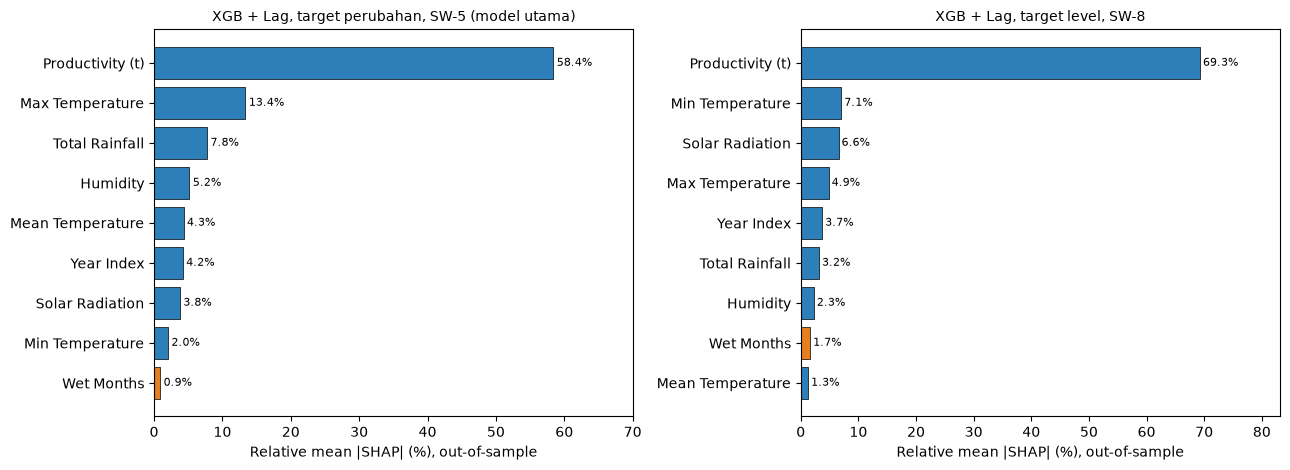

 -> Gambar tersimpan: feature_importance_xgb_lag.png


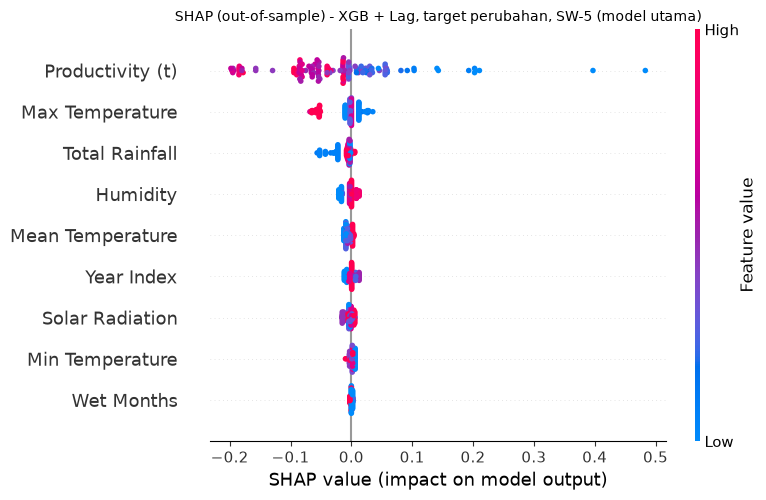

 -> Gambar tersimpan: shap_summary_xgb_lag.png


In [10]:
# =========================================================
# EKSPERIMEN 7: FEATURE IMPORTANCE & SHAP MODEL XGBOOST + LAG (OUT-OF-SAMPLE)
#   Model: hyperparameter nested Optuna per fold (sama dengan Eksperimen 6)
#   Gain     : dari model tiap fold (dirata-rata)
#   SHAP     : TreeExplainer pada baris UJI tiap fold (out-of-sample)
#   Permutasi: kenaikan RMSE saat fitur diacak di dalam baris uji (n_repeats=30)
# =========================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from IPython.display import display
from sklearn.metrics import mean_squared_error

print("=== EKSPERIMEN 7: FEATURE IMPORTANCE & SHAP XGBOOST + LAG ===")

LAG_DISPLAY = {
    'PRODUKTIVITAS_T': 'Productivity (t)', 'TOTAL_HUJAN': 'Total Rainfall', 'BULAN_BASAH': 'Wet Months',
    'AVG_RADIASI': 'Solar Radiation', 'AVG_KELEMBABAN': 'Humidity', 'MAX_SUHU_THN': 'Max Temperature',
    'MIN_SUHU_THN': 'Min Temperature', 'AVG_SUHU': 'Mean Temperature', 'YEAR_INDEX': 'Year Index',
}
DUMMY_COLS = [c for c in COLS_LAG if c.startswith('WADMKC_')]
DYN_COLS = [c for c in COLS_LAG if c not in DUMMY_COLS]

def lag_importance(window, mode, n_repeats=30, seed=42):
    rng = np.random.default_rng(seed)
    shap_parts, x_parts, gains, perms = [], [], [], []
    for tf in years_available[window:]:
        tr = [yr for yr in years_available if tf - window <= yr < tf]
        t_idx = df_master[df_master['YEAR_fitur'].isin(tr)].index
        v_idx = df_master[df_master['YEAR_fitur'] == tf].index
        prm = tune_lag(COLS_LAG, tr, mode)
        target = y if mode == 'L' else Y_DELTA
        m = xgb.XGBRegressor(**prm).fit(X_lag.loc[t_idx, COLS_LAG], target.loc[t_idx])
        Xv = X_lag.loc[v_idx, COLS_LAG]
        shap_parts.append(shap.TreeExplainer(m).shap_values(Xv))
        x_parts.append(Xv)
        g = m.get_booster().get_score(importance_type='total_gain')
        gains.append(pd.Series({c: g.get(c, 0.0) for c in COLS_LAG}))
        base_pred = m.predict(Xv) + (0 if mode == 'L' else Y_T.loc[v_idx].values)
        base_rmse = np.sqrt(mean_squared_error(y.loc[v_idx], base_pred))
        inc = {}
        for c in DYN_COLS:
            vals = []
            for _ in range(n_repeats):
                Xp = Xv.copy()
                Xp[c] = rng.permutation(Xp[c].values)
                pp = m.predict(Xp) + (0 if mode == 'L' else Y_T.loc[v_idx].values)
                vals.append(np.sqrt(mean_squared_error(y.loc[v_idx], pp)) - base_rmse)
            inc[c] = np.mean(vals)
        perms.append(pd.Series(inc))
    sv = np.vstack(shap_parts)
    Xall = pd.concat(x_parts)
    gain = pd.concat(gains, axis=1).mean(axis=1)
    perm = pd.concat(perms, axis=1).mean(axis=1)
    return sv, Xall, gain, perm

def importance_tables(sv, Xall, gain, perm, label):
    mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=COLS_LAG)
    grp = pd.DataFrame({
        'Kelompok Fitur': ['Produktivitas Tahun Lalu (Lag)', 'Identitas Kecamatan (27 Dummy)',
                           'Fitur Agroklimat (7 Variabel)', 'Tren Waktu (YEAR_INDEX)'],
        'cols': [['PRODUKTIVITAS_T'], DUMMY_COLS,
                 [c for c in DYN_COLS if c not in ('PRODUKTIVITAS_T', 'YEAR_INDEX')], ['YEAR_INDEX']],
    })
    grp['Gain (%)'] = grp['cols'].apply(lambda cs: gain[cs].sum() / gain.sum() * 100).round(2)
    grp['SHAP (%)'] = grp['cols'].apply(lambda cs: mean_abs[cs].sum() / mean_abs.sum() * 100).round(2)
    det = pd.DataFrame({
        'Fitur': [LAG_DISPLAY[c] for c in DYN_COLS],
        'Gain (%)': (gain[DYN_COLS] / gain[DYN_COLS].sum() * 100).round(2).values,
        'SHAP (%)': (mean_abs[DYN_COLS] / mean_abs[DYN_COLS].sum() * 100).round(2).values,
        'Mean |SHAP| (ton/ha)': mean_abs[DYN_COLS].round(4).values,
        'Permutasi OOS: kenaikan RMSE (ton/ha)': perm[DYN_COLS].round(4).values,
    }).sort_values('SHAP (%)', ascending=False).reset_index(drop=True)
    det.index = det.index + 1
    print(f"\nTABEL A. KONTRIBUSI KELOMPOK FITUR - {label}")
    display(grp.drop(columns='cols'))
    print(f"\nTABEL B. KONTRIBUSI FITUR DINAMIS (TANPA DUMMY KECAMATAN) - {label}")
    display(det)
    return grp, det, mean_abs

LAG_SHAP_CONFIGS = [(5, 'D', 'XGB + Lag, target perubahan, SW-5 (model utama)'),
                    (8, 'L', 'XGB + Lag, target level, SW-8')]
lag_shap_results = {}
for wl, mode, label in LAG_SHAP_CONFIGS:
    sv, Xall, gain, perm = lag_importance(wl, mode)
    grp, det, mean_abs = importance_tables(sv, Xall, gain, perm, label)
    lag_shap_results[label] = (sv, Xall, det)
    rk = det.index[det['Fitur'] == 'Wet Months'][0]
    print(f"-> Wet Months: peringkat SHAP {rk} dari {len(det)} fitur dinamis "
          f"({det.loc[rk, 'SHAP (%)']}% SHAP, permutasi {det.loc[rk, 'Permutasi OOS: kenaikan RMSE (ton/ha)']:+.4f} ton/ha); "
          f"n baris uji = {len(Xall)}.")

# ---------------------------------------------------------
# Visualisasi: bar SHAP fitur dinamis + beeswarm (model utama)
# ---------------------------------------------------------
main_label = LAG_SHAP_CONFIGS[0][2]
sv, Xall, det = lag_shap_results[main_label]
fig, axes = plt.subplots(1, len(LAG_SHAP_CONFIGS), figsize=(13, 4.8))
for ax, (_, _, label) in zip(axes, LAG_SHAP_CONFIGS):
    d = lag_shap_results[label][2].sort_values('SHAP (%)')
    colors = ['#e67e22' if f == 'Wet Months' else '#2c7fb8' for f in d['Fitur']]
    ax.barh(d['Fitur'], d['SHAP (%)'], color=colors, edgecolor='black', linewidth=0.5)
    for yy, v in enumerate(d['SHAP (%)']):
        ax.text(v + 0.5, yy, f"{v:.1f}%", va='center', fontsize=8)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('Relative mean |SHAP| (%), out-of-sample')
    ax.set_xlim(0, d['SHAP (%)'].max() * 1.2)
plt.tight_layout()
plt.savefig("feature_importance_xgb_lag.png", dpi=300, bbox_inches='tight')
plt.show()
print(" -> Gambar tersimpan: feature_importance_xgb_lag.png")

dyn_pos = [COLS_LAG.index(c) for c in DYN_COLS]
plt.figure()
shap.summary_plot(sv[:, dyn_pos], Xall[DYN_COLS].rename(columns=LAG_DISPLAY), show=False)
plt.title(f"SHAP (out-of-sample) - {main_label}", fontsize=10)
plt.tight_layout()
plt.savefig("shap_summary_xgb_lag.png", dpi=300, bbox_inches='tight')
plt.show()
print(" -> Gambar tersimpan: shap_summary_xgb_lag.png")


## EKSPERIMEN 9: ABLASI BLOK FITUR AGROKLIMAT
Membandingkan model utama tanpa fitur iklim (A), dengan 7 fitur agroklimat (B), dan tanpa bulan basah (C), dengan nested Optuna dan multi-seed.

In [11]:
# =========================================================
# EKSPERIMEN 9: ABLASI BLOK FITUR AGROKLIMAT PADA MODEL UTAMA (XGBOOST + LAG)
#   A : lag + dummy kecamatan + YEAR_INDEX (tanpa fitur iklim)
#   B : A + 7 fitur agroklimat (model utama)
#   C : B tanpa BULAN_BASAH
# Target perubahan produktivitas; nested Optuna per fold (seperti Eksperimen 6),
# ditambah replikasi multi-seed dengan hyperparameter default (subsample/colsample 0.8).
# =========================================================
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display
from sklearn.metrics import r2_score, mean_squared_error

print("=== EKSPERIMEN 9: ABLASI BLOK FITUR AGROKLIMAT (XGBOOST + LAG) ===")

COLS_A = [c for c in COLS_LAG if c not in X_COLS]
BLOCKS = {
    'A': ('Lag + kecamatan + tren (tanpa iklim)', COLS_A),
    'B': ('A + 7 fitur agroklimat (model utama)', COLS_LAG),
    'C': ('B tanpa BULAN_BASAH', COLS_LAG_NO_BB),
}
print("Jumlah fitur:", {k: len(v[1]) for k, v in BLOCKS.items()})

def r2_of(d):
    return r2_score(d['y_true'], d['pred'])

def rmse_of(d):
    return np.sqrt(mean_squared_error(d['y_true'], d['pred']))

# ---------------------------------------------------------
# 1. Nested Optuna per window
# ---------------------------------------------------------
rows, block_preds = [], {}
for wl in [5, 6, 7, 8]:
    for key, (label, cols) in BLOCKS.items():
        d = lag_walk_forward(wl, cols, 'D', tuned=True)
        block_preds[(wl, key)] = d
        rows.append({
            'Window': f'SW-{wl}', 'Konfigurasi': f'{key}. {label}',
            'Tahun Target': f"{d['YEAR_TARGET'].min()}-{d['YEAR_TARGET'].max()}",
            'R² (Pooled)': round(r2_of(d), 4),
            'RMSE (Ton/Ha)': round(rmse_of(d), 4),
            'Skill vs Persistence': round(skill_vs_persist(d), 3),
        })
df_block = pd.DataFrame(rows)
print("\nTABEL 1. ABLASI BLOK AGROKLIMAT - NESTED OPTUNA (TARGET PERUBAHAN)")
display(df_block)

# Selisih B - A per window + Wilcoxon pada |galat| per sampel
w_rows = []
for wl in [5, 6, 7, 8]:
    dA, dB = block_preds[(wl, 'A')], block_preds[(wl, 'B')]
    _, p = stats.wilcoxon(np.abs(dB['y_true'] - dB['pred']), np.abs(dA['y_true'] - dA['pred']))
    w_rows.append({'Window': f'SW-{wl}', 'n': len(dA),
                   'Δ R² (B - A)': round(r2_of(dB) - r2_of(dA), 4),
                   'Δ RMSE (B - A)': round(rmse_of(dB) - rmse_of(dA), 4),
                   'Wilcoxon p (|galat| B vs A)': round(p, 4)})
df_block_diff = pd.DataFrame(w_rows)
print("\nTABEL 2. SELISIH B (DENGAN IKLIM) - A (TANPA IKLIM), NESTED OPTUNA")
display(df_block_diff)
print("Catatan: galat dalam satu tahun saling berkorelasi, sehingga p-value Wilcoxon cenderung optimistis.")

# ---------------------------------------------------------
# 2. Multi-seed (hyperparameter default, subsample/colsample 0.8)
# ---------------------------------------------------------
ms_rows = []
for wl in [5, 8]:
    r2s = {k: [] for k in BLOCKS}
    for s in SEEDS:
        prm = {'random_state': s, 'subsample': 0.8, 'colsample_bytree': 0.8}
        for key, (_, cols) in BLOCKS.items():
            r2s[key].append(r2_of(lag_walk_forward(wl, cols, 'D', params=prm)))
    for first, second in [('B', 'A'), ('B', 'C')]:
        _, p = stats.ttest_rel(r2s[first], r2s[second])
        ms_rows.append({'Window': f'SW-{wl}', 'Perbandingan': f'{first} vs {second}',
                        'R² pertama (mean ± sd)': f"{np.mean(r2s[first]):.4f} ± {np.std(r2s[first], ddof=1):.4f}",
                        'R² kedua (mean ± sd)': f"{np.mean(r2s[second]):.4f} ± {np.std(r2s[second], ddof=1):.4f}",
                        'Δ R²': round(np.mean(r2s[first]) - np.mean(r2s[second]), 4),
                        'Seed Δ>0': f"{int(np.sum(np.array(r2s[first]) > np.array(r2s[second])))}/{len(SEEDS)}",
                        'p-value': round(p, 4)})
df_block_ms = pd.DataFrame(ms_rows)
print("\nTABEL 3. MULTI-SEED (10 SEED, HYPERPARAMETER DEFAULT, R² POOLED)")
display(df_block_ms)

# ---------------------------------------------------------
# 3. Kesimpulan otomatis
# ---------------------------------------------------------
sw5 = df_block[df_block['Window'] == 'SW-5'].copy()
sw5.index = sw5['Konfigurasi'].str[0]
print("\nKesimpulan (otomatis):")
print(f"1. SW-5 nested: R² A (tanpa iklim) = {sw5.loc['A', 'R² (Pooled)']}, "
      f"B (dengan iklim) = {sw5.loc['B', 'R² (Pooled)']}, C (tanpa bulan basah) = {sw5.loc['C', 'R² (Pooled)']}.")
print(f"2. Menambah fitur iklim (B vs A) menaikkan R² pada {int((df_block_diff['Δ R² (B - A)'] > 0).sum())} "
      f"dari {len(df_block_diff)} window (nested).")
for r in ms_rows:
    print(f"3. Multi-seed {r['Window']} {r['Perbandingan']}: Δ R² = {r['Δ R²']:+.4f}, p = {r['p-value']}.")


=== EKSPERIMEN 9: ABLASI BLOK FITUR AGROKLIMAT (XGBOOST + LAG) ===
Jumlah fitur: {'A': 29, 'B': 36, 'C': 35}



TABEL 1. ABLASI BLOK AGROKLIMAT - NESTED OPTUNA (TARGET PERUBAHAN)


,Window,Konfigurasi,Tahun Target,R² (Pooled),RMSE (Ton/Ha),Skill vs Persistence
0,SW-5,A. Lag + kecamatan + tren (tanpa iklim),2020-2024,0.7598,0.1919,0.098
1,SW-5,B. A + 7 fitur agroklimat (model utama),2020-2024,0.7377,0.2005,0.015
2,SW-5,C. B tanpa BULAN_BASAH,2020-2024,0.7031,0.2133,-0.115
3,SW-6,A. Lag + kecamatan + tren (tanpa iklim),2021-2024,0.7226,0.2033,-0.045
4,SW-6,B. A + 7 fitur agroklimat (model utama),2021-2024,0.7334,0.1993,-0.005
5,SW-6,C. B tanpa BULAN_BASAH,2021-2024,0.7359,0.1984,0.005
6,SW-7,A. Lag + kecamatan + tren (tanpa iklim),2022-2024,0.7124,0.2218,-0.138
7,SW-7,B. A + 7 fitur agroklimat (model utama),2022-2024,0.7249,0.2169,-0.088
8,SW-7,C. B tanpa BULAN_BASAH,2022-2024,0.7246,0.2171,-0.089
9,SW-8,A. Lag + kecamatan + tren (tanpa iklim),2023-2024,0.9443,0.0970,-0.896



TABEL 2. SELISIH B (DENGAN IKLIM) - A (TANPA IKLIM), NESTED OPTUNA


,Window,n,Δ R² (B - A),Δ RMSE (B - A),Wilcoxon p (|galat| B vs A)
0,SW-5,135,-0.0220,0.0086,0.0940
1,SW-6,108,0.0108,-0.0040,0.4942
2,SW-7,81,0.0126,-0.0049,0.0782
3,SW-8,54,0.0193,-0.0186,0.0002


Catatan: galat dalam satu tahun saling berkorelasi, sehingga p-value Wilcoxon cenderung optimistis.



TABEL 3. MULTI-SEED (10 SEED, HYPERPARAMETER DEFAULT, R² POOLED)


,Window,Perbandingan,R² pertama (mean ± sd),R² kedua (mean ± sd),Δ R²,Seed Δ>0,p-value
0,SW-5,B vs A,0.3307 ± 0.0706,0.5776 ± 0.0322,-0.2469,0/10,0.0000
1,SW-5,B vs C,0.3307 ± 0.0706,0.3275 ± 0.0761,0.0032,2/10,0.9132
2,SW-8,B vs A,0.6445 ± 0.1309,0.8020 ± 0.0621,-0.1575,1/10,0.0096
3,SW-8,B vs C,0.6445 ± 0.1309,0.6911 ± 0.0793,-0.0465,3/10,0.0795



Kesimpulan (otomatis):
1. SW-5 nested: R² A (tanpa iklim) = 0.7598, B (dengan iklim) = 0.7377, C (tanpa bulan basah) = 0.7031.
2. Menambah fitur iklim (B vs A) menaikkan R² pada 3 dari 4 window (nested).
3. Multi-seed SW-5 B vs A: Δ R² = -0.2469, p = 0.0.
3. Multi-seed SW-5 B vs C: Δ R² = +0.0032, p = 0.9132.
3. Multi-seed SW-8 B vs A: Δ R² = -0.1575, p = 0.0096.
3. Multi-seed SW-8 B vs C: Δ R² = -0.0465, p = 0.0795.


## EKSPERIMEN 10: EVALUASI LENGKAP MODEL UTAMA
SW-5..8 dan EW-7..9 dengan lag, R² per tahun, perbandingan 2023–2024, dan multi-seed dengan hyperparameter hasil nested tuning.

In [12]:
# =========================================================
# EKSPERIMEN 10: EVALUASI LENGKAP MODEL UTAMA (XGBOOST + LAG, TARGET PERUBAHAN, NESTED OPTUNA)
#   1. Per window: SW-5..8 dan EW-7..9 (EW = latih sekali pada 2014..cutoff, uji semua tahun sesudahnya;
#      angka di nama = panjang data latih dalam tahun). R², RMSE, MAE, MAPE + persistence,
#      serta perbandingan pada tahun target yang sama (2023-2024).
#   2. R² per tahun target, model utama vs persistence.
#   3. Multi-seed (10 seed) dengan hyperparameter HASIL NESTED TUNING tiap fold
#      (hanya random_state yang diganti) untuk konfigurasi A (tanpa iklim), B (model utama), C (tanpa bulan basah).
# =========================================================
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

print("=== EKSPERIMEN 10: EVALUASI LENGKAP MODEL UTAMA (XGBOOST + LAG) ===")
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
MATCHED = [2023, 2024]
EW_CUTOFFS = [2020, 2021, 2022]


def mets(d, col='pred'):
    return {'R2': r2_score(d['y_true'], d[col]),
            'RMSE': np.sqrt(mean_squared_error(d['y_true'], d[col])),
            'MAE': mean_absolute_error(d['y_true'], d[col]),
            'MAPE': mean_absolute_percentage_error(d['y_true'], d[col]) * 100}


def folds_of(kind, param):
    """Daftar (tahun fitur latih, tahun fitur uji) untuk satu skenario."""
    if kind == 'SW':
        return [([yr for yr in years_available if tf - param <= yr < tf], [tf]) for tf in years_available[param:]]
    tr = [yr for yr in years_available if yr <= param]
    return [(tr, [yr for yr in years_available if yr > param])]


SCEN = [(f'SW-{k}', 'SW', k) for k in [5, 6, 7, 8]] + \
       [(f"EW-{len([yr for yr in years_available if yr <= c])}", 'EW', c) for c in EW_CUTOFFS]

# Hyperparameter nested per fold (TPE seed 42 -> identik dengan Eksperimen 6/9), disimpan untuk multi-seed
TUNED = {}
def tuned_params(name, kind, param, key, cols):
    if (name, key) not in TUNED:
        TUNED[(name, key)] = [tune_lag(cols, tr, 'D') for tr, _ in folds_of(kind, param)]
    return TUNED[(name, key)]


def run_scenario(name, kind, param, key, cols, seed=None):
    rows = []
    for (tr, te), prm in zip(folds_of(kind, param), tuned_params(name, kind, param, key, cols)):
        prm = dict(prm) if seed is None else {**prm, 'random_state': seed}
        t_idx = df_master[df_master['YEAR_fitur'].isin(tr)].index
        v_idx = df_master[df_master['YEAR_fitur'].isin(te)].index
        rows.append(pd.DataFrame({
            'YEAR_TARGET': df_master.loc[v_idx, 'YEAR_fitur'].values + 1,
            'y_true': y.loc[v_idx].values,
            'pred_persist': Y_T.loc[v_idx].values,
            'pred': fit_predict(cols, t_idx, v_idx, prm, 'D'),
        }, index=v_idx))
    return pd.concat(rows)


# ---------------------------------------------------------
# 1. Kinerja per window (model utama = konfigurasi B)
# ---------------------------------------------------------
main_preds, rows = {}, []
for name, kind, param in SCEN:
    d = run_scenario(name, kind, param, 'B', COLS_LAG)
    main_preds[name] = d
    m, mp = mets(d), mets(d, 'pred_persist')
    dm = d[d['YEAR_TARGET'].isin(MATCHED)]
    n_train_years = len(folds_of(kind, param)[0][0])
    rows.append({
        'Skenario': name, 'Thn latih': n_train_years,
        'Tahun target': f"{d['YEAR_TARGET'].min()}-{d['YEAR_TARGET'].max()}", 'n uji': len(d),
        'R²': round(m['R2'], 3), 'RMSE': round(m['RMSE'], 3), 'MAE': round(m['MAE'], 3), 'MAPE (%)': round(m['MAPE'], 2),
        'R² Persist': round(mp['R2'], 3), 'MAE Persist': round(mp['MAE'], 3), 'MAPE Persist': round(mp['MAPE'], 2),
        'Skill': round(skill_vs_persist(d), 3),
        'R² 2023-24': round(r2_score(dm['y_true'], dm['pred']), 3) if dm['YEAR_TARGET'].nunique() == 2 else np.nan,
        'R² Persist 2023-24': round(r2_score(dm['y_true'], dm['pred_persist']), 3) if dm['YEAR_TARGET'].nunique() == 2 else np.nan,
    })
df_main = pd.DataFrame(rows)
print("\nTABEL 1. MODEL UTAMA PER SKENARIO (PRODUKTIVITAS, TON/HA; R² POOLED)")
print(df_main.to_string(index=False))
chk = df_main.loc[df_main['Skenario'] == 'SW-5', 'R²'].iloc[0]
print(f"Cek konsistensi: R² SW-5 = {chk} (Eksperimen 6: 0.738)")

# ---------------------------------------------------------
# 2. R² per tahun target
# ---------------------------------------------------------
yr = {}
for name, d in main_preds.items():
    yr[name] = d.groupby('YEAR_TARGET').apply(lambda g: r2_score(g['y_true'], g['pred']))
yr['Persistence'] = main_preds['SW-5'].groupby('YEAR_TARGET').apply(lambda g: r2_score(g['y_true'], g['pred_persist']))
df_year = pd.DataFrame(yr).T.round(3)
print("\nTABEL 2. R² PER TAHUN TARGET (MODEL UTAMA)")
print(df_year.to_string())

# ---------------------------------------------------------
# 3. Multi-seed dengan hyperparameter hasil nested tuning
# ---------------------------------------------------------
BLK = {'A': COLS_A, 'B': COLS_LAG, 'C': COLS_LAG_NO_BB}
ms_rows = []
for name, kind, param in SCEN:
    r2s = {k: [] for k in BLK}
    for s in SEEDS:
        for key, cols in BLK.items():
            r2s[key].append(mets(run_scenario(name, kind, param, key, cols, seed=s))['R2'])
    row = {'Skenario': name}
    for key in BLK:
        row[f'{key} mean±sd'] = f"{np.mean(r2s[key]):.3f} ± {np.std(r2s[key], ddof=1):.3f}"
    for other in ['A', 'C']:
        _, p = stats.ttest_rel(r2s['B'], r2s[other])
        row[f'Δ B-{other}'] = round(np.mean(r2s['B']) - np.mean(r2s[other]), 3)
        row[f'Seed B>{other}'] = f"{int(np.sum(np.array(r2s['B']) > np.array(r2s[other])))}/{len(SEEDS)}"
        row[f'p B-{other}'] = round(p, 4)
    ms_rows.append(row)
df_ms = pd.DataFrame(ms_rows)
print("\nTABEL 3. MULTI-SEED (10 SEED) DENGAN HYPERPARAMETER NESTED; A = tanpa iklim, B = model utama, C = tanpa bulan basah")
print(df_ms.to_string(index=False))

sub = [p['subsample'] for v in TUNED.values() for p in v]
col = [p['colsample_bytree'] for v in TUNED.values() for p in v]
print(f"\nRentang subsample hasil tuning: {min(sub):.2f}-{max(sub):.2f}; colsample_bytree: {min(col):.2f}-{max(col):.2f} "
      "(nilai < 1 membuat random_state berpengaruh).")

df_main.to_csv('Eksp10_model_utama_per_skenario.csv', index=False)
df_year.to_csv('Eksp10_r2_per_tahun.csv')
df_ms.to_csv('Eksp10_multiseed_nested.csv', index=False)
print("CSV tersimpan: Eksp10_model_utama_per_skenario.csv, Eksp10_r2_per_tahun.csv, Eksp10_multiseed_nested.csv")


=== EKSPERIMEN 10: EVALUASI LENGKAP MODEL UTAMA (XGBOOST + LAG) ===



TABEL 1. MODEL UTAMA PER SKENARIO (PRODUKTIVITAS, TON/HA; R² POOLED)
Skenario  Thn latih Tahun target  n uji    R²  RMSE   MAE  MAPE (%)  R² Persist  MAE Persist  MAPE Persist  Skill  R² 2023-24  R² Persist 2023-24
    SW-5          5    2020-2024    135 0.738 0.200 0.138      2.41       0.734        0.128          2.25  0.015       0.941               0.971
    SW-6          6    2021-2024    108 0.733 0.199 0.135      2.38       0.735        0.121          2.13 -0.005       0.956               0.971
    SW-7          7    2022-2024     81 0.725 0.217 0.138      2.46       0.747        0.121          2.14 -0.088       0.955               0.971
    SW-8          8    2023-2024     54 0.964 0.078 0.059      1.04       0.971        0.049          0.85 -0.238       0.964               0.971
    EW-7          7    2022-2024     81 0.716 0.221 0.146      2.61       0.747        0.121          2.14 -0.124       0.941               0.971
    EW-8          8    2023-2024     54 0.954 0.088 0.


TABEL 3. MULTI-SEED (10 SEED) DENGAN HYPERPARAMETER NESTED; A = tanpa iklim, B = model utama, C = tanpa bulan basah
Skenario     A mean±sd     B mean±sd     C mean±sd  Δ B-A Seed B>A  p B-A  Δ B-C Seed B>C  p B-C
    SW-5 0.757 ± 0.002 0.737 ± 0.004 0.700 ± 0.003 -0.020     0/10    0.0  0.037    10/10 0.0000
    SW-6 0.722 ± 0.001 0.733 ± 0.005 0.734 ± 0.004  0.011    10/10    0.0 -0.001     5/10 0.8240
    SW-7 0.713 ± 0.005 0.725 ± 0.004 0.719 ± 0.004  0.012    10/10    0.0  0.006     9/10 0.0062
    SW-8 0.940 ± 0.003 0.962 ± 0.001 0.956 ± 0.003  0.022    10/10    0.0  0.007    10/10 0.0000
    EW-7 0.723 ± 0.002 0.711 ± 0.005 0.711 ± 0.004 -0.012     0/10    0.0 -0.000     4/10 0.8407
    EW-8 0.932 ± 0.004 0.953 ± 0.002 0.948 ± 0.003  0.021    10/10    0.0  0.005    10/10 0.0003
    EW-9 0.943 ± 0.003 0.955 ± 0.001 0.951 ± 0.002  0.012    10/10    0.0  0.004    10/10 0.0000

Rentang subsample hasil tuning: 0.63-0.96; colsample_bytree: 0.51-0.99 (nilai < 1 membuat random_state ber

## EKSPERIMEN 11: PERBANDINGAN MODEL UTAMA DENGAN MODEL LAIN
Baseline naif, model tanpa lag, dan model lain dengan lag pada fold dan tahun uji yang sama (SW-5..8).

In [13]:
# =========================================================
# EKSPERIMEN 11: PERBANDINGAN MODEL UTAMA DENGAN MODEL LAIN (FOLD & TAHUN UJI YANG SAMA)
#   Semua model dievaluasi pada walk-forward true sliding window yang sama (SW-5..8).
#   Kelompok 1 - baseline naif : persistence, persistence + drift, rata-rata kecamatan
#   Kelompok 2 - tanpa lag     : regresi linear, Ridge, Random Forest, XGBoost default, XGBoost nested (target level)
#   Kelompok 3 - dengan lag    : fitur sama + produktivitas tahun t, target perubahan (ΔY):
#                                regresi linear, Ridge (alpha nested), Random Forest (nested Optuna),
#                                XGBoost default, XGBoost nested (model utama)
#   Semua hyperparameter hanya dipilih dari tahun di dalam jendela latih (validasi internal 2 tahun terakhir).
# =========================================================
import numpy as np
import pandas as pd
import optuna
import xgboost as xgb
from IPython.display import display
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

optuna.logging.set_verbosity(optuna.logging.WARNING)
import warnings
warnings.filterwarnings('ignore', message='.*sklearn.utils.parallel.delayed.*')
print("=== EKSPERIMEN 11: PERBANDINGAN MODEL UTAMA DENGAN MODEL LAIN ===")
COLS_NOLAG = list(X_processed.columns)
RIDGE_ALPHAS_11 = [0.01, 0.1, 1, 10, 100, 1000]


def make_est(kind, prm=None):
    prm = prm or {}
    if kind == 'lin':
        return LinearRegression()
    if kind == 'ridge':
        return make_pipeline(StandardScaler(), Ridge(alpha=prm.get('alpha', 1.0)))
    if kind == 'rf':
        return RandomForestRegressor(random_state=42, n_jobs=-1, **prm) if prm else \
            RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42, n_jobs=-1)
    if kind == 'xgb':
        return xgb.XGBRegressor(**(prm or {'random_state': 42}))


def fit_pred(kind, cols, lag, t_idx, v_idx, prm=None):
    """lag=True -> target ΔY, prediksi = Y_t + ΔY_hat (sama seperti model utama)."""
    target = Y_DELTA if lag else y
    m = make_est(kind, prm).fit(X_lag.loc[t_idx, cols], target.loc[t_idx])
    p = m.predict(X_lag.loc[v_idx, cols])
    return Y_T.loc[v_idx].values + p if lag else p


def inner_rmse(kind, cols, lag, train_years, prm):
    train_years = list(train_years)
    inner_w = len(train_years) - INNER_VAL_YEARS
    sq = []
    for k in range(INNER_VAL_YEARS):
        ti = df_master[df_master['YEAR_fitur'].isin(train_years[k:k + inner_w])].index
        vi = df_master[df_master['YEAR_fitur'] == train_years[k + inner_w]].index
        sq.append(mean_squared_error(y.loc[vi], fit_pred(kind, cols, lag, ti, vi, prm)))
    return np.sqrt(np.mean(sq))


def tune(kind, cols, lag, train_years):
    if kind == 'ridge':
        return min(({'alpha': a} for a in RIDGE_ALPHAS_11), key=lambda p: inner_rmse(kind, cols, lag, train_years, p))
    def objective(trial):
        prm = {'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=100),
               'max_depth': trial.suggest_int('max_depth', 2, 10),
               'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
               'max_features': trial.suggest_float('max_features', 0.3, 1.0)}
        return inner_rmse(kind, cols, lag, train_years, prm)
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=N_TRIALS)
    return study.best_params


def naive(name, t_idx, v_idx):
    if name == 'persist':
        return Y_T.loc[v_idx].values
    if name == 'drift':
        return Y_T.loc[v_idx].values + Y_DELTA.loc[t_idx].mean()
    mean_map = df_master.loc[t_idx].groupby('WADMKC')['PRODUKTIVITAS'].mean()
    return df_master.loc[v_idx, 'WADMKC'].map(mean_map).values


MODELS = [  # (label, kelompok, fungsi prediksi per fold)
    ('Persistence', 'Naif', lambda tr, t, v: naive('persist', t, v)),
    ('Persistence + drift', 'Naif', lambda tr, t, v: naive('drift', t, v)),
    ('Subdistrict training mean', 'Naif', lambda tr, t, v: naive('mean', t, v)),
    ('Linear regression', 'Tanpa lag', lambda tr, t, v: fit_pred('lin', COLS_NOLAG, False, t, v)),
    ('Ridge regression (nested α)', 'Tanpa lag', lambda tr, t, v: fit_pred('ridge', COLS_NOLAG, False, t, v, tune('ridge', COLS_NOLAG, False, tr))),
    ('Random forest (nested)', 'Tanpa lag', lambda tr, t, v: fit_pred('rf', COLS_NOLAG, False, t, v, tune('rf', COLS_NOLAG, False, tr))),
    ('XGBoost default', 'Tanpa lag', lambda tr, t, v: fit_pred('xgb', COLS_NOLAG, False, t, v)),
    ('XGBoost (nested)', 'Tanpa lag', lambda tr, t, v: fit_pred('xgb', COLS_NOLAG, False, t, v, tune_on_window(tr)[0])),
    ('Linear regression + lag', 'Dengan lag', lambda tr, t, v: fit_pred('lin', COLS_LAG, True, t, v)),
    ('Ridge regression + lag (nested α)', 'Dengan lag', lambda tr, t, v: fit_pred('ridge', COLS_LAG, True, t, v, tune('ridge', COLS_LAG, True, tr))),
    ('Random forest + lag (nested)', 'Dengan lag', lambda tr, t, v: fit_pred('rf', COLS_LAG, True, t, v, tune('rf', COLS_LAG, True, tr))),
    ('XGBoost + lag default', 'Dengan lag', lambda tr, t, v: fit_pred('xgb', COLS_LAG, True, t, v)),
]

comp_rows, comp_preds = [], {}
for wl in [5, 6, 7, 8]:
    main = lag_preds[(wl, 'D', True)]          # model utama (Eksperimen 6)
    d = main[['YEAR_TARGET', 'y_true', 'pred_persist']].copy()
    for label, grp, fn in MODELS:
        p = pd.Series(index=d.index, dtype=float)
        for tf in years_available[wl:]:
            tr = [yr for yr in years_available if tf - wl <= yr < tf]
            t_idx = df_master[df_master['YEAR_fitur'].isin(tr)].index
            v_idx = df_master[df_master['YEAR_fitur'] == tf].index
            p.loc[v_idx] = fn(tr, t_idx, v_idx)
        d[label] = p
    d['XGBoost + lag (nested) - MODEL UTAMA'] = main['pred']
    comp_preds[wl] = d
    labels = [m[0] for m in MODELS] + ['XGBoost + lag (nested) - MODEL UTAMA']
    groups = [m[1] for m in MODELS] + ['Dengan lag']
    mse_p = mean_squared_error(d['y_true'], d['pred_persist'])
    dm = d[d['YEAR_TARGET'].isin([2023, 2024])]
    for label, grp in zip(labels, groups):
        comp_rows.append({
            'Window': f'SW-{wl}', 'Tahun target': f"{d['YEAR_TARGET'].min()}-{d['YEAR_TARGET'].max()}",
            'Kelompok': grp, 'Model': label,
            'R²': round(r2_score(d['y_true'], d[label]), 3),
            'RMSE': round(np.sqrt(mean_squared_error(d['y_true'], d[label])), 3),
            'MAE': round(mean_absolute_error(d['y_true'], d[label]), 3),
            'MAPE (%)': round(mean_absolute_percentage_error(d['y_true'], d[label]) * 100, 2),
            'Skill': round(1 - mean_squared_error(d['y_true'], d[label]) / mse_p, 3),
            'R² 2023-24': round(r2_score(dm['y_true'], dm[label]), 3),
        })
df_comp = pd.DataFrame(comp_rows)
pd.set_option('display.width', 250)
for wl in [5, 6, 7, 8]:
    print(f"\nTABEL {wl - 4}. PERBANDINGAN MODEL - SW-{wl} (PRODUKTIVITAS, TON/HA; R² POOLED; Skill = 1 - MSE/MSE_persistence)")
    print(df_comp[df_comp['Window'] == f'SW-{wl}'].drop(columns=['Window']).to_string(index=False))

# R² per tahun target pada SW-5 untuk model-model dengan lag
d5 = comp_preds[5]
lag_labels = ['Persistence', 'Ridge regression + lag (nested α)', 'Random forest + lag (nested)',
              'Linear regression + lag', 'XGBoost + lag (nested) - MODEL UTAMA']
df_yr11 = pd.DataFrame({lab: d5.groupby('YEAR_TARGET').apply(lambda g, lab=lab: r2_score(g['y_true'], g[lab]))
                        for lab in lag_labels}).T.round(3)
print("\nTABEL 5. R² PER TAHUN TARGET, SW-5")
print(df_yr11.to_string())

df_comp.to_csv('Eksp11_perbandingan_model.csv', index=False)
df_yr11.to_csv('Eksp11_r2_per_tahun_sw5.csv')
print("CSV tersimpan: Eksp11_perbandingan_model.csv, Eksp11_r2_per_tahun_sw5.csv")


=== EKSPERIMEN 11: PERBANDINGAN MODEL UTAMA DENGAN MODEL LAIN ===



TABEL 1. PERBANDINGAN MODEL - SW-5 (PRODUKTIVITAS, TON/HA; R² POOLED; Skill = 1 - MSE/MSE_persistence)
Tahun target   Kelompok                                Model      R²  RMSE   MAE  MAPE (%)   Skill  R² 2023-24
   2020-2024       Naif                          Persistence   0.734 0.202 0.128      2.25   0.000       0.971
   2020-2024       Naif                  Persistence + drift   0.727 0.205 0.129      2.27  -0.027       0.978
   2020-2024       Naif            Subdistrict training mean   0.524 0.270 0.197      3.42  -0.788       0.623
   2020-2024  Tanpa lag                    Linear regression -10.510 1.328 0.949     16.36 -42.239       0.496
   2020-2024  Tanpa lag          Ridge regression (nested α)   0.465 0.286 0.216      3.75  -1.010       0.613
   2020-2024  Tanpa lag               Random forest (nested)   0.391 0.306 0.243      4.20  -1.289       0.557
   2020-2024  Tanpa lag                      XGBoost default   0.194 0.351 0.235      4.08  -2.028       0.516
   2020-

## EKSPERIMEN 12: VARIAN INDIKATOR BULAN BASAH PADA MODEL UTAMA
Tanpa, total, berurutan kalender, berurutan tahun musim, dan gabungan total + berurutan tahun musim pada XGBoost + lag (nested, 10 seed, 7 skenario).

In [14]:
# =========================================================
# EKSPERIMEN 12: VARIAN INDIKATOR BULAN BASAH PADA MODEL UTAMA (XGBOOST + LAG, TARGET PERUBAHAN)
#   0. Tanpa bulan basah
#   1. Total bulan basah tahunan (fitur model utama)
#   2. Bulan basah berurutan terpanjang - tahun kalender (Jan-Des tahun t)
#   3. Bulan basah berurutan terpanjang - tahun musim (Jul t-1 s.d. Jun t)
#   4. Total + berurutan tahun musim
# Fitur berurutan diambil dari Eksperimen 2 (df_m_eng). Setiap varian di-tuning nested sendiri (TPE seed 42),
# dievaluasi pada 7 skenario (SW-5..8, EW-7..9), lalu diulang 10 seed dengan hyperparameter hasil tuning.
# =========================================================
import numpy as np
import pandas as pd
import xgboost as xgb
from scipy import stats
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

print("=== EKSPERIMEN 12: VARIAN INDIKATOR BULAN BASAH PADA MODEL UTAMA ===")

# fitur berurutan dipetakan ke baris df_master lewat (kecamatan, tahun fitur)
key_eng = df_m_eng.set_index(['WADMKC', 'YEAR_fitur'])[['BULAN_BASAH_KONTINU', 'BB_KONTINU_MUSIM']]
key_eng = key_eng[~key_eng.index.duplicated()]
mi = pd.MultiIndex.from_arrays([df_master['WADMKC'], df_master['YEAR_fitur']])
X12 = X_lag.copy()
X12['BB_KALENDER'] = key_eng.reindex(mi)['BULAN_BASAH_KONTINU'].values
X12['BB_MUSIM'] = key_eng.reindex(mi)['BB_KONTINU_MUSIM'].values
print(f"Baris tanpa nilai BB_KALENDER: {int(X12['BB_KALENDER'].isna().sum())}; "
      f"tanpa BB_MUSIM: {int(X12['BB_MUSIM'].isna().sum())} (tahun 2014 tidak punya Jul-Des tahun sebelumnya).")
print(f"Korelasi total vs berurutan kalender: {X12['BULAN_BASAH'].corr(X12['BB_KALENDER']):.3f}; "
      f"total vs berurutan musim: {X12['BULAN_BASAH'].corr(X12['BB_MUSIM']):.3f}")

VARIANTS = {
    '0. Tanpa bulan basah': COLS_LAG_NO_BB,
    '1. Total bulan basah (model utama)': COLS_LAG,
    '2. Berurutan - tahun kalender': COLS_LAG_NO_BB + ['BB_KALENDER'],
    '3. Berurutan - tahun musim': COLS_LAG_NO_BB + ['BB_MUSIM'],
    '4. Total + berurutan tahun musim': COLS_LAG + ['BB_MUSIM'],
}


def fit_predict12(cols, t_idx, v_idx, params):
    m = xgb.XGBRegressor(**params).fit(X12.loc[t_idx, cols], Y_DELTA.loc[t_idx])
    return Y_T.loc[v_idx].values + m.predict(X12.loc[v_idx, cols])


def tune12(cols, train_years):
    train_years = list(train_years)
    inner_w = len(train_years) - INNER_VAL_YEARS
    def objective(trial):
        prm = suggest_params(trial)
        sq = []
        for k in range(INNER_VAL_YEARS):
            ti = df_master[df_master['YEAR_fitur'].isin(train_years[k:k + inner_w])].index
            vi = df_master[df_master['YEAR_fitur'] == train_years[k + inner_w]].index
            sq.append(mean_squared_error(y.loc[vi], fit_predict12(cols, ti, vi, prm)))
        return np.sqrt(np.mean(sq))
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=N_TRIALS)
    return {**study.best_params, 'random_state': 42}


TUNED12 = {}
def run12(name, kind, param, vname, cols, seed=None):
    folds = folds_of(kind, param)
    if (name, vname) not in TUNED12:
        TUNED12[(name, vname)] = [tune12(cols, tr) for tr, _ in folds]
    parts = []
    for (tr, te), prm in zip(folds, TUNED12[(name, vname)]):
        prm = dict(prm) if seed is None else {**prm, 'random_state': seed}
        t_idx = df_master[df_master['YEAR_fitur'].isin(tr)].index
        v_idx = df_master[df_master['YEAR_fitur'].isin(te)].index
        parts.append(pd.DataFrame({'y_true': y.loc[v_idx].values, 'pred': fit_predict12(cols, t_idx, v_idx, prm)}))
    return pd.concat(parts)


rows12 = []
for name, kind, param in SCEN:
    for vname, cols in VARIANTS.items():
        d = run12(name, kind, param, vname, cols)
        r2_seeds = [r2_score(*run12(name, kind, param, vname, cols, seed=s)[['y_true', 'pred']].T.values) for s in SEEDS]
        rows12.append({
            'Skenario': name, 'Varian': vname,
            'R²': round(r2_score(d['y_true'], d['pred']), 3),
            'RMSE': round(np.sqrt(mean_squared_error(d['y_true'], d['pred'])), 3),
            'MAE': round(mean_absolute_error(d['y_true'], d['pred']), 3),
            'MAPE (%)': round(mean_absolute_percentage_error(d['y_true'], d['pred']) * 100, 2),
            'R² 10 seed (mean)': round(np.mean(r2_seeds), 3),
            'R² 10 seed (sd)': round(np.std(r2_seeds, ddof=1), 3),
            '_r2_seeds': r2_seeds,
        })
df12 = pd.DataFrame(rows12)

# selisih tiap varian terhadap model utama (varian 1), per seed
cmp_rows = []
for name, _, _ in SCEN:
    base = df12[(df12['Skenario'] == name) & (df12['Varian'].str.startswith('1.'))]['_r2_seeds'].iloc[0]
    for _, r in df12[df12['Skenario'] == name].iterrows():
        if r['Varian'].startswith('1.'):
            continue
        diff = np.array(r['_r2_seeds']) - np.array(base)
        cmp_rows.append({'Skenario': name, 'Varian': r['Varian'], 'Δ R² vs total (mean)': round(diff.mean(), 3),
                         'Seed varian > total': f"{int((diff > 0).sum())}/{len(SEEDS)}"})
df12_cmp = pd.DataFrame(cmp_rows)
df12 = df12.drop(columns=['_r2_seeds'])

pd.set_option('display.width', 250)
print("\nTABEL 1. VARIAN BULAN BASAH - MODEL UTAMA (R²/RMSE/MAE/MAPE: seed 42 nested; R² 10 seed: mean ± sd)")
print(df12.to_string(index=False))
print("\nTABEL 2. SELISIH R² TERHADAP TOTAL BULAN BASAH (10 SEED)")
print(df12_cmp.to_string(index=False))
piv = df12.pivot(index='Varian', columns='Skenario', values='R² 10 seed (mean)')[[s for s, _, _ in SCEN]]
print("\nTABEL 3. R² RATA-RATA 10 SEED PER SKENARIO")
print(piv.to_string())
print("\nPeringkat rata-rata varian (1 = terbaik) lintas 7 skenario:")
print(piv.rank(ascending=False).mean(axis=1).sort_values().round(2).to_string())

df12.to_csv('Eksp12_varian_bulan_basah.csv', index=False)
df12_cmp.to_csv('Eksp12_selisih_vs_total.csv', index=False)
print("CSV tersimpan: Eksp12_varian_bulan_basah.csv, Eksp12_selisih_vs_total.csv")


=== EKSPERIMEN 12: VARIAN INDIKATOR BULAN BASAH PADA MODEL UTAMA ===
Baris tanpa nilai BB_KALENDER: 0; tanpa BB_MUSIM: 27 (tahun 2014 tidak punya Jul-Des tahun sebelumnya).
Korelasi total vs berurutan kalender: 0.471; total vs berurutan musim: -0.520



TABEL 1. VARIAN BULAN BASAH - MODEL UTAMA (R²/RMSE/MAE/MAPE: seed 42 nested; R² 10 seed: mean ± sd)
Skenario                             Varian    R²  RMSE   MAE  MAPE (%)  R² 10 seed (mean)  R² 10 seed (sd)
    SW-5               0. Tanpa bulan basah 0.703 0.213 0.148      2.57              0.700            0.003
    SW-5 1. Total bulan basah (model utama) 0.738 0.200 0.138      2.41              0.737            0.004
    SW-5      2. Berurutan - tahun kalender 0.664 0.227 0.151      2.63              0.647            0.013
    SW-5         3. Berurutan - tahun musim 0.681 0.221 0.149      2.59              0.678            0.011
    SW-5   4. Total + berurutan tahun musim 0.754 0.194 0.134      2.33              0.744            0.005
    SW-6               0. Tanpa bulan basah 0.736 0.198 0.128      2.25              0.734            0.004
    SW-6 1. Total bulan basah (model utama) 0.733 0.199 0.135      2.38              0.733            0.005
    SW-6      2. Berurutan - tahun 

## PROYEKSI PRODUKSI 2025
Model usulan: hybrid persistence + koreksi iklim (Eksperimen 5). Ketidakpastian memakai RMSE out-of-sample model hybrid dan asumsi galat produktivitas berkorelasi antar-kecamatan; XGBoost dan persistence murni ditampilkan sebagai pembanding.

In [15]:
# =========================================================
# STEP 10 : PREDIKSI PRODUKSI PADI 2025
# Model usulan: hybrid persistence + koreksi iklim (Eksperimen 5), dilatih pada
# jendela terakhir. XGBoost SW-8 & persistence murni ditampilkan sebagai pembanding.
# Galat produktivitas = RMSE out-of-sample model hybrid.
# Dilengkapi Geometric Mean, Delta Method, & Interval Ketidakpastian 95%
# =========================================================
print("10. Menghitung Prediksi Produksi 2025...")

X_pred_raw = df_input_2025[X_COLS + ['WADMKC']].copy()

X_pred = pd.get_dummies(
    X_pred_raw,
    columns=['WADMKC'],
    dtype=int
)

X_pred['YEAR_INDEX'] = 2024

X_pred = X_pred.reindex(
    columns=X_processed.columns,
    fill_value=0
)

final_train_idx = df_master[df_master['YEAR_fitur'].isin(FINAL_TRAIN_YEARS)].index
model_terbaik = xgb.XGBRegressor(**FINAL_PARAMS)
model_terbaik.fit(
    X_processed.loc[final_train_idx],
    y.loc[final_train_idx]
)

pred_produktivitas_xgb = model_terbaik.predict(X_pred)

# Model usulan: hybrid persistence + koreksi iklim (Eksperimen 5)
X_hyb_2025 = df_input_2025[X_COLS].copy()
X_hyb_2025['YEAR_fitur'] = 2024
pred_produktivitas_2025 = (
    df_input_2025['PRODUKTIVITAS'].values
    + hybrid_final_model.predict(X_hyb_2025[ANOM_COLS])
)

# RMSE produktivitas out-of-sample model hybrid (Eksperimen 5) - tidak diketik manual
rmse_model = RMSE_OOS_HYBRID

df_hasil_2025 = df_input_2025[['WADMKC']].copy().reset_index(drop=True)

df_hasil_2025['PREDIKSI_PRODUKTIVITAS']  = pred_produktivitas_2025
df_hasil_2025['PRODUKTIVITAS_2024']      = df_input_2025['PRODUKTIVITAS'].values
df_hasil_2025['LUAS_PANEN_2024']         = df_input_2025['LUAS_PANEN'].values
df_hasil_2025['RASIO_GM']                = df_input_2025['FAKTOR_KOREKSI'].values
df_hasil_2025['LUAS_PANEN_2025_EST']     = df_input_2025['LUAS_PANEN_2025_EST'].values
df_hasil_2025['PREDIKSI_PRODUKSI_TON']   = (
    pred_produktivitas_2025
    * df_hasil_2025['LUAS_PANEN_2025_EST'].values
)
df_hasil_2025['PRODUKSI_2024_AKTUAL']    = df_input_2025['PRODUKSI_PADI'].values
df_hasil_2025['DELTA_TON']               = (
    df_hasil_2025['PREDIKSI_PRODUKSI_TON']
    - df_hasil_2025['PRODUKSI_2024_AKTUAL']
)
df_hasil_2025['DELTA_PERSEN']            = (
    df_hasil_2025['DELTA_TON']
    / df_hasil_2025['PRODUKSI_2024_AKTUAL']
    * 100
).round(2)

# =========================================================
# PROPAGASI KETIDAKPASTIAN (DELTA METHOD)
# Var(P_i) = A_i^2 * Var(Y_i) + Y_i^2 * Var(A_i)
#   Var(Y_i) = RMSE_oos^2 ; Var(A_i) = (Luas_2024 * Std_Rasio)^2
# Tingkat kabupaten: galat produktivitas diasumsikan BERKORELASI PENUH antar-kecamatan
# (input iklim berasal dari grid yang sama), galat luas panen diasumsikan independen.
# Versi independen penuh ditampilkan sebagai pembanding (lebih sempit / optimistis).
# =========================================================
A_est = df_hasil_2025['LUAS_PANEN_2025_EST'].values
sigma_area_i = df_input_2025['LUAS_PANEN'].values * df_input_2025['STD_RASIO'].values
var_area_i = (pred_produktivitas_2025 ** 2) * (sigma_area_i ** 2)
var_prod_i = (A_est ** 2) * (rmse_model ** 2)
se_produksi_i = np.sqrt(var_prod_i + var_area_i)

df_hasil_2025['SE_PRODUKSI_TON'] = se_produksi_i
df_hasil_2025['CI_LOWER_95']     = df_hasil_2025['PREDIKSI_PRODUKSI_TON'] - 1.96 * se_produksi_i
df_hasil_2025['CI_UPPER_95']     = df_hasil_2025['PREDIKSI_PRODUKSI_TON'] + 1.96 * se_produksi_i

total_2025 = df_hasil_2025['PREDIKSI_PRODUKSI_TON'].sum()
total_2024 = df_hasil_2025['PRODUKSI_2024_AKTUAL'].sum()
se_total_kab = np.sqrt((A_est * rmse_model).sum() ** 2 + var_area_i.sum())
se_total_indep = np.sqrt(var_prod_i.sum() + var_area_i.sum())

ci_lower_kab_95 = total_2025 - 1.96 * se_total_kab
ci_upper_kab_95 = total_2025 + 1.96 * se_total_kab
ci_lower_kab_68 = total_2025 - se_total_kab
ci_upper_kab_68 = total_2025 + se_total_kab

# Pembanding: persistence murni & XGBoost (produktivitas x luas panen 2025 estimasi)
total_2025_persist = (df_hasil_2025['PRODUKTIVITAS_2024'] * A_est).sum()
total_2025_xgb = (pred_produktivitas_xgb * A_est).sum()

TARGET_ACUAN = 344243

def round_sig(x, base=1000):
    return int(round(x / base) * base)

print("\n========================================================")
print("  ESTIMASI PRODUKSI PADI BANYUMAS 2025")
print("  (Geometric Mean & Propagasi Ketidakpastian Delta Method)")
print("========================================================")
print(f"  RMSE produktivitas out-of-sample   : {rmse_model:.4f} ton/ha")
print(f"  Total Produksi 2024 (Aktual)       : {round_sig(total_2024):>10,} Ton")
print(f"  Estimasi Titik 2025 (dibulatkan)   : {round_sig(total_2025):>10,} Ton")
print(f"  Perubahan 2024 -> 2025             : {(total_2025-total_2024)/total_2024*100:+.1f}%")
print(f"  SE Gabungan (galat berkorelasi)    : {round_sig(se_total_kab, 100):>10,} Ton")
print(f"  Rentang 95% (galat berkorelasi)    : [{round_sig(ci_lower_kab_95):,} s.d. {round_sig(ci_upper_kab_95):,}] Ton")
print(f"  Rentang 95% (asumsi independen)    : [{round_sig(total_2025 - 1.96 * se_total_indep):,} s.d. "
      f"{round_sig(total_2025 + 1.96 * se_total_indep):,}] Ton")
print(f"  Pembanding persistence (Y_2024 x A_2025): {round_sig(total_2025_persist):,} Ton")
print(f"  Pembanding XGBoost SW-8 (FINAL_PARAMS)  : {round_sig(total_2025_xgb):,} Ton")
print(f"  Target Acuan                       : {TARGET_ACUAN:>10,} Ton")
print("========================================================")
if ci_lower_kab_95 <= total_2024 <= ci_upper_kab_95:
    print("  Catatan: produksi 2024 berada DI DALAM rentang 95%, sehingga perubahan 2024->2025")
    print("  tidak dapat dinyatakan sebagai penurunan/kenaikan yang meyakinkan.")
else:
    print("  Catatan: produksi 2024 berada di luar rentang 95%.")

print("\n  Rincian per Kecamatan (Presisi Wajar & Rentang 95% CI):")
df_tampil = df_hasil_2025[[
    'WADMKC',
    'PRODUKSI_2024_AKTUAL',
    'LUAS_PANEN_2025_EST',
    'PREDIKSI_PRODUKTIVITAS',
    'PREDIKSI_PRODUKSI_TON',
    'CI_LOWER_95',
    'CI_UPPER_95',
    'DELTA_PERSEN'
]].copy()

print(df_tampil.to_string(index=False, formatters={
    'PRODUKSI_2024_AKTUAL': lambda x: f"{x:,.0f}",
    'LUAS_PANEN_2025_EST': lambda x: f"{x:,.0f}",
    'PREDIKSI_PRODUKTIVITAS': lambda x: f"{x:.2f}",
    'PREDIKSI_PRODUKSI_TON': lambda x: f"{x:,.0f}",
    'CI_LOWER_95': lambda x: f"{x:,.0f}",
    'CI_UPPER_95': lambda x: f"{x:,.0f}",
    'DELTA_PERSEN': lambda x: f"{x:+.1f}%"
}))

# =========================================================
# STEP 11 : SIMPAN CSV
# =========================================================
df_hasil_2025.to_csv(
    "Prediksi_Produksi_Banyumas_2025.csv",
    index=False
)

print("\n  Hasil tersimpan: Prediksi_Produksi_Banyumas_2025.csv")


10. Menghitung Prediksi Produksi 2025...



  ESTIMASI PRODUKSI PADI BANYUMAS 2025
  (Geometric Mean & Propagasi Ketidakpastian Delta Method)
  RMSE produktivitas out-of-sample   : 0.0682 ton/ha
  Total Produksi 2024 (Aktual)       :    340,000 Ton
  Estimasi Titik 2025 (dibulatkan)   :    332,000 Ton
  Perubahan 2024 -> 2025             : -2.5%
  SE Gabungan (galat berkorelasi)    :      9,800 Ton
  Rentang 95% (galat berkorelasi)    : [313,000 s.d. 351,000] Ton
  Rentang 95% (asumsi independen)    : [314,000 s.d. 350,000] Ton
  Pembanding persistence (Y_2024 x A_2025): 331,000 Ton
  Pembanding XGBoost SW-8 (FINAL_PARAMS)  : 325,000 Ton
  Target Acuan                       :    344,243 Ton
  Catatan: produksi 2024 berada DI DALAM rentang 95%, sehingga perubahan 2024->2025
  tidak dapat dinyatakan sebagai penurunan/kenaikan yang meyakinkan.

  Rincian per Kecamatan (Presisi Wajar & Rentang 95% CI):
            WADMKC PRODUKSI_2024_AKTUAL LUAS_PANEN_2025_EST PREDIKSI_PRODUKTIVITAS PREDIKSI_PRODUKSI_TON CI_LOWER_95 CI_UPPER_95 DE

## EKSPERIMEN 8: PROYEKSI 2025 DENGAN MODEL UTAMA (XGBOOST + LAG)
Proyeksi produksi 2025 memakai XGBoost + lag (target perubahan, SW-5, nested Optuna); luas panen dan propagasi ketidakpastian sama dengan STEP 10.

In [16]:
# =========================================================
# EKSPERIMEN 8: PROYEKSI PRODUKSI 2025 DENGAN MODEL UTAMA XGBOOST + LAG
#   Model : target perubahan (ΔY), SW-5, hyperparameter nested Optuna yang dipilih
#           hanya dari jendela latih terakhir (fitur 2019-2023 -> target 2020-2024)
#   Galat : RMSE out-of-sample model yang sama (Eksperimen 6, SW-5, uji 2020-2024)
#   Luas panen & propagasi ketidakpastian identik dengan STEP 10
# =========================================================

import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import mean_squared_error

print("=== EKSPERIMEN 8: PROYEKSI 2025 - XGBOOST + LAG (MODEL UTAMA) ===")

MAIN_W, MAIN_MODE = 5, 'D'
main_train_years = list(years_available[-MAIN_W:])
main_t_idx = df_master[df_master['YEAR_fitur'].isin(main_train_years)].index
main_params = tune_lag(COLS_LAG, main_train_years, MAIN_MODE)
main_model = xgb.XGBRegressor(**main_params).fit(X_lag.loc[main_t_idx, COLS_LAG], Y_DELTA.loc[main_t_idx])

X_lag_2025 = X_pred.copy()
X_lag_2025['PRODUKTIVITAS_T'] = df_input_2025['PRODUKTIVITAS'].values
pred_lag_2025 = df_input_2025['PRODUKTIVITAS'].values + main_model.predict(X_lag_2025[COLS_LAG])

d_main = lag_preds[(MAIN_W, MAIN_MODE, True)]
rmse_main = float(np.sqrt(mean_squared_error(d_main['y_true'], d_main['pred'])))


# Metrik lengkap model utama (out-of-sample) & pembanding pada tahun uji yang sama
from IPython.display import display
main_metrics = pd.DataFrame([
    {'Model': 'XGBoost + Lag (target perubahan, SW-5, nested Optuna)', **summarize_predictions(d_main, 'pred')},
    {'Model': 'Naive Persistence (Y_t)', **summarize_predictions(d_main, 'pred_persist')},
])
print()
print("METRIK MODEL UTAMA (tahun target", sorted(d_main["YEAR_TARGET"].unique()), ", n =", len(d_main), ")")
display(main_metrics)
yr_main = pd.DataFrame([{'Tahun Target': yr, 'R² Model': round(r2_score(g['y_true'], g['pred']), 4),
                         'R² Persistence': round(r2_score(g['y_true'], g['pred_persist']), 4)}
                        for yr, g in d_main.groupby('YEAR_TARGET')])
display(yr_main)

A_est_lag = df_input_2025['LUAS_PANEN_2025_EST'].values
sigma_area_lag = df_input_2025['LUAS_PANEN'].values * df_input_2025['STD_RASIO'].values
var_area_lag = (pred_lag_2025 ** 2) * (sigma_area_lag ** 2)
var_prod_lag = (A_est_lag ** 2) * (rmse_main ** 2)

df_lag_2025 = df_input_2025[['WADMKC']].copy().reset_index(drop=True)
df_lag_2025['PRODUKTIVITAS_2024'] = df_input_2025['PRODUKTIVITAS'].values
df_lag_2025['PREDIKSI_PRODUKTIVITAS'] = pred_lag_2025
df_lag_2025['LUAS_PANEN_2025_EST'] = A_est_lag
df_lag_2025['PREDIKSI_PRODUKSI_TON'] = pred_lag_2025 * A_est_lag
df_lag_2025['PRODUKSI_2024_AKTUAL'] = df_input_2025['PRODUKSI_PADI'].values
se_i = np.sqrt(var_prod_lag + var_area_lag)
df_lag_2025['CI_LOWER_95'] = df_lag_2025['PREDIKSI_PRODUKSI_TON'] - 1.96 * se_i
df_lag_2025['CI_UPPER_95'] = df_lag_2025['PREDIKSI_PRODUKSI_TON'] + 1.96 * se_i
df_lag_2025['DELTA_PERSEN'] = ((df_lag_2025['PREDIKSI_PRODUKSI_TON'] / df_lag_2025['PRODUKSI_2024_AKTUAL'] - 1) * 100).round(2)

tot_lag = df_lag_2025['PREDIKSI_PRODUKSI_TON'].sum()
tot_2024 = df_lag_2025['PRODUKSI_2024_AKTUAL'].sum()
se_tot_lag = np.sqrt((A_est_lag * rmse_main).sum() ** 2 + var_area_lag.sum())
se_tot_indep = np.sqrt(var_prod_lag.sum() + var_area_lag.sum())

print(f"  Jendela latih final (tahun fitur)  : {min(main_train_years)}-{max(main_train_years)}")
print(f"  Hyperparameter final               : {main_params}")
print(f"  RMSE produktivitas out-of-sample   : {rmse_main:.4f} ton/ha")
print(f"  Total Produksi 2024 (Aktual)       : {tot_2024:,.2f} Ton")
print(f"  Estimasi Titik 2025                : {tot_lag:,.2f} Ton (dibulatkan {round_sig(tot_lag):,})")
print(f"  Perubahan 2024 -> 2025             : {(tot_lag - tot_2024) / tot_2024 * 100:+.2f}%")
print(f"  SE gabungan (galat berkorelasi)    : {se_tot_lag:,.0f} Ton")
print(f"  Rentang 95% (galat berkorelasi)    : [{round_sig(tot_lag - 1.96 * se_tot_lag):,} s.d. {round_sig(tot_lag + 1.96 * se_tot_lag):,}] Ton")
print(f"  Rentang 95% (asumsi independen)    : [{round_sig(tot_lag - 1.96 * se_tot_indep):,} s.d. {round_sig(tot_lag + 1.96 * se_tot_indep):,}] Ton")
print(f"  Pembanding persistence             : {(df_lag_2025['PRODUKTIVITAS_2024'] * A_est_lag).sum():,.0f} Ton")
print(f"  Total luas panen 2025 (estimasi)   : {A_est_lag.sum():,.0f} ha")
inside = (tot_lag - 1.96 * se_tot_lag) <= tot_2024 <= (tot_lag + 1.96 * se_tot_lag)
print(f"  Produksi 2024 di dalam rentang 95% : {'YA' if inside else 'TIDAK'}")
print(df_lag_2025.sort_values('PREDIKSI_PRODUKSI_TON', ascending=False).to_string(index=False, formatters={
    'PRODUKTIVITAS_2024': '{:.2f}'.format, 'PREDIKSI_PRODUKTIVITAS': '{:.2f}'.format,
    'LUAS_PANEN_2025_EST': '{:,.0f}'.format, 'PREDIKSI_PRODUKSI_TON': '{:,.0f}'.format,
    'PRODUKSI_2024_AKTUAL': '{:,.0f}'.format, 'CI_LOWER_95': '{:,.0f}'.format,
    'CI_UPPER_95': '{:,.0f}'.format, 'DELTA_PERSEN': '{:+.2f}%'.format}))
df_lag_2025.to_csv("Prediksi_Produksi_Banyumas_2025_XGB_Lag.csv", index=False)
print("\n  Hasil tersimpan: Prediksi_Produksi_Banyumas_2025_XGB_Lag.csv")

# Gambar proyeksi (peta, tren, small multiples) memakai model utama ini, bukan model hybrid STEP 10
df_hasil_2025 = df_lag_2025.copy()
se_total_kab = se_tot_lag
ci_lower_kab_95 = tot_lag - 1.96 * se_tot_lag
ci_upper_kab_95 = tot_lag + 1.96 * se_tot_lag
print("  Variabel gambar proyeksi kini mengacu ke model utama (XGBoost + lag).")


=== EKSPERIMEN 8: PROYEKSI 2025 - XGBOOST + LAG (MODEL UTAMA) ===



METRIK MODEL UTAMA (tahun target [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)] , n = 135 )


,Model,R² (Mean Fold),R² (Pooled),"RMSE (Ton/Ha, Pooled)",MAE (Ton/Ha),MAPE (%)
0,"XGBoost + Lag (target perubahan, SW-5, nested ...",0.7371,0.7377,0.2005,0.1384,2.41
1,Naive Persistence (Y_t),0.7266,0.7338,0.2020,0.1279,2.25


,Tahun Target,R² Model,R² Persistence
0,2020,0.7863,0.7310
1,2021,0.7158,0.6490
2,2022,0.3013,0.3116
3,2023,0.9041,0.9613
4,2024,0.9781,0.9800


  Jendela latih final (tahun fitur)  : 2019-2023
  Hyperparameter final               : {'max_depth': 4, 'learning_rate': 0.015438243476217663, 'n_estimators': 50, 'min_child_weight': 2, 'subsample': 0.9568644510611357, 'colsample_bytree': 0.5522103156363137, 'reg_lambda': 9.797962634737994, 'reg_alpha': 0.976451314405551, 'random_state': 42}
  RMSE produktivitas out-of-sample   : 0.2005 ton/ha
  Total Produksi 2024 (Aktual)       : 340,421.07 Ton
  Estimasi Titik 2025                : 331,623.09 Ton (dibulatkan 332,000)
  Perubahan 2024 -> 2025             : -2.58%
  SE gabungan (galat berkorelasi)    : 14,408 Ton
  Rentang 95% (galat berkorelasi)    : [303,000 s.d. 360,000] Ton
  Rentang 95% (asumsi independen)    : [313,000 s.d. 350,000] Ton
  Pembanding persistence             : 331,324 Ton
  Total luas panen 2025 (estimasi)   : 56,076 ha
  Produksi 2024 di dalam rentang 95% : YA
            WADMKC PRODUKTIVITAS_2024 PREDIKSI_PRODUKTIVITAS LUAS_PANEN_2025_EST PREDIKSI_PRODUKSI_TON 

VISUALISASI

In [17]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

feature Importance

Menampilkan BoxPlot Produktivitas...


 -> Gambar tersimpan: boxplot_produktivitas.png

Menganalisis Feature Importance (Total Gain) & Nilai SHAP...


C:\Users\acer\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)



TABEL 1. DEKOMPOSISI KONTRIBUSI FITUR MAKRO (SPASIAL VS IKLIM VS TEMPORAL)


,Kelompok Fitur,Peran Agronomi,XGBoost Gain (%),Mean |SHAP|,Kontribusi SHAP (%)
0,Identitas Kecamatan (27 Variabel Dummy),"Baseline Spasial (Tanah, Topografi, & Irigasi ...",72.64,0.4861,69.849998
1,Fitur Agroklimat (7 Variabel Cuaca),"Sinyal Dinamis Antartahun (Hujan, Suhu, Radiasi)",21.63,0.1804,25.920000
2,Tren Waktu Makro (YEAR_INDEX),Tren Teknologi Pertanian & Varietas Benih,5.72,0.0294,4.220000



TABEL 2. KONTRIBUSI RELATIF FITUR AGROKLIMAT & TEMPORAL


,DISPLAY_NAME,RELATIVE_GAIN,RELATIVE_SHAP
7,Total Rainfall,27.73,27.139999
6,Humidity,15.60,18.280001
5,Solar Radiation,7.33,14.710000
4,Year Index,20.92,14.010000
3,Min Temperature,12.74,10.700000
2,Mean Temperature,7.50,6.220000
1,Max Temperature,2.22,5.490000
0,Wet Months,5.96,3.450000



Wet Months: peringkat 7 (gain) dan 8 (SHAP) dari 8 fitur dinamis; share SHAP = 3.45%.
Identitas kecamatan = 69.85% SHAP, agroklimat = 25.92%, YEAR_INDEX = 4.22% (dihitung pada 54 baris uji out-of-sample).


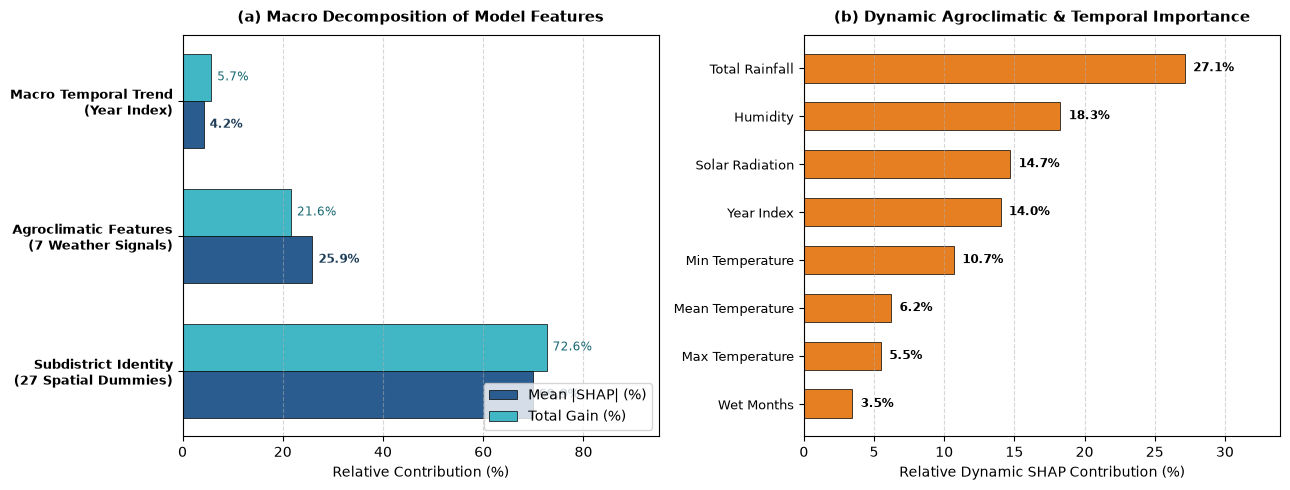


 -> Gambar tersimpan: feature_importance_agroclimatic.png


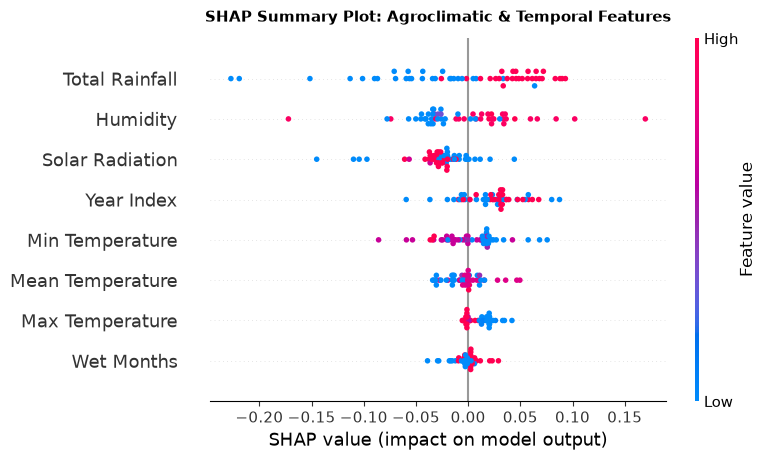

 -> Gambar tersimpan: shap_summary_agroclimatic.png


In [18]:
# =========================================================
# BOXPLOT PRODUKTIVITAS
# =========================================================
print("Menampilkan BoxPlot Produktivitas...")
plt.figure(figsize=(6, 5))
sns.boxplot(y=df_dataset['PRODUKTIVITAS'], color='skyblue')
plt.title('Boxplot Sebaran Data Produktivitas Padi', fontsize=12, fontweight='bold')
plt.ylabel('Ton/Hektar')
plt.tight_layout()
plt.savefig("boxplot_produktivitas.png", dpi=150)
plt.close()
print(" -> Gambar tersimpan: boxplot_produktivitas.png")

# =========================================================
# FEATURE IMPORTANCE & SHAP VALUE ANALYSIS
# Dekomposisi 35 Fitur: Spasial vs Agroklimat vs Temporal
# =========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

print("\nMenganalisis Feature Importance (Total Gain) & Nilai SHAP...")

# 1-2. Total Gain & SHAP OUT-OF-SAMPLE:
#      satu model XGBoost default per fold SW-8; SHAP dihitung pada tahun uji fold tersebut
#      (bukan pada data latih), gain dijumlahkan antar-fold.
import xgboost as xgb
SHAP_W = 8
feature_names = list(X_processed.columns)
importance_complete = {f: 0.0 for f in feature_names}
shap_blocks, data_blocks = [], []
for start_idx in range(len(years_available) - SHAP_W):
    tr_years = years_available[start_idx : start_idx + SHAP_W]
    te_year = years_available[start_idx + SHAP_W]
    t_idx = df_master[df_master['YEAR_fitur'].isin(tr_years)].index
    v_idx = df_master[df_master['YEAR_fitur'] == te_year].index
    m_fold = xgb.XGBRegressor(random_state=42).fit(X_processed.loc[t_idx], y.loc[t_idx])
    for key, value in m_fold.get_booster().get_score(importance_type="total_gain").items():
        if key in importance_complete:
            importance_complete[key] += value
    shap_blocks.append(shap.TreeExplainer(m_fold).shap_values(X_processed.loc[v_idx]))
    data_blocks.append(X_processed.loc[v_idx])

df_gain = pd.DataFrame(list(importance_complete.items()), columns=['feature', 'total_gain'])
df_gain['gain_pct'] = df_gain['total_gain'] / df_gain['total_gain'].sum() * 100

shap_values = np.vstack(shap_blocks)
X_shap = pd.concat(data_blocks)
mean_abs_shap = np.abs(shap_values).mean(axis=0)

df_shap = pd.DataFrame({
    'feature': feature_names,
    'mean_abs_shap': mean_abs_shap
})
df_shap['shap_pct'] = df_shap['mean_abs_shap'] / df_shap['mean_abs_shap'].sum() * 100

# 3. Pengelompokan Makro (Grouped Decomposition)
sub_gain = df_gain[df_gain['feature'].str.startswith('WADMKC_')]['gain_pct'].sum()
agro_gain = df_gain[df_gain['feature'].isin(X_COLS)]['gain_pct'].sum()
year_gain = df_gain[df_gain['feature'] == 'YEAR_INDEX']['gain_pct'].sum()

sub_shap = df_shap[df_shap['feature'].str.startswith('WADMKC_')]['shap_pct'].sum()
agro_shap = df_shap[df_shap['feature'].isin(X_COLS)]['shap_pct'].sum()
year_shap = df_shap[df_shap['feature'] == 'YEAR_INDEX']['shap_pct'].sum()

sub_sum_shap = df_shap[df_shap['feature'].str.startswith('WADMKC_')]['mean_abs_shap'].sum()
agro_sum_shap = df_shap[df_shap['feature'].isin(X_COLS)]['mean_abs_shap'].sum()
year_sum_shap = df_shap[df_shap['feature'] == 'YEAR_INDEX']['mean_abs_shap'].sum()

df_grouped = pd.DataFrame([
    {
        'Kelompok Fitur': 'Identitas Kecamatan (27 Variabel Dummy)',
        'Peran Agronomi': 'Baseline Spasial (Tanah, Topografi, & Irigasi Lokal)',
        'XGBoost Gain (%)': round(sub_gain, 2),
        'Mean |SHAP|': round(sub_sum_shap, 4),
        'Kontribusi SHAP (%)': round(sub_shap, 2)
    },
    {
        'Kelompok Fitur': 'Fitur Agroklimat (7 Variabel Cuaca)',
        'Peran Agronomi': 'Sinyal Dinamis Antartahun (Hujan, Suhu, Radiasi)',
        'XGBoost Gain (%)': round(agro_gain, 2),
        'Mean |SHAP|': round(agro_sum_shap, 4),
        'Kontribusi SHAP (%)': round(agro_shap, 2)
    },
    {
        'Kelompok Fitur': 'Tren Waktu Makro (YEAR_INDEX)',
        'Peran Agronomi': 'Tren Teknologi Pertanian & Varietas Benih',
        'XGBoost Gain (%)': round(year_gain, 2),
        'Mean |SHAP|': round(year_sum_shap, 4),
        'Kontribusi SHAP (%)': round(year_shap, 2)
    }
])

print("\n" + "=" * 80)
print("TABEL 1. DEKOMPOSISI KONTRIBUSI FITUR MAKRO (SPASIAL VS IKLIM VS TEMPORAL)")
print("=" * 80)
display(df_grouped)

# 4. Rincian Fitur Agroklimat & Temporal
selected_features = [
    'TOTAL_HUJAN', 'BULAN_BASAH', 'AVG_RADIASI', 'AVG_KELEMBABAN',
    'MAX_SUHU_THN', 'MIN_SUHU_THN', 'AVG_SUHU', 'YEAR_INDEX'
]
display_names = {
    'TOTAL_HUJAN': 'Total Rainfall',
    'BULAN_BASAH': 'Wet Months',
    'AVG_RADIASI': 'Solar Radiation',
    'AVG_KELEMBABAN': 'Humidity',
    'MAX_SUHU_THN': 'Max Temperature',
    'MIN_SUHU_THN': 'Min Temperature',
    'AVG_SUHU': 'Mean Temperature',
    'YEAR_INDEX': 'Year Index'
}

df_detail = pd.DataFrame({
    'FEATURE': selected_features,
    'DISPLAY_NAME': [display_names[f] for f in selected_features],
    'GAIN': [importance_complete.get(f, 0.0) for f in selected_features],
    'MEAN_SHAP': [df_shap[df_shap['feature'] == f]['mean_abs_shap'].values[0] for f in selected_features]
})
df_detail['RELATIVE_GAIN'] = df_detail['GAIN'] / df_detail['GAIN'].sum() * 100
df_detail['RELATIVE_SHAP'] = df_detail['MEAN_SHAP'] / df_detail['MEAN_SHAP'].sum() * 100
df_detail = df_detail.sort_values('RELATIVE_SHAP', ascending=True).reset_index(drop=True)

print("\n" + "=" * 80)
print("TABEL 2. KONTRIBUSI RELATIF FITUR AGROKLIMAT & TEMPORAL")
print("=" * 80)
display(df_detail[['DISPLAY_NAME', 'RELATIVE_GAIN', 'RELATIVE_SHAP']].sort_values('RELATIVE_SHAP', ascending=False).round(2))

rank_shap = df_detail.sort_values('RELATIVE_SHAP', ascending=False).reset_index(drop=True)
bb_shap_rank = int(rank_shap.index[rank_shap['FEATURE'] == 'BULAN_BASAH'][0]) + 1
rank_gain = df_detail.sort_values('RELATIVE_GAIN', ascending=False).reset_index(drop=True)
bb_gain_rank = int(rank_gain.index[rank_gain['FEATURE'] == 'BULAN_BASAH'][0]) + 1
bb_shap_share = df_detail.loc[df_detail['FEATURE'] == 'BULAN_BASAH', 'RELATIVE_SHAP'].iloc[0]
print(f"\nWet Months: peringkat {bb_gain_rank} (gain) dan {bb_shap_rank} (SHAP) dari {len(df_detail)} fitur dinamis; "
      f"share SHAP = {bb_shap_share:.2f}%.")
print(f"Identitas kecamatan = {sub_shap:.2f}% SHAP, agroklimat = {agro_shap:.2f}%, YEAR_INDEX = {year_shap:.2f}% "
      f"(dihitung pada {len(X_shap)} baris uji out-of-sample).")

# 5. Visualisasi Dual-Panel Figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

groups = [
    'Subdistrict Identity\n(27 Spatial Dummies)',
    'Agroclimatic Features\n(7 Weather Signals)',
    'Macro Temporal Trend\n(Year Index)'
]
gain_vals = [sub_gain, agro_gain, year_gain]
shap_vals = [sub_shap, agro_shap, year_shap]

y_pos = np.arange(len(groups))
height = 0.35

rects1 = ax1.barh(y_pos - height/2, shap_vals, height, label='Mean |SHAP| (%)', color='#2b5c8f', edgecolor='black', linewidth=0.5)
rects2 = ax1.barh(y_pos + height/2, gain_vals, height, label='Total Gain (%)', color='#41b6c4', edgecolor='black', linewidth=0.5)

ax1.set_yticks(y_pos)
ax1.set_yticklabels(groups, fontsize=9.5, fontweight='bold')
ax1.set_xlabel('Relative Contribution (%)', fontsize=10)
ax1.set_title('(a) Macro Decomposition of Model Features', fontsize=11, fontweight='bold', pad=10)
ax1.grid(axis='x', linestyle='--', alpha=0.5)
ax1.set_xlim(0, 95)
ax1.legend(loc='lower right', frameon=True)

for bar in rects1:
    w = bar.get_width()
    ax1.text(w + 1.2, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=8.5, color='#1e3d59', fontweight='bold')
for bar in rects2:
    w = bar.get_width()
    ax1.text(w + 1.2, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=8.5, color='#176873')

y_pos2 = np.arange(len(df_detail))
bars_det = ax2.barh(y_pos2, df_detail['RELATIVE_SHAP'], height=0.6, color='#e67e22', edgecolor='black', linewidth=0.5)
ax2.set_yticks(y_pos2)
ax2.set_yticklabels(df_detail['DISPLAY_NAME'], fontsize=9.5)
ax2.set_xlabel('Relative Dynamic SHAP Contribution (%)', fontsize=10)
ax2.set_title('(b) Dynamic Agroclimatic & Temporal Importance', fontsize=11, fontweight='bold', pad=10)
ax2.grid(axis='x', linestyle='--', alpha=0.5)
ax2.set_xlim(0, max(df_detail['RELATIVE_SHAP']) * 1.25)

for bar in bars_det:
    w = bar.get_width()
    ax2.text(w + 0.6, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.savefig("feature_importance_agroclimatic.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n -> Gambar tersimpan: feature_importance_agroclimatic.png")

# 6. Simpan SHAP Beeswarm Summary Plot
indices = [feature_names.index(f) for f in selected_features]
shap_sub = shap.Explanation(
    values=shap_values[:, indices],
    data=X_shap[selected_features].values,
    feature_names=[display_names[f] for f in selected_features]
)

plt.figure(figsize=(8, 5))
shap.plots.beeswarm(shap_sub, show=False, max_display=8)
plt.title('SHAP Summary Plot: Agroclimatic & Temporal Features', fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig("shap_summary_agroclimatic.png", dpi=300, bbox_inches='tight')
plt.show()
print(" -> Gambar tersimpan: shap_summary_agroclimatic.png")


HeatMap Korelasi

Menampilkan Heatmap Korelasi...


C:\Users\acer\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


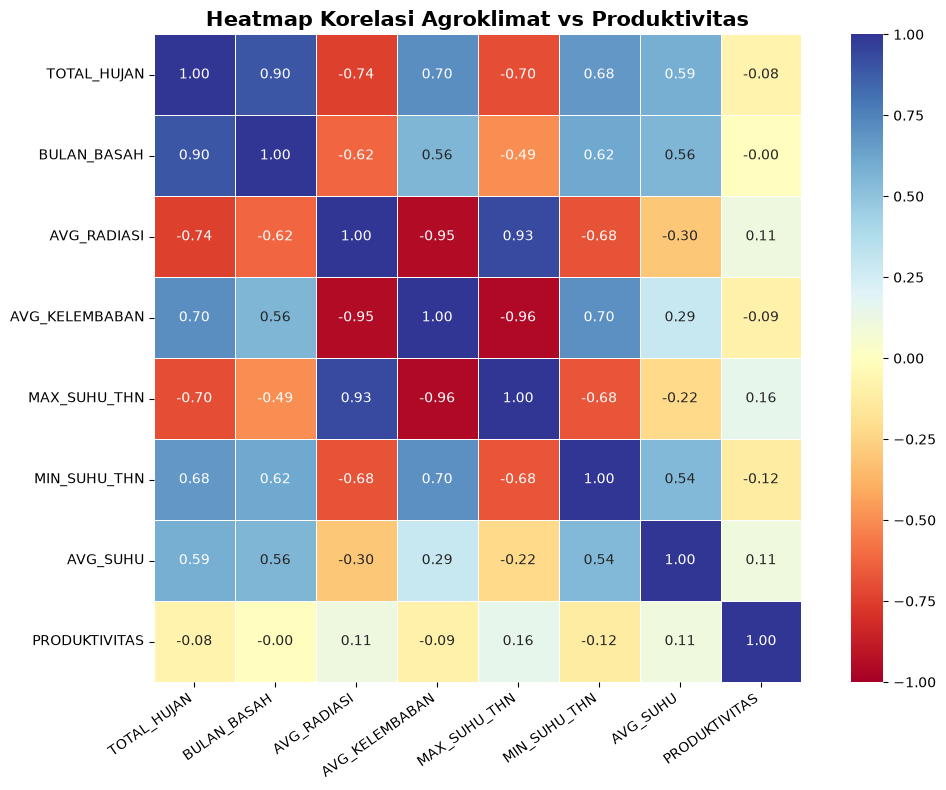

In [19]:
# =========================================================
# HEATMAP KORELASI
# =========================================================
print("Menampilkan Heatmap Korelasi...")

corr_cols = [
    'TOTAL_HUJAN',
    'BULAN_BASAH',
    'AVG_RADIASI',
    'AVG_KELEMBABAN',
    'MAX_SUHU_THN',
    'MIN_SUHU_THN',
    'AVG_SUHU',
    'PRODUKTIVITAS'
]

corr_matrix = df_dataset[corr_cols].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdYlBu',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.7,
    square=True
)

plt.title(
    'Heatmap Korelasi Agroklimat vs Produktivitas',
    fontsize=15,
    fontweight='bold'
)

plt.xticks(rotation=35, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "heatmap_korelasi_agroklimat.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Peta Prediksi Produksi 2025

Membangun Peta Prediksi...


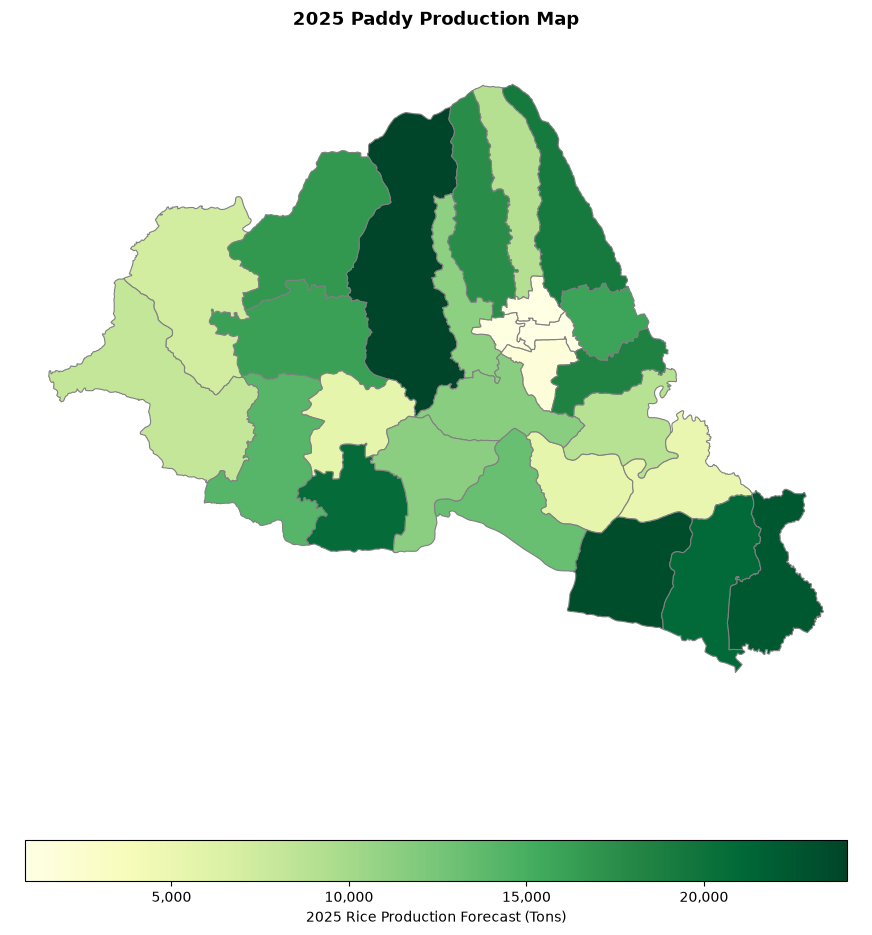

In [20]:
# =========================================================
# VISUALISASI PETA
# =========================================================
print("Membangun Peta Prediksi...")

gdf_peta = gdf_banyumas.merge(
    df_hasil_2025[
        ['WADMKC', 'PREDIKSI_PRODUKSI_TON']
    ],
    on='WADMKC',
    how='left'
)

fig, ax = plt.subplots(
    1,
    1,
    figsize=(14, 10)
)

gdf_peta.plot(
    column='PREDIKSI_PRODUKSI_TON',
    cmap='YlGn',
    linewidth=0.8,
    ax=ax,
    edgecolor='0.5',
    legend=True,
    legend_kwds={
        'label': '2025 Rice Production Forecast (Tons)',
        'orientation': 'horizontal',
        'shrink': 0.6,
        'format': mticker.FuncFormatter(
            lambda x, _: f"{x:,.0f}"
        )
    }
)

ax.set_title(
    f"2025 Paddy Production Map\n",
    fontsize=13,
    fontweight='bold'
)

ax.axis('off')

plt.tight_layout()

plt.savefig(
    "peta_prediksi_2025.png",
    dpi=150,
    bbox_inches='tight'
)

plt.show()

Membangun Grafik Tren Produksi Historis & Prediksi 2025...


C:\Users\acer\AppData\Local\Temp\ipykernel_2708\3716212739.py:9: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_historical_annual.rename(columns={'PRODUKSI_PADI': 'PRODUKSI_TON'}, inplace=True)


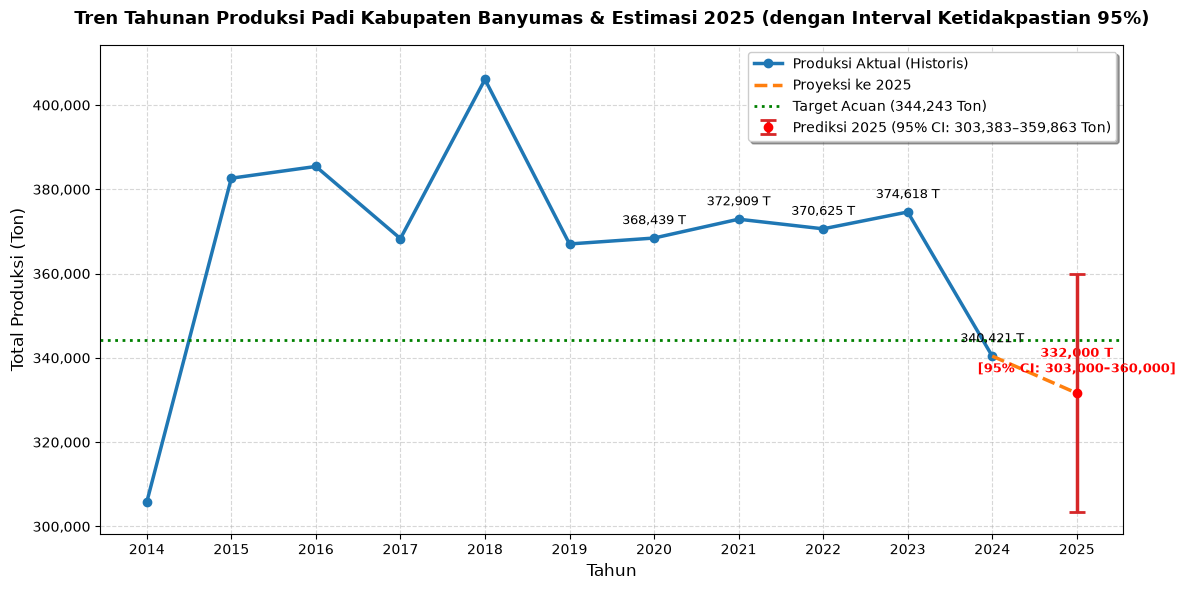

 -> Gambar tersimpan: tren_forecasting_produksi_2025.png


In [21]:
# =========================================================
# VISUALISASI FORECASTING (LINE CHART)
# Dilengkapi Rentang Ketidakpastian 95% (Error Bar)
# =========================================================
print("Membangun Grafik Tren Produksi Historis & Prediksi 2025...")

# Agregasi data historis tahunan dari dataset master
df_historical_annual = df_dataset.groupby('YEAR')['PRODUKSI_PADI'].sum().reset_index()
df_historical_annual.rename(columns={'PRODUKSI_PADI': 'PRODUKSI_TON'}, inplace=True)
df_historical_annual['STATUS'] = 'Aktual'

# Ambil total prediksi 2025
total_prediksi_2025 = df_hasil_2025['PREDIKSI_PRODUKSI_TON'].sum()
df_pred_2025 = pd.DataFrame({
    'YEAR': [2025],
    'PRODUKSI_TON': [total_prediksi_2025],
    'STATUS': ['Prediksi 2025']
})

# Gabungkan untuk plotting kontinu
df_plot = pd.concat([df_historical_annual, df_pred_2025], ignore_index=True).sort_values('YEAR')

# Buat plot
plt.figure(figsize=(12, 6))

# Plot garis aktual
df_aktual = df_plot[df_plot['STATUS'] == 'Aktual']
plt.plot(df_aktual['YEAR'], df_aktual['PRODUKSI_TON'], marker='o', color='#1f77b4', linewidth=2.5, label='Produksi Aktual (Historis)')

# Plot garis penghubung dari tahun terakhir aktual ke tahun prediksi 2025
df_transition = df_plot[df_plot['YEAR'].isin([df_aktual['YEAR'].max(), 2025])]
plt.plot(df_transition['YEAR'], df_transition['PRODUKSI_TON'], linestyle='--', color='#ff7f0e', linewidth=2.5, label='Proyeksi ke 2025')

# Plot titik prediksi 2025 dengan rentang ketidakpastian 95% (error bar)
plt.errorbar(
    2025, total_prediksi_2025,
    yerr=1.96 * se_total_kab,
    fmt='o', color='red', ecolor='#d62728', elinewidth=2.5, capsize=6, capthick=2,
    zorder=6, label=f'Prediksi 2025 (95% CI: {ci_lower_kab_95:,.0f}–{ci_upper_kab_95:,.0f} Ton)'
)

# Tambahkan garis horizontal target acuan
plt.axhline(y=TARGET_ACUAN, color='green', linestyle=':', linewidth=2, label=f'Target Acuan ({TARGET_ACUAN:,} Ton)')

# Teks nilai di atas titik-titik beberapa tahun terakhir dan prediksi
for idx, row in df_plot.iterrows():
    if row['YEAR'] >= 2020:
        if row['YEAR'] == 2025:
            text_str = f"{round(row['PRODUKSI_TON'], -3):,.0f} T\n[95% CI: {round(ci_lower_kab_95, -3):,.0f}–{round(ci_upper_kab_95, -3):,.0f}]"
            plt.annotate(
                text_str,
                (row['YEAR'], row['PRODUKSI_TON']),
                textcoords="offset points",
                xytext=(0, 15),
                ha='center',
                fontsize=9,
                fontweight='bold',
                color='red'
            )
        else:
            plt.annotate(
                f"{row['PRODUKSI_TON']:,.0f} T",
                (row['YEAR'], row['PRODUKSI_TON']),
                textcoords="offset points",
                xytext=(0, 10),
                ha='center',
                fontsize=9
            )

# Batas sumbu Y mencakup seluruh titik historis dan rentang 95%
y_lo_tren = min(df_plot['PRODUKSI_TON'].min(), ci_lower_kab_95)
y_hi_tren = max(df_plot['PRODUKSI_TON'].max(), ci_upper_kab_95)
plt.ylim(y_lo_tren - 0.05 * (y_hi_tren - y_lo_tren), y_hi_tren + 0.08 * (y_hi_tren - y_lo_tren))

# Dekorasi Chart
plt.title('Tren Tahunan Produksi Padi Kabupaten Banyumas & Estimasi 2025 (dengan Interval Ketidakpastian 95%)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Total Produksi (Ton)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(df_plot['YEAR'])
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.legend(loc='best', frameon=True, shadow=True)
plt.tight_layout()

# Simpan Gambar
plt.savefig("tren_forecasting_produksi_2025.png", dpi=150, bbox_inches='tight')
plt.show()

print(" -> Gambar tersimpan: tren_forecasting_produksi_2025.png")


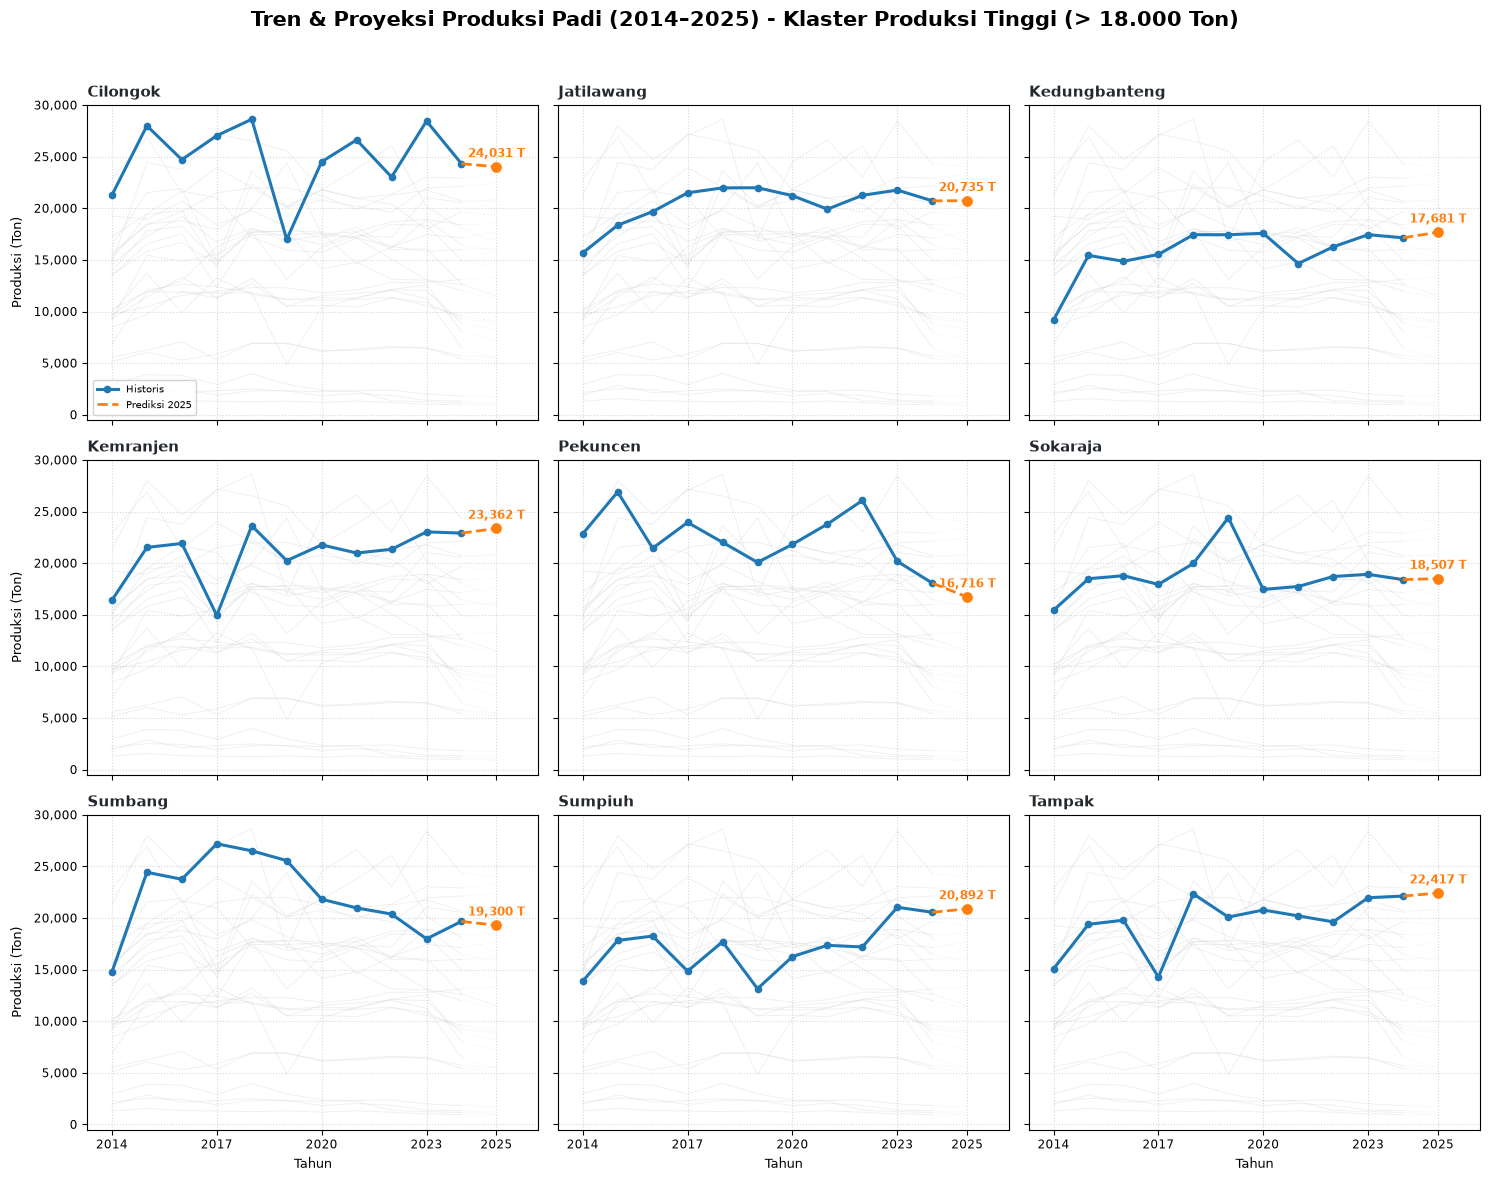

-> Berhasil menyimpan file visualisasi klaster: small_multiples_globalghost_klaster_produksi_tinggi.png


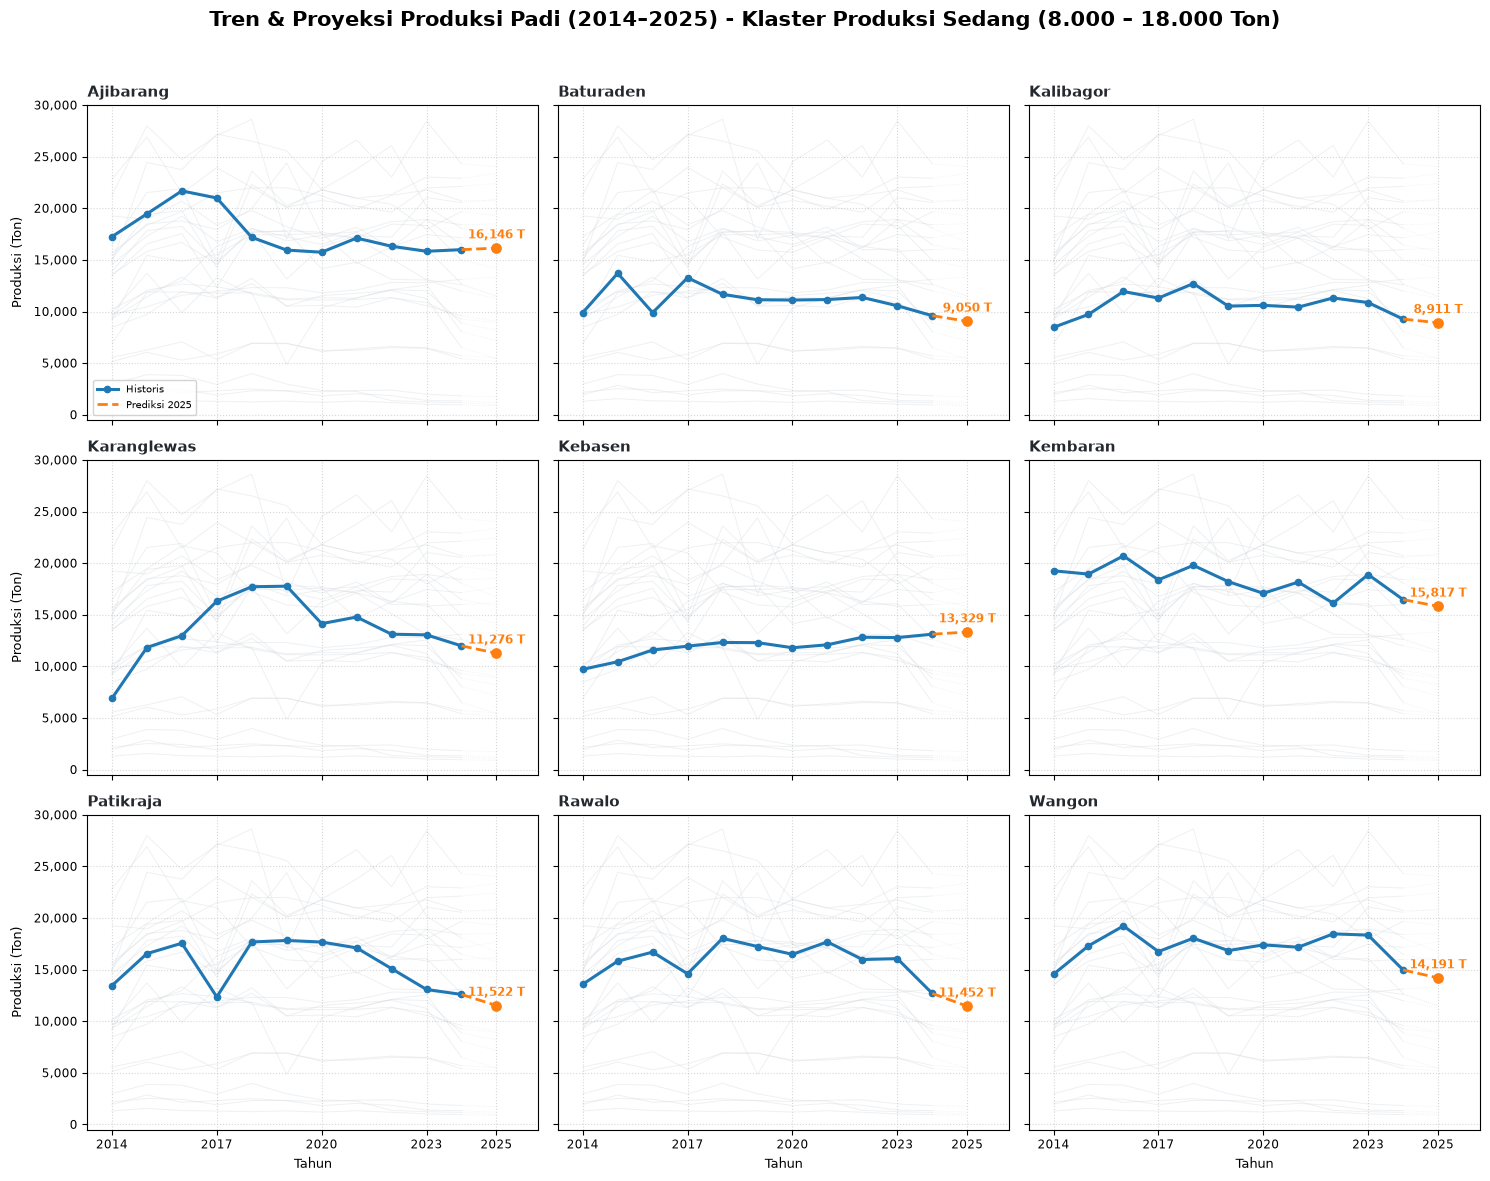

-> Berhasil menyimpan file visualisasi klaster: small_multiples_globalghost_klaster_produksi_sedang.png


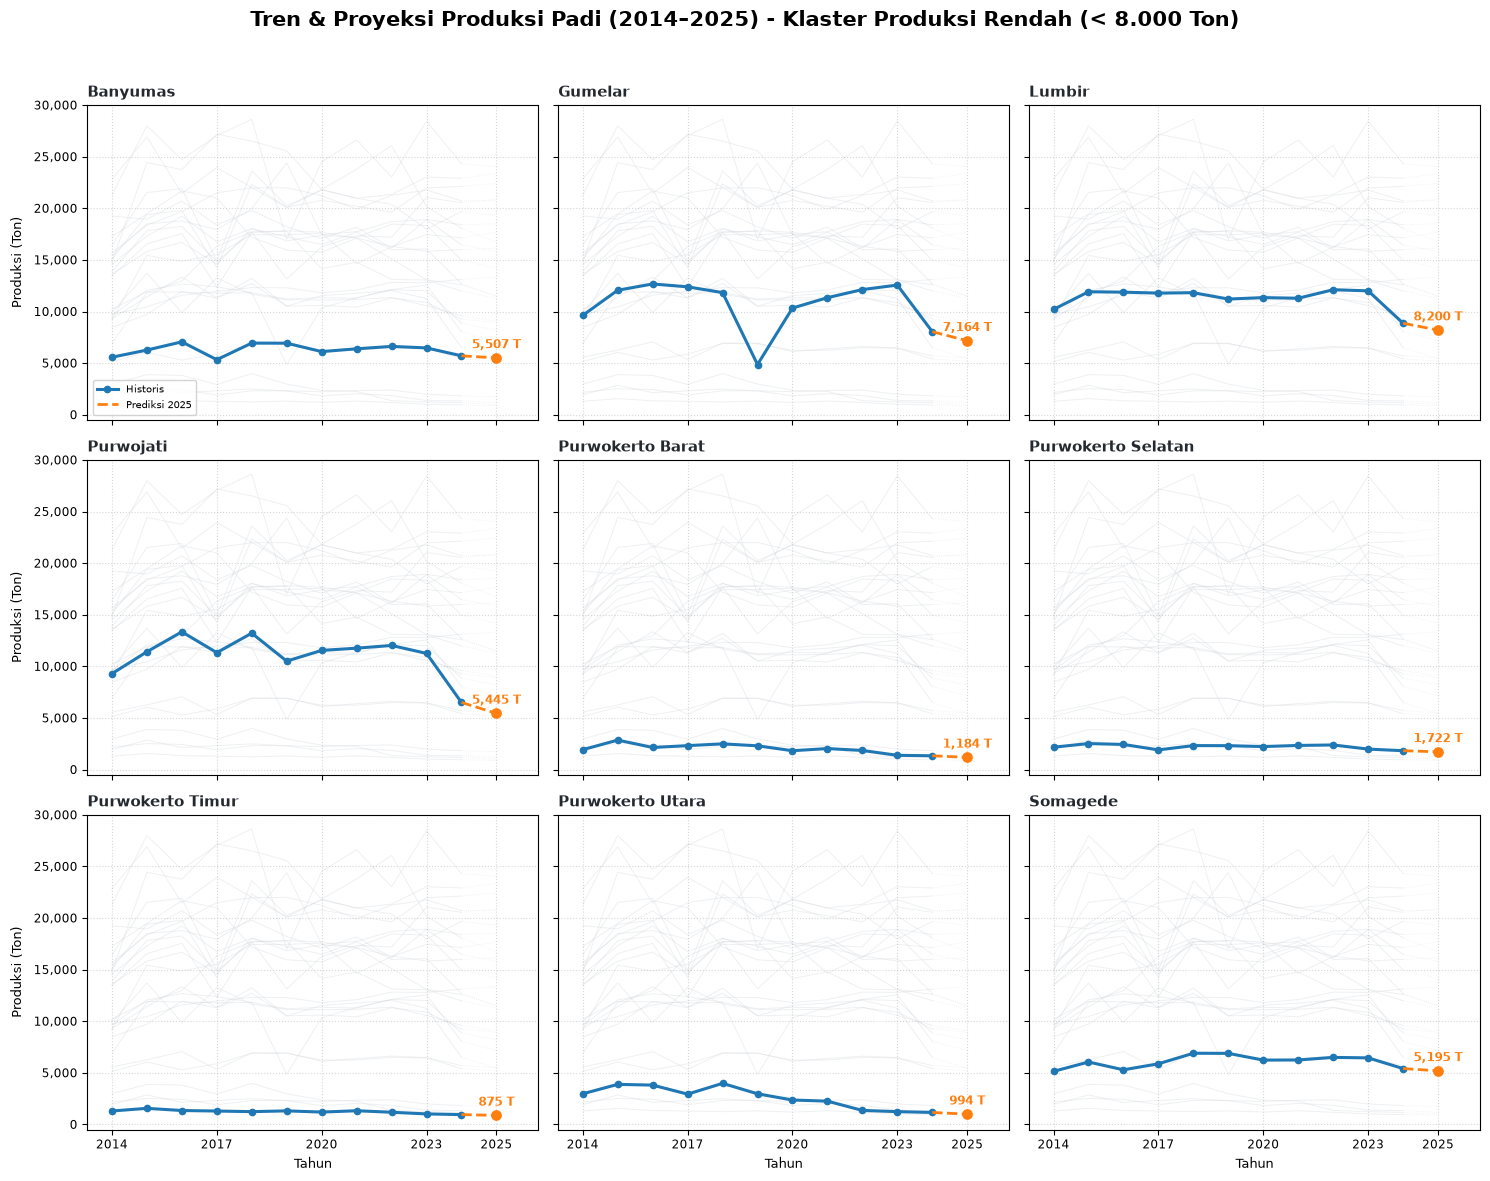

-> Berhasil menyimpan file visualisasi klaster: small_multiples_globalghost_klaster_produksi_rendah.png


In [22]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Definisikan konstanta warna dan variabel pendukung
GHOST_COLOR = '#d1d5db'  # Abu-abu muda transparan untuk ghost lines
MAIN_COLOR = '#1f77b4'   # Biru untuk historis kecamatan target
FORECAST_COLOR = '#ff7f0e' # Oranye untuk prediksi 2025

all_kecamatan = df_dataset['WADMKC'].unique()

# 2. Kelompokkan kecamatan ke dalam 3 Klaster berdasarkan Prediksi Produksi 2025
df_sort = df_hasil_2025.sort_values(by='PREDIKSI_PRODUKSI_TON', ascending=False).reset_index(drop=True)

# Bagi rata menjadi 3 kelompok (masing-masing 9 kecamatan)
klaster_tinggi = list(df_sort.loc[0:8, 'WADMKC'])
klaster_sedang = list(df_sort.loc[9:17, 'WADMKC'])
klaster_rendah = list(df_sort.loc[18:26, 'WADMKC'])

klasters = {
    'Klaster Produksi Tinggi': klaster_tinggi,
    'Klaster Produksi Sedang': klaster_sedang,
    'Klaster Produksi Rendah': klaster_rendah
}

KLASTER_DESKRIPSI = {
    'Klaster Produksi Tinggi': '> 18.000 Ton',
    'Klaster Produksi Sedang': '8.000 – 18.000 Ton',
    'Klaster Produksi Rendah': '< 8.000 Ton'
}

# 3. Loop Visualisasi Small Multiples per Klaster
for klaster_name, kec_list in klasters.items():
    kec_sorted = sorted(kec_list)
    fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharex=True, sharey=True)
    axes_flat = axes.flatten()

    desc_ambang = KLASTER_DESKRIPSI.get(klaster_name, '')

    fig.suptitle(
        f"Tren & Proyeksi Produksi Padi (2014–2025) - {klaster_name} ({desc_ambang})",
        fontsize=15,
        fontweight='bold',
        y=0.98
    )

    for i, target_kec in enumerate(kec_sorted):
        ax = axes_flat[i]

        # --- A. GHOST LINES DARI SELURUH 27 KECAMATAN ---
        for other_kec in all_kecamatan:
            if other_kec == target_kec:
                continue
            df_other = df_dataset[df_dataset['WADMKC'] == other_kec][['YEAR', 'PRODUKSI_PADI']].sort_values('YEAR')
            pred_other = df_hasil_2025[df_hasil_2025['WADMKC'] == other_kec]['PREDIKSI_PRODUKSI_TON'].values[0]

            # Plot garis abu-abu tipis sebagai latar belakang pembanding
            ax.plot(df_other['YEAR'], df_other['PRODUKSI_PADI'],
                    color=GHOST_COLOR, linewidth=0.7, alpha=0.35, zorder=1)
            ax.plot([df_other['YEAR'].iloc[-1], 2025], [df_other['PRODUKSI_PADI'].iloc[-1], pred_other],
                    linestyle=':', color=GHOST_COLOR, linewidth=0.6, alpha=0.35, zorder=1)

        # --- B. TARGET KECAMATAN UTAMA ---
        df_target_plot = df_dataset[df_dataset['WADMKC'] == target_kec][['YEAR', 'PRODUKSI_PADI']].sort_values('YEAR')
        pred_target = df_hasil_2025[df_hasil_2025['WADMKC'] == target_kec]['PREDIKSI_PRODUKSI_TON'].values[0]
        last_yr = df_target_plot['YEAR'].iloc[-1]
        last_val = df_target_plot['PRODUKSI_PADI'].iloc[-1]

        # Plot Data Historis Utama
        ax.plot(df_target_plot['YEAR'], df_target_plot['PRODUKSI_PADI'],
                marker='o', markersize=4.5, color=MAIN_COLOR, linewidth=2.2, zorder=3, label='Historis')

        # Plot Garis Proyeksi ke 2025
        ax.plot([last_yr, 2025], [last_val, pred_target],
                linestyle='--', color=FORECAST_COLOR, linewidth=2.0, zorder=3, label='Prediksi 2025')
        ax.scatter(2025, pred_target, color=FORECAST_COLOR, s=45, zorder=4)

        # Label angka prediksi di atas titik 2025
        ax.annotate(f"{pred_target:,.0f} T",
                    (2025, pred_target),
                    textcoords="offset points", xytext=(0, 7), ha='center',
                    fontsize=8.5, fontweight='bold', color=FORECAST_COLOR)

        # Atur estetika subplot
        ax.set_title(target_kec, fontsize=11, fontweight='bold', pad=6, loc='left', color='#24292f')
        ax.grid(True, linestyle=':', alpha=0.5)
        ax.set_xticks([2014, 2017, 2020, 2023, 2025])
        ax.set_xlim(2013.3, 2026.2)
        ax.tick_params(axis='both', which='major', labelsize=8.5)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f" {x:,.0f}"))

        if i % 3 == 0:
            ax.set_ylabel("Produksi (Ton)", fontsize=9.5)
        if i >= 6:
            ax.set_xlabel("Tahun", fontsize=9.5)
        if i == 0:
            ax.legend(loc='lower left', fontsize=7.5, frameon=True, framealpha=0.85)

    # Hapus subplot sisa jika jumlah kecamatan kurang dari 9
    for j in range(len(kec_sorted), 9):
        fig.delaxes(axes_flat[j])

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    file_name = f"small_multiples_globalghost_{klaster_name.lower().replace(' ', '_')}.png"
    plt.savefig(file_name, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"-> Berhasil menyimpan file visualisasi klaster: {file_name}")


Membangun Actual vs. Predicted untuk skenario terbaik...
Best window: 8 tahun


POOLED METRICS PADA SKENARIO TERBAIK (SW-8):
[1] PRODUKTIVITAS (Target Model Sebenarnya):
    R²   : 0.5659
    RMSE : 0.2707 ton/ha
    MAE  : 0.1941 ton/ha
    MAPE : 3.36%

[2] PRODUKSI (Hasil Konversi Luas Panen):
    R²   : 0.9906
    RMSE : 692.81 ton
    MAE  : 460.54 ton
    Jumlah titik sampel uji: 54


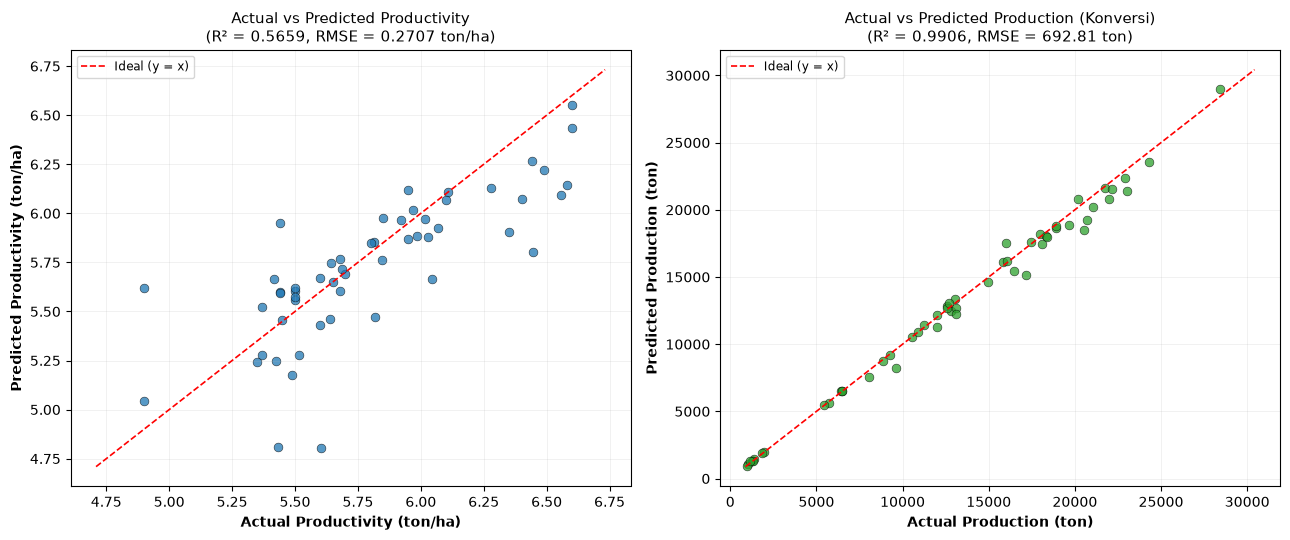

Gambar tersimpan: actual_vs_predicted_sw_best.png


In [23]:
# =========================================================
# ACTUAL VS PREDICTED - BEST TRUE SLIDING WINDOW
# Evaluasi pada Produktivitas (ton/ha) & Produksi (ton)
# =========================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error
)

print("Membangun Actual vs. Predicted untuk skenario terbaik...")

# ---------------------------------------------------------
# 1. Ambil ukuran window dari skenario terbaik
# ---------------------------------------------------------
if "True Sliding Window" not in rasio_terbaik:
    raise ValueError(
        f"Skenario terbaik bukan True Sliding Window: {rasio_terbaik}"
    )

match = re.search(r"(\d+)\s*Thn", rasio_terbaik)

if match is None:
    raise ValueError(
        f"Ukuran window tidak dapat dibaca dari: {rasio_terbaik}"
    )

BEST_WINDOW = int(match.group(1))

print(f"Best window: {BEST_WINDOW} tahun")

# ---------------------------------------------------------
# 2. Walk-forward ulang dan simpan seluruh prediksi test
# ---------------------------------------------------------
actual_prodv_all = []
predicted_prodv_all = []
actual_ton_all = []
predicted_ton_all = []
district_all = []
target_year_all = []

for start_idx in range(len(years_available) - BEST_WINDOW):

    train_years = years_available[
        start_idx : start_idx + BEST_WINDOW
    ]

    test_year = years_available[
        start_idx + BEST_WINDOW
    ]

    train_idx = df_master[
        df_master["YEAR_fitur"].isin(train_years)
    ].index

    test_idx = df_master[
        df_master["YEAR_fitur"] == test_year
    ].index

    if len(train_idx) == 0 or len(test_idx) == 0:
        continue

    X_train = X_processed.loc[train_idx]
    X_test = X_processed.loc[test_idx]

    y_train = y.loc[train_idx]
    y_test = y.loc[test_idx]

    # Model baru untuk setiap fold
    model_fold = xgb.XGBRegressor(
        random_state=42
    )

    model_fold.fit(
        X_train,
        y_train
    )

    # Prediksi produktivitas
    pred_productivity = model_fold.predict(
        X_test
    )

    # Konversi ke produksi (ton)
    harvest_area = df_master.loc[
        test_idx,
        "LUAS_PANEN"
    ].values

    actual_ton = (
        y_test.values * harvest_area
    )

    predicted_ton = (
        pred_productivity * harvest_area
    )

    # Simpan produktivitas
    actual_prodv_all.extend(y_test.values)
    predicted_prodv_all.extend(pred_productivity)

    # Simpan produksi
    actual_ton_all.extend(actual_ton)
    predicted_ton_all.extend(predicted_ton)

    district_all.extend(
        df_master.loc[
            test_idx,
            "WADMKC"
        ].values
    )

    target_year_all.extend(
        df_master.loc[
            test_idx,
            "YEAR_TARGET"
        ].values
    )

# ---------------------------------------------------------
# 3. Simpan hasil seluruh fold ke DataFrame
# ---------------------------------------------------------
df_actual_pred_best = pd.DataFrame({
    "KECAMATAN": district_all,
    "YEAR_TARGET": target_year_all,
    "ACTUAL_PRODUCTIVITY": actual_prodv_all,
    "PREDICTED_PRODUCTIVITY": predicted_prodv_all,
    "ACTUAL_PRODUCTION": actual_ton_all,
    "PREDICTED_PRODUCTION": predicted_ton_all
})

# ---------------------------------------------------------
# 4. Hitung pooled metrics
# ---------------------------------------------------------
# A. PRODUKTIVITAS (ton/ha)
r2_prodv_pooled = r2_score(
    df_actual_pred_best["ACTUAL_PRODUCTIVITY"],
    df_actual_pred_best["PREDICTED_PRODUCTIVITY"]
)
rmse_prodv_pooled = np.sqrt(
    mean_squared_error(
        df_actual_pred_best["ACTUAL_PRODUCTIVITY"],
        df_actual_pred_best["PREDICTED_PRODUCTIVITY"]
    )
)
mae_prodv_pooled = mean_absolute_error(
    df_actual_pred_best["ACTUAL_PRODUCTIVITY"],
    df_actual_pred_best["PREDICTED_PRODUCTIVITY"]
)
mape_prodv_pooled = (
    mean_absolute_percentage_error(
        df_actual_pred_best["ACTUAL_PRODUCTIVITY"],
        df_actual_pred_best["PREDICTED_PRODUCTIVITY"]
    ) * 100
)

# B. PRODUKSI (ton)
r2_ton_pooled = r2_score(
    df_actual_pred_best["ACTUAL_PRODUCTION"],
    df_actual_pred_best["PREDICTED_PRODUCTION"]
)
rmse_ton_pooled = np.sqrt(
    mean_squared_error(
        df_actual_pred_best["ACTUAL_PRODUCTION"],
        df_actual_pred_best["PREDICTED_PRODUCTION"]
    )
)
mae_ton_pooled = mean_absolute_error(
    df_actual_pred_best["ACTUAL_PRODUCTION"],
    df_actual_pred_best["PREDICTED_PRODUCTION"]
)

print("=" * 55)
print("POOLED METRICS PADA SKENARIO TERBAIK (SW-8):")
print("=" * 55)
print(f"[1] PRODUKTIVITAS (Target Model Sebenarnya):")
print(f"    R²   : {r2_prodv_pooled:.4f}")
print(f"    RMSE : {rmse_prodv_pooled:.4f} ton/ha")
print(f"    MAE  : {mae_prodv_pooled:.4f} ton/ha")
print(f"    MAPE : {mape_prodv_pooled:.2f}%")
print(f"\n[2] PRODUKSI (Hasil Konversi Luas Panen):")
print(f"    R²   : {r2_ton_pooled:.4f}")
print(f"    RMSE : {rmse_ton_pooled:,.2f} ton")
print(f"    MAE  : {mae_ton_pooled:,.2f} ton")
print(f"    Jumlah titik sampel uji: {len(df_actual_pred_best)}")
print("=" * 55)

# ---------------------------------------------------------
# 5. Scatter Plot Side-by-Side (Produktivitas & Produksi)
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))

# Plot 1: Produktivitas (ton/ha)
ax1.scatter(
    df_actual_pred_best["ACTUAL_PRODUCTIVITY"],
    df_actual_pred_best["PREDICTED_PRODUCTIVITY"],
    s=40,
    color="#1f77b4",
    alpha=0.75,
    edgecolors="black",
    linewidths=0.4
)
min_v = min(df_actual_pred_best["ACTUAL_PRODUCTIVITY"].min(), df_actual_pred_best["PREDICTED_PRODUCTIVITY"].min()) * 0.98
max_v = max(df_actual_pred_best["ACTUAL_PRODUCTIVITY"].max(), df_actual_pred_best["PREDICTED_PRODUCTIVITY"].max()) * 1.02
ax1.plot([min_v, max_v], [min_v, max_v], linestyle="--", linewidth=1.2, color="red", label="Ideal (y = x)")
ax1.set_xlabel("Actual Productivity (ton/ha)", fontsize=10, fontweight="bold")
ax1.set_ylabel("Predicted Productivity (ton/ha)", fontsize=10, fontweight="bold")
ax1.set_title(f"Actual vs Predicted Productivity\n(R² = {r2_prodv_pooled:.4f}, RMSE = {rmse_prodv_pooled:.4f} ton/ha)", fontsize=11)
ax1.legend(frameon=True, fontsize=8.5)
ax1.grid(alpha=0.25, linewidth=0.5)

# Plot 2: Produksi (ton)
ax2.scatter(
    df_actual_pred_best["ACTUAL_PRODUCTION"],
    df_actual_pred_best["PREDICTED_PRODUCTION"],
    s=40,
    color="#2ca02c",
    alpha=0.75,
    edgecolors="black",
    linewidths=0.4
)
min_p = min(df_actual_pred_best["ACTUAL_PRODUCTION"].min(), df_actual_pred_best["PREDICTED_PRODUCTION"].min()) * 0.95
max_p = max(df_actual_pred_best["ACTUAL_PRODUCTION"].max(), df_actual_pred_best["PREDICTED_PRODUCTION"].max()) * 1.05
ax2.plot([min_p, max_p], [min_p, max_p], linestyle="--", linewidth=1.2, color="red", label="Ideal (y = x)")
ax2.set_xlabel("Actual Production (ton)", fontsize=10, fontweight="bold")
ax2.set_ylabel("Predicted Production (ton)", fontsize=10, fontweight="bold")
ax2.set_title(f"Actual vs Predicted Production (Konversi)\n(R² = {r2_ton_pooled:.4f}, RMSE = {rmse_ton_pooled:,.2f} ton)", fontsize=11)
ax2.legend(frameon=True, fontsize=8.5)
ax2.grid(alpha=0.25, linewidth=0.5)

plt.tight_layout()
plt.savefig("actual_vs_predicted_sw_best.png", dpi=300, bbox_inches="tight")
plt.show()

print("Gambar tersimpan: actual_vs_predicted_sw_best.png")


Membangun Actual vs. Predicted untuk model utama...


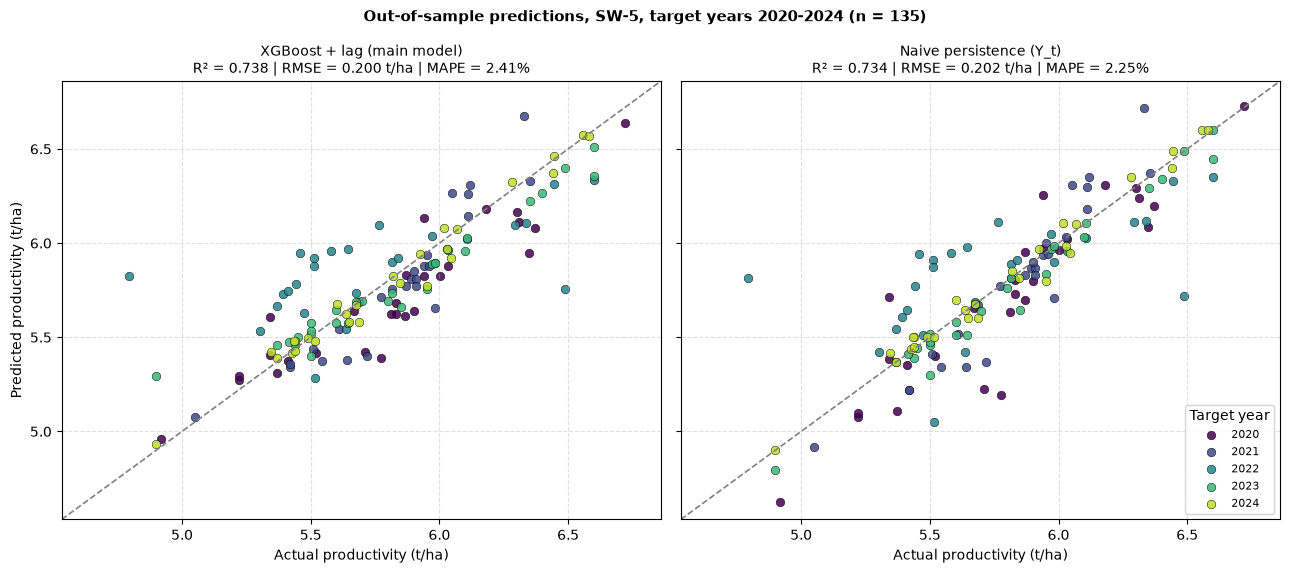

 -> Gambar tersimpan: actual_vs_predicted_xgb_lag.png


In [24]:
# =========================================================
# ACTUAL VS PREDICTED - MODEL UTAMA (XGBOOST + LAG) VS PERSISTENCE
# Prediksi out-of-sample Eksperimen 6: target perubahan, SW-5, nested Optuna,
# tahun target 2020-2024 (n = 135), pada produktivitas (ton/ha)
# =========================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error

print("Membangun Actual vs. Predicted untuk model utama...")

d_avp = lag_preds[(MAIN_W, MAIN_MODE, True)]
panels = [('pred', 'XGBoost + lag (main model)'), ('pred_persist', 'Naive persistence (Y_t)')]
years_avp = sorted(d_avp['YEAR_TARGET'].unique())
colors_avp = plt.cm.viridis(np.linspace(0, 0.9, len(years_avp)))
lo = min(d_avp['y_true'].min(), d_avp['pred'].min(), d_avp['pred_persist'].min()) * 0.98
hi = max(d_avp['y_true'].max(), d_avp['pred'].max(), d_avp['pred_persist'].max()) * 1.02

fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), sharex=True, sharey=True)
for ax, (col, label) in zip(axes, panels):
    for yr, colr in zip(years_avp, colors_avp):
        g = d_avp[d_avp['YEAR_TARGET'] == yr]
        ax.scatter(g['y_true'], g[col], s=38, color=colr, alpha=0.85,
                   edgecolors='black', linewidths=0.4, label=str(yr))
    ax.plot([lo, hi], [lo, hi], linestyle='--', color='grey', linewidth=1.2)
    r2 = r2_score(d_avp['y_true'], d_avp[col])
    rmse = np.sqrt(mean_squared_error(d_avp['y_true'], d_avp[col]))
    mape = mean_absolute_percentage_error(d_avp['y_true'], d_avp[col]) * 100
    ax.set_title(f"{label}\nR² = {r2:.3f} | RMSE = {rmse:.3f} t/ha | MAPE = {mape:.2f}%", fontsize=10)
    ax.set_xlabel('Actual productivity (t/ha)')
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.grid(True, linestyle='--', alpha=0.4)
axes[0].set_ylabel('Predicted productivity (t/ha)')
axes[1].legend(title='Target year', loc='lower right', fontsize=8)
plt.suptitle(f"Out-of-sample predictions, SW-{MAIN_W}, target years {years_avp[0]}-{years_avp[-1]} (n = {len(d_avp)})",
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig("actual_vs_predicted_xgb_lag.png", dpi=300, bbox_inches='tight')
plt.show()
print(" -> Gambar tersimpan: actual_vs_predicted_xgb_lag.png")
